# Drude model: 전류는 어떻게 흐를까?

Python 3.9+와 NumPy가 필요하다. Cell을 위에서부터 실행하면 된다. 그림은 notebook에 포함되어 있고, interactive example 링크는 글의 해당 예제로 연결된다. 연습문제 starter는 reference solution과 이름이 다르다.

[Read in English](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch/) · [Python 코드](https://pilkwangkim.github.io/assets/code/drude-model.py)

도선 양끝에 전압을 걸면 전기장이 생기고, 전자는 힘을 받는다. 이렇게 움직이는 전자들이 만드는 전류는 어떻게 계산할까? 전류의 크기는 전자가 얼마나 많이 있는지와, 전자들이 평균적으로 얼마나 빠르게 이동하는지에 달려 있다.

전기장은 전자들의 평균 이동, 즉 drift를 만들고, impurity나 격자 진동에 의한 scattering은 그 운동을 바꾼다. Drude model은 이 두 효과를 전자의 평균 속도에 대한 운동방정식으로 나타낸다. 전류가 전압에 비례하는 관계와 mobility는 이 식의 해에서 얻어진다.

## 1. 전하·전류 밀도, 전기장과 전하 보존


길이 $L$, 단면적 $A$인 균일한 도선을 생각하자. 좌표 $x$는 왼쪽 contact를 원점으로 잡고 오른쪽으로 갈수록 커지도록 정한다. 전자의 전하는 $-e$이고, $e$는 기본 전하의 크기다. $n(\mathbf r,t)$는 전류를 운반하는 전도전자의 수 밀도다. 원자핵 가까이에 묶인 core electron은 이 수에 포함하지 않는다.

전하 밀도를 구할 때는 전도전자의 음전하와 격자에 남는 전하를 따로 센다. 금속에서 원자핵의 양전하와 전도에 참여하지 않는 전자들의 음전하를 합치면 양전하가 남는다. 이 고정 양전하 밀도를 $+eN_D$로 쓰자. $N_D$는 그 밀도를 기본 전하로 나눈 값이다. 고정 양전하와 전도전자의 음전하가 정확히 상쇄되면 **charge neutrality**가 성립한다.

반도체에서는 dopant를 예로 들 수 있다. n형의 donor가 전자 하나를 내놓으면 격자에 남은 donor의 전하는 $+e$다. 반대로 p형의 acceptor가 전자를 받으면 격자에 음전하가 남고, 움직이는 hole은 양전하를 운반한다. 여기서는 전자가 전류를 운반하는 경우만 다룬다. [MIT 6.012, Introduction to Semiconductors](https://ocw.mit.edu/courses/6-012-microelectronic-devices-and-circuits-fall-2009/a37c73e7fcff4bcb5c5f1177e12d0891_MIT6_012F09_lec01.pdf)

도선을 기준으로, 한 시각에 작은 영역 안에 있는 전도전자들의 속도 벡터를 평균한 값을 $\mathbf u$라 쓰자. 이것이 **mean drift velocity**다. 예를 들어 왼쪽과 오른쪽으로 같은 수의 전자가 같은 속력으로 움직이면, 전자는 모두 움직이고 있어도 평균 속도는 0이다.

오른쪽으로 지나간 전자 수에서 왼쪽으로 지나간 전자 수를 빼 보자. 단면 전체에서 전자 밀도와 drift가 균일하다면, 짧은 시간 $\Delta t$ 동안 단면적 $A$를 지난 전자 수의 차이는 $nAu_x\Delta t$다. 여기에 전자 한 개의 전하를 곱하면 단면을 통과한 순전하량 $\Delta Q=-enAu_x\Delta t$가 된다. 이 값을 $\Delta t$로 나눈 것이 전류다. 양전하가 오른쪽으로 움직일 때를 양의 전류로 정하므로, **conventional current**의 방향은 전자의 평균 이동 방향과 반대다. 순전하 밀도 $\rho$는 고정 양전하와 전도전자의 음전하를 더한 값이다. 이를 전류 밀도 $\mathbf J$, 단면을 지나는 전류와 함께 쓰면 다음과 같다.

$$
\begin{aligned}
&\rho=e(N_D-n),\\
&\mathbf J=-en\mathbf u,\\
&I=\int_A\mathbf J\cdot d\mathbf A.
\end{aligned}
\tag{1}
$$

$n$의 단위는 $\mathrm{m}^{-3}$, $\rho$는 $\mathrm{C/m^3}$, $\mathbf u$는 $\mathrm{m/s}$, $\mathbf J$는 $\mathrm{A/m^2}$다. 전류 $I$의 단위는 암페어(A)다. 전자들이 평균적으로 음의 $x$ 방향(왼쪽)으로 움직이면 전류는 양수다. 단면 전체에서 전류 밀도가 균일하면 $I=AJ_x$다.

**Electrostatic potential** $\varphi$의 단위는 볼트(V)다. 전기장은 $\mathbf E=-\nabla\varphi$이므로 전위가 낮아지는 쪽을 향한다. 이 전기장에서 전자가 받는 힘은 $-e\mathbf E$다. 전도전자를 제외한 물질의 전기적 응답을 선형 유전체로 근사하고, **permittivity**를 $\varepsilon=\varepsilon_0\varepsilon_b$라 쓰자.

$$
\begin{aligned}
&\nabla\cdot(\varepsilon\mathbf E)=\rho,\\
&-\nabla\cdot(\varepsilon\nabla\varphi)=\rho.
\end{aligned}
\tag{2}
$$

두 번째 식이 **Poisson equation**이다. $\varepsilon_0$는 진공의 permittivity이고, $\varepsilon_b$는 배경 물질의 분극을 나타내는 상대 유전율이다. 전도전자의 전하는 이미 $\rho$에 들어 있으므로, 전도전자의 응답을 배경의 유전율에 또 넣지 않는다. 여기서는 관심 주파수 범위에서 배경 유전율을 일정한 양의 실수로 둔다. 전기장과 전위도 원자 하나하나를 분해해 보는 값이 아니라, 여러 격자 간격에 걸쳐 평균한 값이다.

1차원에서 전위의 기울기는 $\partial_x\varphi$, 전기장의 발산은 $\partial_xE_x$다. 작은 구간의 양쪽 경계에서 바깥 방향을 기준으로 전기장 flux를 더한 값이 양수라면, 그 구간에서 전기장이 발산한다는 뜻이다. $\mathbf E$의 단위는 $\mathrm{V/m}$, $\varepsilon$의 단위는 $\mathrm{F/m}$이므로 식 (2)의 양변은 모두 단위 부피당 전하량이다.

Poisson equation은 전하 분포와 전위의 공간 변화를 연결한다. 같은 전하 분포라도 양끝에 어떤 전압을 거느냐에 따라 전기장이 달라지므로, 전위를 구하려면 **boundary condition**도 필요하다. 전기장이 정해져도 전자들이 얼마나 빠르게 이동하는지는 별개의 문제다. [Haus and Melcher, Chs. 4 and 7](https://web.mit.edu/6.013_book/www/chapter7/7.html)

**Continuity equation**은 한 구간 안의 전자 수가 얼마나 빨리 변하는지를 나타낸다. 전도전자가 생성되거나 재결합 또는 포획으로 줄어드는 과정이 없다면, 구간 안의 전도전자 수는 경계로 들어온 수만큼 늘고 나간 수만큼 줄어든다. **Particle flux**는 단위 시간에 단위 면적을 지나는 입자 수를 방향에 따라 부호를 붙여 더한 값이다. 단면적이 일정하면, 왼쪽과 오른쪽 경계의 flux 차이에 단면적을 곱해 구간 안의 전자 수가 변하는 속도를 구한다.

$$
\frac{d}{dt}\big[nA\,\Delta x\big]
=A(nu_x)_{x}-A(nu_x)_{x+\Delta x}
$$

이 식을 구간의 부피 $A\Delta x$로 나누고 $\Delta x\to0$의 극한을 취한다. 3차원에서는 다음과 같이 쓴다.

$$
\begin{aligned}
&\partial_t n+\nabla\cdot(n\mathbf u)=0,\\
&\partial_t\rho+\nabla\cdot\mathbf J=0.
\end{aligned}
\tag{3}
$$

$N_D$가 고정되어 있고 $\mathbf J=-en\mathbf u$이므로, 전자 수에 대한 첫 번째 식을 전하에 대한 두 번째 식으로 바꿔 쓸 수 있다. 전자가 구간 안에서 방향을 바꾸는 것만으로는 전자 수가 달라지지 않는다. 전자가 경계를 넘어야 구간 안의 수가 바뀐다.

전하 보존을 숫자로 확인해 보자. 한 구간의 왼쪽으로 들어오는 전류가 $2\,\mu\mathrm A$, 오른쪽으로 나가는 전류가 $1\,\mu\mathrm A$인 상태가 $1\,\mathrm{ns}$ 동안 이어지면, 그동안 구간 안에 쌓인 순전하량은

$$
\begin{aligned}
&\Delta Q=(I_{\rm left}-I_{\rm right})\Delta t\\
&=(2-1)\,\mu\mathrm A\times1\,\mathrm{ns}\\
&=+10^{-15}\,\mathrm C.
\end{aligned}
$$

양전하는 그대로인데 순전하가 늘었다. 따라서 전자 수가 $\Delta Q/e\simeq6.24\times10^3$만큼 줄었다는 뜻이다. 전자의 순이동 방향은 전류와 반대다. 오른쪽 경계에서는 들어오는 쪽이, 왼쪽 경계에서는 나가는 쪽이 우세하고, 둘을 합치면 전자가 줄어든다. 두 경계의 전류 차이가 유지되는 동안에는 구간 안의 전하량이 계속 바뀐다. 따라서 **정상상태(steady state)**가 아니다.


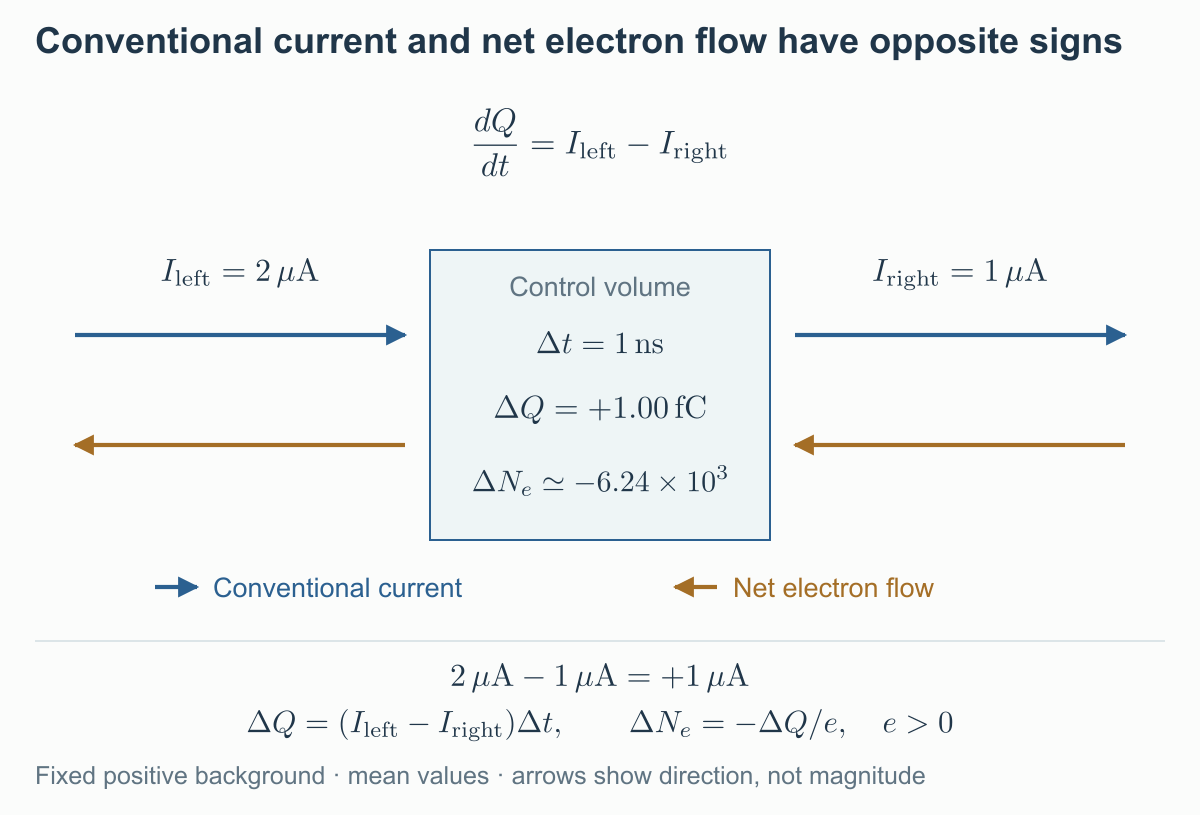

*그림 1. 파란색은 conventional current, 금색은 전자의 순이동 방향이다. 두 경계 모두 오른쪽($+x$)을 양의 방향으로 잡았다. $I_{\rm left}=2\,\mu\mathrm A$와 $I_{\rm right}=1\,\mu\mathrm A$가 $1\,\mathrm{ns}$ 동안 흐르면 구간 안의 전하는 $\Delta Q=+10^{-15}\,\mathrm C$만큼 늘고, 전자 수는 $\Delta N_e=-\Delta Q/e\simeq-6.24\times10^3$만큼 변한다.*


| 관계식 | 정하는 것 | 이 식만으로 정하지 못하는 것 |
|---|---|---|
| Poisson equation | 전하와 boundary condition에 따른 전기장 | 전자의 drift |
| Continuity equation | 들어오고 나간 flux의 차이에 따른 입자 수 변화 | 주어진 전기장에서의 전류 |
| Transport 관계식 | 전기장에 따른 carrier의 운동과 전류 | Electrostatic boundary condition |


Drude model은 이 가운데 전기장과 전류를 잇는 세 번째 관계식을 준다.

## 2. Charge-neutral 도선의 전기장과 boundary condition


도선 내부에서 $n=N_D$로 전하가 상쇄되고 permittivity는 일정하다고 하자. Poisson equation에 따르면 $\partial_xE_x=0$이다. 전기장이 **위치에 따라 변하지 않는다**는 뜻이지, **$E_x=0$**이라는 뜻은 아니다. 왼쪽 contact의 전위를 $\varphi(0)=V$, 오른쪽 contact의 전위를 $\varphi(L)=0$으로 정하면 다음과 같다.

$$
\begin{aligned}
&\varphi(x)=V\left(1-\frac{x}{L}\right),\\
&E_x=\frac{V}{L},\\
&\rho=0.
\end{aligned}
\tag{4}
$$

$V>0$이면 전위가 왼쪽에서 오른쪽으로 낮아지므로 전기장은 오른쪽을 향한다. 전극과 표면전하가 양끝의 전위를 정해 주기 때문에, 도선 내부에 순전하가 없어도 전기장이 생겨 전자에 힘을 가할 수 있다.

Steady state에서는 continuity equation에 따라 $\partial_xJ_x=0$도 성립해야 한다. 즉, 도선의 어느 단면에서나 전류가 같아야 한다. 하지만 이 조건만으로 전류의 크기는 알 수 없다. 완전한 절연체와 좋은 도체가 같은 정적 Poisson equation을 만족해도 전류는 크게 다를 수 있다. 두 물질에서 전기장과 전류를 연결하는 transport 관계식이 다르기 때문이다.

도체 내부의 전기장이 0이라는 설명은 전하가 재배치되고 전류가 더 이상 흐르지 않는 **electrostatic equilibrium**에 관한 것이다. 반면 여기서는 외부 전원이 전압을 유지하므로 전류가 계속 흐른다. **Steady state**에서 전기장과 전류는 시간에 따라 변하지 않지만, 그 값이 0일 필요는 없다.

그림 2의 (b)와 (c)를 보면, 전위가 일정한 기울기로 낮아지는 구간에서 전기장은 일정한 양수다. 이 전기장에서 전자들이 어떻게 움직이는지 알아야 전류의 크기도 구할 수 있다.


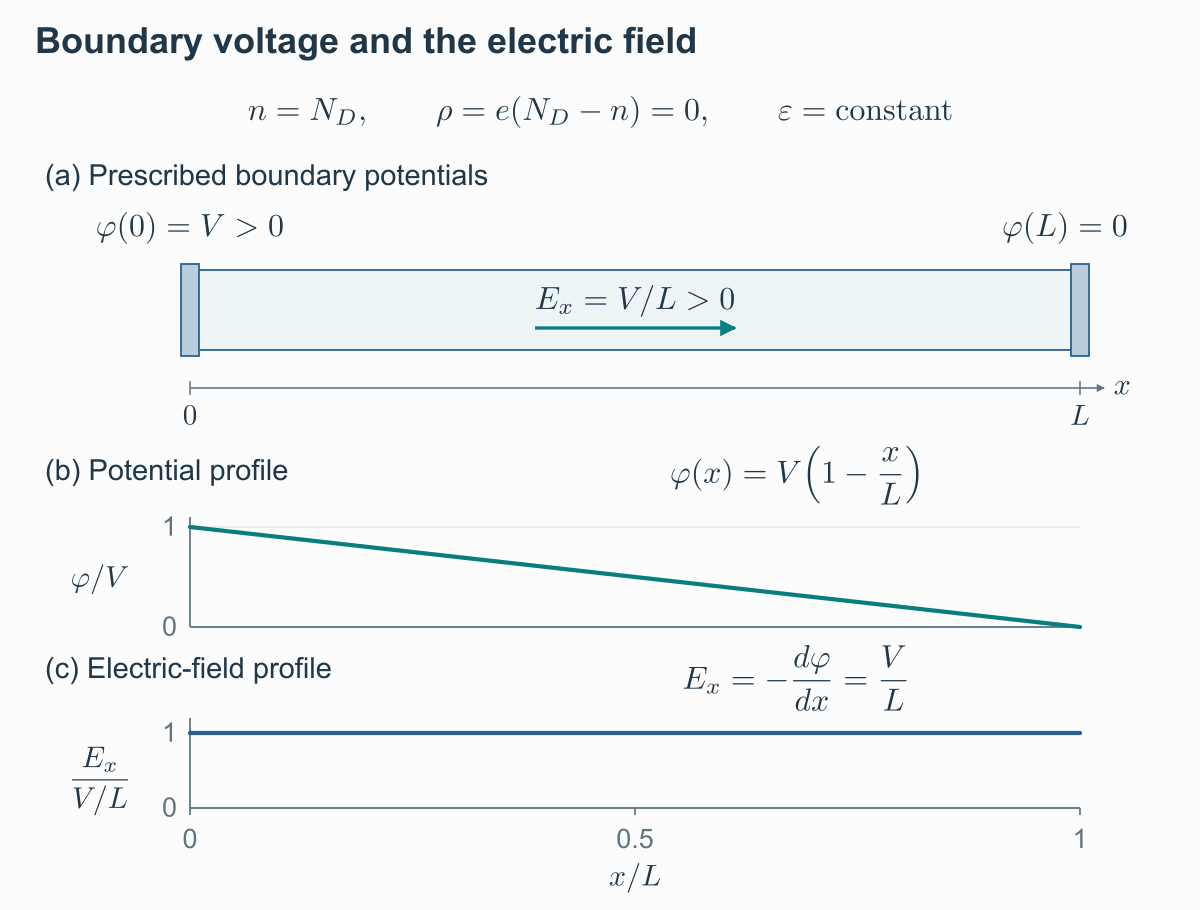

*그림 2. (a) 사각형은 도선 내부의 균일한 구간이다. 양끝의 세로 막대는 전위를 정해 둔 경계, 내부 화살표는 전기장을 뜻한다. (b) 전위는 오른쪽으로 갈수록 일정한 기울기로 낮아진다. (c) 전기장은 전위 기울기의 음수이므로 같은 구간에서 일정한 양수다. $\rho=0$이면 전기장의 발산은 0이지만, 전기장 자체가 0일 필요는 없다.*




**밀도가 균일하지 않으면 무엇이 달라질까?**


고정 양전하의 분포는 그대로인데 전도전자 밀도만 달라지면, 두 전하가 상쇄되지 않는 곳에서 전기장이 위치에 따라 달라진다. 밀도 차이 때문에 전자가 퍼지는 diffusion도 생기므로, drift만 포함한 $\mathbf J=\sigma\mathbf E$로는 평형이나 전류를 구하기 어려울 수 있다. 전자 기체의 single-particle state들이 대부분 비어 있어 각 상태의 점유 확률이 충분히 낮으면, Maxwell–Boltzmann 통계를 쓸 수 있다. 이런 기체를 **nondegenerate**라고 한다. 온도를 일정하게 두면 전류에 drift 항 $en\mu\mathbf E$ 외에 diffusion 항 $+eD\nabla n$이 들어간다. $\mu$는 4절에서 정의할 mobility이고, $D$는 단위가 $\mathrm{m^2/s}$인 diffusion coefficient다. 전자는 밀도가 낮은 쪽으로 퍼지지만 음전하를 띠므로, diffusion 전류는 밀도가 높아지는 방향을 향한다.

균일한 도선에서는 밀도 차이가 없으므로 diffusion 항이 사라진다. 19절에서는 작은 전하 진동을 다루되, 파장이 길어 압력의 영향을 무시할 수 있는 경우에 한해 식을 선형화한다. 두 예제 모두 일반적인 drift–diffusion 소자 모형보다 범위가 좁다.



## 3. 전자들의 평균 속도를 정하는 Drude 방정식


도선 내부의 균일한 구간을 잡고 전자 밀도가 일정하다고 하자. $t=0$에 일정한 외부 전기장 $\mathbf E_0$를 켠다. 처음에는 한쪽으로 치우친 운동이 없어 $\mathbf u(0)=0$이다. 이 구간 안에서 평균 속도가 어떻게 바뀌는지만 계산하므로, contact에서 들어오는 전자나 회로를 따라 전기장이 전달되는 과정은 포함하지 않는다.

### Scattering이 없을 때의 평균 속도와 전류

운동방정식에 들어가는 양의 질량을 $m^{\ast}$라 쓰자. 자유전자라면 $m^{\ast}=m_0$이고, $m_0$는 전자의 bare mass다. Scattering이 없으면 모든 전자가 전기장으로부터 같은 가속도를 얻는다. 따라서 속도를 평균한 값도 같은 가속도로 바뀐다. 이 가속도를 시간에 대해 적분한 뒤 식 (1)에 대입하면 다음을 얻는다.

$$
\begin{aligned}
&\frac{d\mathbf u}{dt}=-\frac{e}{m^{\ast}}\mathbf E_0,\\
&\mathbf u(t)=-\frac{e}{m^{\ast}}\mathbf E_0t,\\
&\mathbf J(t)=\frac{ne^2}{m^{\ast}}\mathbf E_0t.
\end{aligned}
$$

Scattering이 없으면 전기장을 두 배 오래 걸었을 때 전류도 두 배가 된다. 실제 도선에서 전류가 일정해지는 이유를 설명하려면, 전기장이 만들어 낸 평균 drift를 줄이는 과정이 필요하다.

### Scattering에 의한 평균 속도의 relaxation

물질 안의 전자는 impurity나 격자 진동과도 상호작용한다. 이때 전자의 방향이나 에너지가 바뀌는 과정을 **scattering**이라 한다. 평균 속도를 줄이기 위해 전자를 모두 멈출 필요는 없다. 한쪽 방향으로 치우쳐 있던 전자들을 여러 방향으로 흩어 놓으면, 개별 전자의 속력은 커도 평균 속도는 작아질 수 있다.

짧은 시간 $dt\ll\tau$ 동안 전자 하나가 scattering을 겪을 확률을 1차 근사에서 $dt/\tau$로 두자. 여기서 $\tau>0$는 이 모형에서 scattering 사이의 평균 시간이다. 이전에 언제 scattering을 겪었는지는 다음 사건의 확률에 영향을 주지 않는다고 가정한다. Scattering 직후에는 진행 방향이 완전히 흩어져, scattering을 겪은 전자들의 평균 속도가 0이 된다고 놓는다.

Scattering을 겪지 않은 전자들의 평균 속도에는 전기장이 만든 변화 $-e\mathbf E\,dt/m^{\ast}$가 더해진다. 이 집단의 비율은 $1-dt/\tau$다. Scattering을 겪은 전자들도 사건 직후 남은 시간 동안 다시 가속한다. 하지만 그 시간이 길어야 $dt$이고 scattering 확률도 이 시간 간격에 비례하므로, 두 효과를 곱하면 전체 평균에 대한 기여는 $dt^2$ 차수다.

두 집단의 평균 속도에 각각의 비율을 곱해 더한 뒤 $dt$의 1차 항까지만 남긴다.

$$
\begin{aligned}
&\mathbf u(t+dt)=\left(1-\frac{dt}{\tau}\right)\mathbf u(t)\\
&\qquad-\frac{e\mathbf E}{m^{\ast}}dt+\mathcal O(dt^2).
\end{aligned}
\tag{5}
$$

양변에서 $\mathbf u(t)$를 빼고 $dt$로 나눈 뒤 $dt\to0$의 극한을 취하자. 질량을 곱하면 **Drude equation of motion**을 얻는다.

$$
m^{\ast}\frac{d\mathbf u}{dt}
=-e\mathbf E-\frac{m^{\ast}}{\tau}\mathbf u.
\tag{6}
$$

첫 항은 전기력이다. 두 번째 항은 scattering이 전자의 진행 방향을 흩어 평균 속도를 줄이는 효과다. 가령 평균 속도가 왼쪽을 향하면 두 번째 항은 오른쪽을 향한다. [TU Delft, Drude equation of motion](https://solidstate.quantumtinkerer.tudelft.nl/3_drude_model/)

높은 곳에서 물체를 떨어뜨리면 처음에는 속력이 커진다. 공기 저항이 커질수록 가속도는 줄고, 위아래 힘이 균형을 이루는 종단속도에 가까워진다. 점성이 큰 액체 속에서 작은 구슬이 천천히 떨어질 때는 저항을 속도에 비례한다고 근사할 수 있다. 이 경우 중력에서 부력을 뺀 일정한 힘과 선형 저항이 맞서므로 운동방정식의 형태도 Drude 방정식과 같다. [OpenStax, 종단속도와 선형 저항](https://openstax.org/books/university-physics-volume-1/pages/6-4-drag-force-and-terminal-speed)

전기장을 일정하게 유지할 때 평균 drift가 일정한 값에 가까워지는 것도 이와 같다. 다만 구슬에는 실제 저항력이 작용하는 반면, Drude 식의 두 번째 항은 개별 전자에 작용하는 마찰력이 아니다. 전자들이 scattering을 겪으며 한쪽 방향으로 치우친 운동이 평균적으로 줄어드는 효과다. 여기서 일정해지는 것은 **고정된 전기장에서 시간이 지났을 때의 평균 속도**다. 전기장을 더 세게 해도 drift 속력이 더 이상 늘지 않는 강전기장 velocity saturation과는 다른 이야기다.

전기장을 끄면 식 (6)에는 $d\mathbf u/dt=-\mathbf u/\tau$만 남고, 해는 $\mathbf u(t)=\mathbf u(0)e^{-t/\tau}$다. $\tau$는 평균 drift가 사라지는 속도를 나타낸다. 전기장을 끄고 $\tau$만큼 지나면 평균 속도의 크기는 처음의 $e^{-1}$배가 된다. 이 시간을 **momentum relaxation time**이라 하며, $\tau_{\rm tr}$라고도 쓴다.

Scattering 한 번으로 원래 방향을 완전히 잊는 모형에서는 relaxation time과 사건 사이의 평균 시간이 같다. 실제로는 scattering을 겪고도 원래 진행 방향의 성분이 일부 남을 수 있다. 이 경우 식 (6)과 같은 형태를 쓰더라도, $\tau$는 사건이 얼마나 자주 일어나는지가 아니라 평균 drift가 얼마나 빨리 줄어드는지로 정한다. 두 시간의 차이는 14절에서 계산한다.

지금까지는 위치에 관계없이 같은 전기장과 평균 속도를 쓰고, 감쇠는 평균 속도에 비례한다고 놓았다. 밀도나 압력 차이가 운동을 일으키는 경우, 또는 영역 사이에서 운동량이 전달되는 경우는 다루지 않는다. 결정에서는 전자의 bare mass $m_0$ 대신 방향에 따라 달라지지 않는 양의 질량 $m^{\ast}$를 쓸 수 있는 조건이 따로 있다(7–9절).


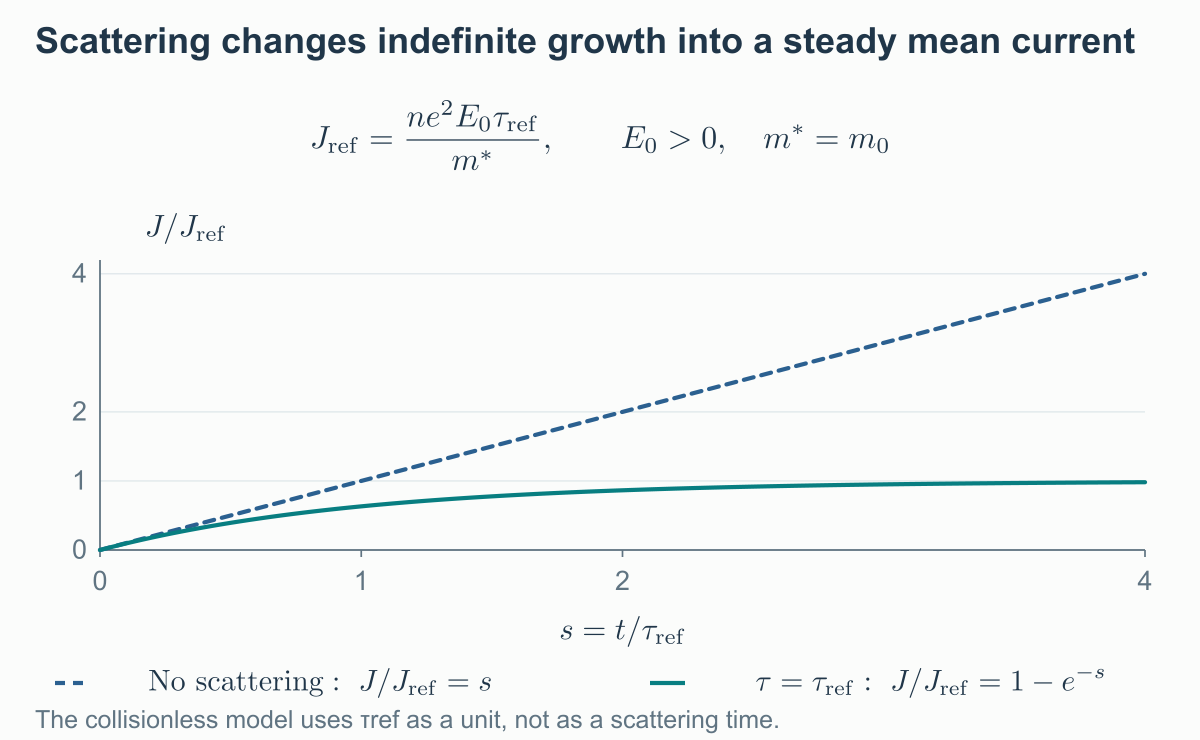

*그림 3. 두 경우 모두 같은 전기장을 걸고, 평균 drift가 0인 상태에서 시작한다. 질량은 $m^{\ast}=m_0$다. 가로축은 $s=t/\tau_{\rm ref}$, 세로축은 전류 밀도를 $J_{\rm ref}=ne^2E_0\tau_{\rm ref}/m^{\ast}$로 나눈 값이다. 점선은 scattering이 없을 때, 실선은 $\tau=\tau_{\rm ref}$일 때다. 점선에서 기준 시간 $\tau_{\rm ref}>0$는 두 곡선을 같은 축에 놓는 데 쓰일 뿐, scattering time이 아니다.*


## 4. DC mobility, conductivity와 channel resistance


전기장을 켜고 충분히 기다렸을 때의 평균 속도를 $\mathbf u_{\rm dc}$라 쓰자. 아래첨자 DC는 직류(direct current)를 뜻한다. 정상상태에서는 속도가 더 이상 변하지 않아 $d\mathbf u/dt=0$이므로, 식 (6)에서 전기력과 감쇠 항이 상쇄된다.

$$
0=-e\mathbf E-\frac{m^{\ast}}{\tau}\mathbf u_{\rm dc}.
$$

이 식을 풀면 $\mathbf u_{\rm dc}=-e\tau\mathbf E/m^{\ast}$다. 이 속도를 $\mathbf J=-en\mathbf u$에 대입하면 $\mathbf J=(ne^2\tau/m^{\ast})\mathbf E$다. 전자의 drift는 전기장과 반대이고, 음전하가 만드는 전류의 방향은 drift와 다시 반대이므로 전류는 전기장과 같은 방향이다. 정상상태의 drift 속력과 전기장 세기의 비를 DC **mobility** $\mu$, 전류 밀도와 전기장을 잇는 비례계수를 DC **conductivity** $\sigma_0$라 한다. 전도전자 밀도 $n$을 고정하면 다음과 같다.

$$
\begin{aligned}
&\mathbf u_{\rm dc}=-\mu\mathbf E,\\
&\mu=\frac{e\tau}{m^{\ast}},\\
&\mathbf J=\sigma_0\mathbf E,\\
&\sigma_0=en\mu=\frac{ne^2\tau}{m^{\ast}}.
\end{aligned}
\tag{7}
$$

질량이 양수인 이 모형에서 mobility $\mu$는 양수다. $\mathbf u=-\mu\mathbf E$의 음의 부호는 전자의 drift 방향을 나타낸다. Conductivity $\sigma_0$는 전자를 얼마나 쉽게 움직일 수 있는지뿐 아니라, 전류를 운반할 전자가 얼마나 많은지에도 달려 있다. 그래서 mobility가 높더라도 전자 밀도가 낮으면 conductivity는 낮을 수 있다.

전류가 $\mathbf E$에 비례하려면 전기장이 전자들의 속도 분포를 크게 바꾸지 않아야 한다. 전기장에 비례하는 1차 항만으로 충분한 범위가 **linear response**가 성립하는 **low-field** 영역이다. 이때는 전기장을 걸기 전의 전자 밀도와 질량을 그대로 쓸 수 있고, 가열이나 scattering의 변화로 $\tau$가 크게 달라지지 않는다. 결정에서는 전류에 기여하는 에너지 범위에서 질량을 일정하게 근사할 수 있어야 한다(7–9절). 이 조건을 만족하는 전기장의 범위는 물질마다 다르다.

Mobility의 SI 단위는 $\mathrm{m^2/(V\,s)}$다. $\mathrm{cm^2/(V\,s)}$로 바꾸려면 $10^4$를 곱한다. 밀도 단위는 반대 방향으로 환산되어 자주 헷갈린다. $1\,\mathrm{cm}^{-3}=10^6\,\mathrm{m}^{-3}$다.

Drude conductivity에서 밀도가 크다는 것은 전하를 나를 전자가 많다는 뜻이다. Relaxation time이 길면 전기장이 만든 drift가 천천히 줄어들어 정상상태의 평균 속력이 커진다. 반대로 질량이 크면 같은 전기력에서 가속도가 작아진다.

도선의 전류를 구하려면 식 (4)의 균일한 전기장 $E_x=V/L$과 식 (1)의 단면 관계 $I=AJ_x$를 쓰면 된다. 따라서 $I=A\sigma_0E_x=A\sigma_0V/L$이다. 저항을 $R=V/I$로 정의하면

$$
\begin{aligned}
&I=\frac{\sigma_0A}{L}V,\\
&R=\frac{L}{\sigma_0A},\\
&\varrho_{\rm el}=\frac{1}{\sigma_0}.
\end{aligned}
\tag{8}
$$

**Resistivity** $\varrho_{\rm el}$의 단위는 $\Omega\,\mathrm m$다. 기호가 비슷하지만 전하 밀도 $\rho$와는 다른 물리량이다. Resistivity가 같은 도선이라도 길수록 저항이 크고, 단면적이 넓을수록 저항이 작다. $n,m^{\ast},\tau$가 일정하면 $I$–$V$ 그래프는 직선이다. 가열이나 전자 밀도 변화, 강전기장에서의 velocity saturation, contact의 영향이 큰 ballistic transport 등에서는 이 직선 관계를 그대로 쓸 수 없다.


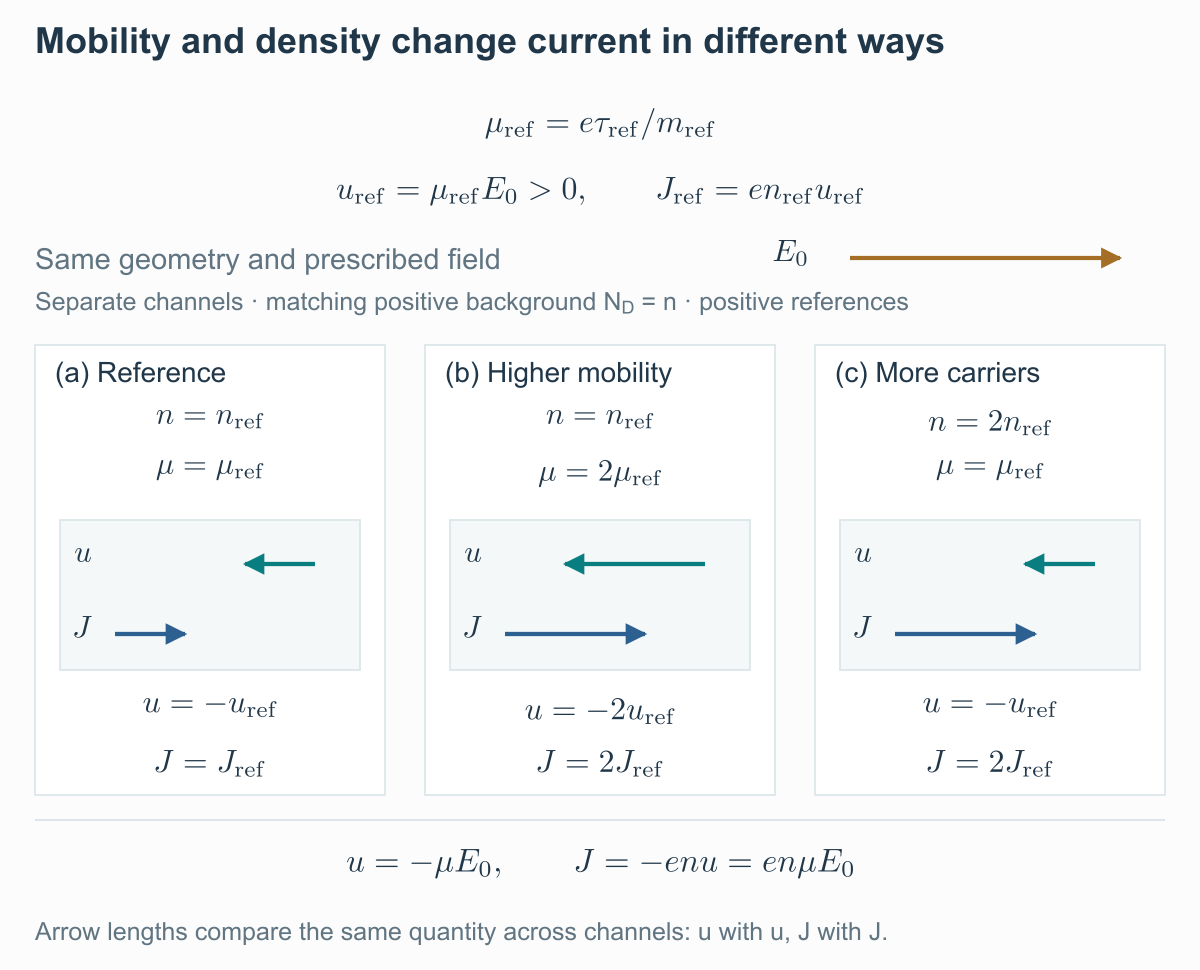

*그림 4. 같은 크기의 도선 세 개에 같은 전기장 $E_0>0$을 걸었다. 도선마다 고정 양전하 밀도를 전도전자 밀도에 맞춰 $N_D=n$으로 두었다. 기준값은 $\mu_{\rm ref}=e\tau_{\rm ref}/m_{\rm ref}$, $u_{\rm ref}=\mu_{\rm ref}E_0$, $J_{\rm ref}=en_{\rm ref}u_{\rm ref}$다. 밀도를 그대로 두고 mobility를 두 배로 하면 drift 속력과 전류 밀도가 모두 두 배가 된다. Mobility는 그대로 두고 밀도만 두 배로 하면 전류 밀도만 두 배가 된다. Drift는 전기장과 반대 방향, conventional current는 같은 방향이다. 화살표 길이는 같은 물리량끼리 비교한다.*


전자가 처음 진행하던 방향의 영향을 잃기까지 이동하는 대표 거리를 **transport mean free path**라고 한다. 전자 한 개가 움직이는 대표 속력에 momentum relaxation time을 곱해 구한다. 서로 다른 방향의 운동을 평균하고 남은 작은 drift 속력을 쓰는 것이 아니다. 도선이 이 거리보다 충분히 길면 전자는 건너편에 닿기 전에 원래 진행 방향을 잃는다(**diffusive transport**). 반면 **ballistic transport**에서는 scattering이 전자의 통과에 거의 영향을 주지 않는다. 이때는 도선 내부의 저항 식만으로 전류를 구할 수 없고, contact에서 어떤 전자가 들어오는지도 알아야 한다.

예를 들어 $n=10^{23}\,\mathrm{m}^{-3}$, $m^{\ast}=0.2m_0$, $\tau=100\,\mathrm{fs}$, $E_x=1000\,\mathrm{V/m}$이라 하자. 1 펨토초(fs)는 $10^{-15}$초다. 길이 $L=1\,\mu\mathrm m$, 단면적 $A=(100\,\mathrm{nm})^2$인 도선에서는 다음 값을 얻는다.

$$
\begin{aligned}
&\mu=0.087941\,\mathrm{m^2/(V\,s)}\\
&=879.41\,\mathrm{cm^2/(V\,s)},\\
&u_x=-87.941\,\mathrm{m/s},\\
&\sigma_0=1408.97\,\mathrm{S/m},\\
&V=1\,\mathrm{mV},\\
&I=14.0897\,\mathrm{nA},\\
&R=70.9738\,\mathrm{k\Omega}.
\end{aligned}
$$

코드는 Python 3.9 이상과 NumPy가 필요하며 위에서부터 순서대로 실행한다. Notebook에도 같은 코드와 그림이 들어 있다. 물리 상수는 [NIST CODATA 값](https://physics.nist.gov/cuu/Constants/Table/allascii.txt)을 사용한다.


In [1]:
import numpy as np
from math import gamma

E_CHARGE = 1.602176634e-19   # Positive e, in C; electron charge is -e.
HBAR = 6.62607015e-34 / (2 * np.pi)
M0 = 9.1093837139e-31
KB = 1.380649e-23
EPS0 = 8.8541878188e-12

n, mass, tau = 1e23, 0.2 * M0, 100e-15
field, length, area = 1000.0, 1e-6, (100e-9)**2
mobility = E_CHARGE * tau / mass
sigma0 = n * E_CHARGE * mobility
drift = -mobility * field
voltage, current = field * length, sigma0 * field * area
print("mobility (cm^2/Vs):", mobility * 1e4)
print("drift (m/s), current (nA):", drift, current * 1e9)
print("channel resistance (kohm):", voltage / current / 1e3)
assert np.isclose(current * 1e9, 14.0897016)
assert np.isclose(current, -E_CHARGE * n * drift * area)


mobility (cm^2/Vs): 879.4100041889992
drift (m/s), current (nA): -87.94100041889992 14.089701604174564
channel resistance (kohm): 70.97382386747745


**이 예제의 전기장은 충분히 약하고 도선은 충분히 길까?**


Carrier의 대표 운동에너지를 $K_{\rm char}=50\,\mathrm{meV}$로 정하고, 앞 예제의 $m^{\ast}=0.2m_0$, $\tau=100\,\mathrm{fs}$, $E_x=1000\,\mathrm{V/m}$을 유지하자. 대표 속력과 transport mean free path는

$$
\begin{aligned}
&v_{\rm char}=\sqrt{\frac{2K_{\rm char}}{m^{\ast}}}\\
&\simeq2.9655\times10^5\,\mathrm{m/s},\\
&\ell_{\rm char}=v_{\rm char}\tau\simeq29.65\,\mathrm{nm}.
\end{aligned}
$$

Low-field 근사가 타당한지 확인하려면 이 거리를 이동하는 동안 전기장이 하는 일을 carrier의 에너지와 비교해 볼 수 있다.

$$
e\lvert E_x\rvert\ell_{\rm char}\simeq0.02965\,\mathrm{meV}
\ll K_{\rm char}.
$$

도선 길이 $L=1\,\mu\mathrm m$는 이 에너지에서 transport mean free path의 약 34배다. 따라서 전자가 방향을 거의 바꾸지 않은 채 도선을 건너는 ballistic 조건과는 거리가 있다. 전자들의 에너지 범위가 넓다면 전류를 주로 운반하는 전자들의 mean free path를 비교해야 한다. 이 계산은 전기장이 전자의 에너지를 얼마나 바꾸는지에 대한 점검이다. 온도를 일정하게 유지하려면 전자가 얻은 에너지를 외부로 내보내는 과정도 필요하다.



## 5. 전기장을 켜고 끌 때의 전류 변화


전류는 전기장을 켜자마자 정상상태 값에 도달하지 않는다. 평균 속도가 $\mathbf u(0)=0$인 상태에서 $t=0$에 전기장 $\mathbf E_0$를 켜 보자. 식 (6)을 $d\mathbf u/dt=-(\mathbf u-\mathbf u_{\rm dc})/\tau$로 쓰면, 정상상태 속도에서 벗어난 양이 지수적으로 줄어든다는 것을 알 수 있다.

$$
\begin{aligned}
&\mathbf u(t)=-\frac{e\tau}{m^{\ast}}\mathbf E_0(1-e^{-t/\tau}),\\
&\mathbf J(t)=\sigma_0\mathbf E_0(1-e^{-t/\tau}).
\end{aligned}
\tag{9}
$$

$t=\tau$에서 전류는 정상상태 값의 $1-e^{-1}\simeq0.6321$에 도달한다. 전기장을 끄면 그 순간의 전류에서 시작해 지수적으로 줄어든다. 이때 시간은 전기장을 끈 순간부터 다시 잰다.

아주 이른 시간에는 $1-e^{-t/\tau}\simeq t/\tau$다. 따라서 $J(t)\simeq ne^2E_0t/m^{\ast}$로, 3절에서 구한 scattering 없는 경우의 전류 증가와 같다. 아직 scattering이 평균 운동에 큰 영향을 줄 만큼 시간이 지나지 않았기 때문이다. 초기 기울기는 $\tau$와 무관하다. Relaxation time이 길어지면 최종 전류도 커지고 그 값에 가까워지는 데 걸리는 시간도 길어진다. 같은 전기장이 주는 순간적인 가속도 자체가 달라지는 것은 아니다.


In [2]:
s = np.linspace(0, 6, 121)  # Dimensionless time s=t/tau.
j_on = -np.expm1(-s)       # J/(sigma0*E0); accurate near s=0.
j_off = np.exp(-s)         # J/J_at_switch_off, with a new time origin.
assert np.isclose(-np.expm1(-1.0), 0.6321205588)
assert np.allclose(j_on + j_off, 1.0)
print("Turn-on fraction at 1 tau:", -np.expm1(-1.0))


Turn-on fraction at 1 tau: 0.6321205588285577


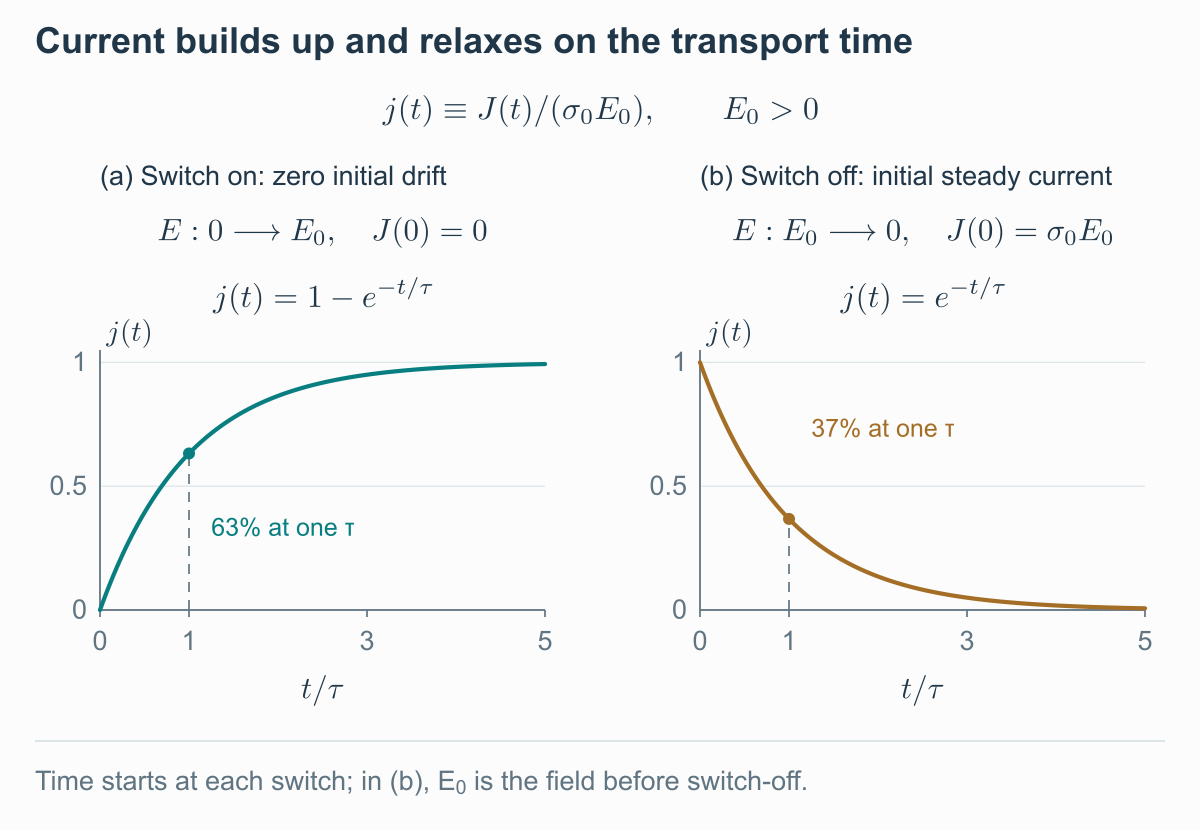

*그림 5. (a) 평균 drift가 0인 상태에서 전기장 $E_0>0$을 켜면 전류가 $\sigma_0E_0$에 가까워진다. (b) 전류가 충분히 안정된 뒤 전기장을 끄면 전류는 지수적으로 줄어든다. 이 패널의 $E_0$는 끄기 전의 전기장이다. 두 패널은 각각 켠 순간과 끈 순간부터 시간을 재며, 같은 momentum relaxation time을 사용한다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-step)


$\tau$와 $m^{\ast}$를 각각 바꾸어 mobility와 최종 전류를 비교해 보자. 시간축은 ps, 세로축은 A/m² 단위로 고정했다. $\tau$를 바꾸면 전류가 커지는 데 걸리는 시간과 최종 전류가 함께 달라진다. 식 (9)의 초기 기울기는 $dJ/dt=ne^2E_0/m^{\ast}$이므로 $\tau$와 무관하다. 물질의 매개변수를 바꿔도 축은 자동으로 늘어나지 않는다. 전류 축 범위는 별도 메뉴에서 세 가지 중 하나를 직접 고르며, 범위를 벗어난 곡선은 경계에서 끊고 표시한다. 전기장 방향을 뒤집으면 전류와 electron drift의 부호도 바뀐다. Channel의 길이와 단면적은 그대로다.



**전기장이 한 일은 어디로 갈까?**


$n$이 일정할 때 식 (6)에 $n\mathbf u$를 내적하면

$$
\begin{aligned}
&\frac{d}{dt}\left(\frac{nm^{\ast}u^2}{2}\right)\\
&=\mathbf J\cdot\mathbf E-\frac{nm^{\ast}u^2}{\tau}.
\end{aligned}
\tag{10}
$$

오른쪽 첫 항은 전기장이 단위 부피에 공급하는 전력이다. 두 번째 항은 한쪽으로 치우친 평균 운동에 해당하는 에너지가 줄어드는 양이다. 정상상태에서 공급 전력은 $\sigma_0E^2\ge0$다.

여기서 $u^2$는 평균 속도를 제곱한 값이지, 개별 전자들의 속력 제곱을 평균한 값이 아니다. 따라서 식 (10)은 전자 기체의 전체 운동에너지 밀도가 아니라 **drift-energy density**에 대한 식이다. Elastic impurity scattering은 전자 하나하나의 에너지를 보존하면서도 전류를 줄일 수 있다. 따라서 전기장이 계속 일을 하면 전자의 평균 에너지는 계속 높아질 수 있다. 일정한 온도를 유지하려면 phonon, contact 또는 다른 bath로 에너지가 전달되어야 한다. 에너지가 빠져나가는 시간은 $\tau_{\rm tr}$와 같을 필요가 없다. Elastic relaxation-time model만으로는 전자 온도를 정할 수 없다.



관측 시간을 고정한 채 $\tau\to\infty$로 보내면 식 (9)는 전자가 계속 가속하는 운동에 가까워진다. 공간적으로 균일하고 collision이 없는 parabolic model에서는 유한한 DC steady-state current에 도달하지 않는다. Ballistic two-terminal conductance를 구하는 문제는 다르다. 그 경우에는 contact에서 전자를 주입하는 조건까지 포함하므로, 유한한 conductance가 나와도 위 결론과 모순되지 않는다.

## 6. AC conductivity: 전류의 진폭과 phase lag


전기장의 방향을 주기적으로 바꾸면 전자들의 평균 drift도 방향을 바꾼다. 전류가 전기장을 얼마나 빠르게 따라가는지는 전기장이 바뀌는 시간과 $\tau$를 비교해 알 수 있다. 전기장을 켠 직후의 과도 응답(transient)이 가라앉으면 전류는 전기장과 같은 주파수로 진동한다. **Periodic steady state**에서는 전류가 일정한 것이 아니라, 같은 파형이 매 주기 반복된다.

실제 전기장을 $\mathbf E(t)=\operatorname{Re}[\mathbf E_\omega e^{-i\omega t}]$로 쓰자. 복소 진폭 $\mathbf E_\omega$에는 전기장의 크기와 위상이 들어 있다. $\omega$는 rad/s 단위의 각주파수이고, $i$는 허수 단위다. 식 (6)에 평균 속도를 $\mathbf u_\omega e^{-i\omega t}$로 써서 대입한다. 시간 미분에 해당하는 복소 진폭은 $-i\omega\mathbf u_\omega$이므로 다음 관계를 얻는다.

$$
\begin{aligned}
&\mathbf J_\omega=\sigma(\omega)\mathbf E_\omega,\\
&\sigma(\omega)=\frac{\sigma_0}{1-i\omega\tau}.
\end{aligned}
\tag{11}
$$

분자와 분모에 $1+i\omega\tau$를 곱하면 conductivity의 실수부와 허수부를 구할 수 있다.

$$
\begin{aligned}
&\operatorname{Re}\sigma=\frac{\sigma_0}{1+(\omega\tau)^2},\\
&\operatorname{Im}\sigma=\frac{\sigma_0\omega\tau}{1+(\omega\tau)^2}.
\end{aligned}
\tag{12}
$$

한 방향의 실제 전기장 $E_0\cos\omega t$에 대해서는

$$
\begin{aligned}
&J(t)=\frac{\sigma_0E_0}{\sqrt{1+(\omega\tau)^2}}
\cos(\omega t-\theta),\\
&\theta=\tan^{-1}(\omega\tau).
\end{aligned}
\tag{13}
$$

전류 파형의 최대점은 전기장 파형의 최대점보다 **뒤에** 온다. $\omega\tau=1$이면 전류의 진폭은 $\sigma_0E_0$의 $1/\sqrt2$이고, 위상은 $45^\circ$ 늦다(**phase lag**). 식 (12)에서는 $e^{-i\omega t}$를 시간 인자로 썼으므로 conductivity의 양의 허수부가 이런 위상 지연에 해당한다. 시간 인자의 부호를 뒤집으면 허수부의 부호는 바뀌지만, 실제 전류가 늦는다는 사실은 그대로다.

실제 파형으로 바꾸면 부호를 직접 확인할 수 있다. $\omega\tau=1$에서

$$
\begin{aligned}
&\frac{J(t)}{\sigma_0E_0}
=\operatorname{Re}\!\left[\frac{1+i}{2}e^{-i\omega t}\right]\\
&=\frac{\cos\omega t+\sin\omega t}{2}\\
&=\frac{1}{\sqrt2}\cos(\omega t-\pi/4).
\end{aligned}
$$

전기장이 최대가 되는 순간은 $\omega t=0$이고, 전류가 최대가 되는 순간은 그보다 늦은 $\omega t=\pi/4$다. 한 주기의 1/8만큼 늦다.

단위 부피당 순간 전력은 $J(t)E(t)$다. 한 주기 동안 평균하면 $\tfrac12\operatorname{Re}\sigma\,E_0^2\ge0$다. 전기장과 90도 어긋난 전류 성분은 사인과 코사인의 곱을 만들고, 그 곱은 한 주기 평균이 0이다. 따라서 conductivity의 허수부는 전력을 순소모하는 성분이 아니라, 에너지를 저장했다가 되돌려 주는 **reactive response**를 나타낸다. [Tong, Electromagnetism, Drude response](https://www.damtp.cam.ac.uk/user/tong/em/el6.pdf)


In [3]:
omega_tau = np.array([0.0, 1.0, 10.0])
response = 1 / (1 - 1j * omega_tau)  # sigma(omega)/sigma0; exp(-i*omega*t).
assert np.all(response.real >= 0)
assert np.allclose(response[1], 0.5 + 0.5j)
phase = np.linspace(0, 2 * np.pi, 101)
waveform = np.real(response[1] * np.exp(-1j * phase))
assert np.allclose(waveform, np.cos(phase - np.pi / 4) / np.sqrt(2))
print("Normalized AC response:", response)


Normalized AC response: [1.        +0.j        0.5       +0.5j       0.00990099+0.0990099j]


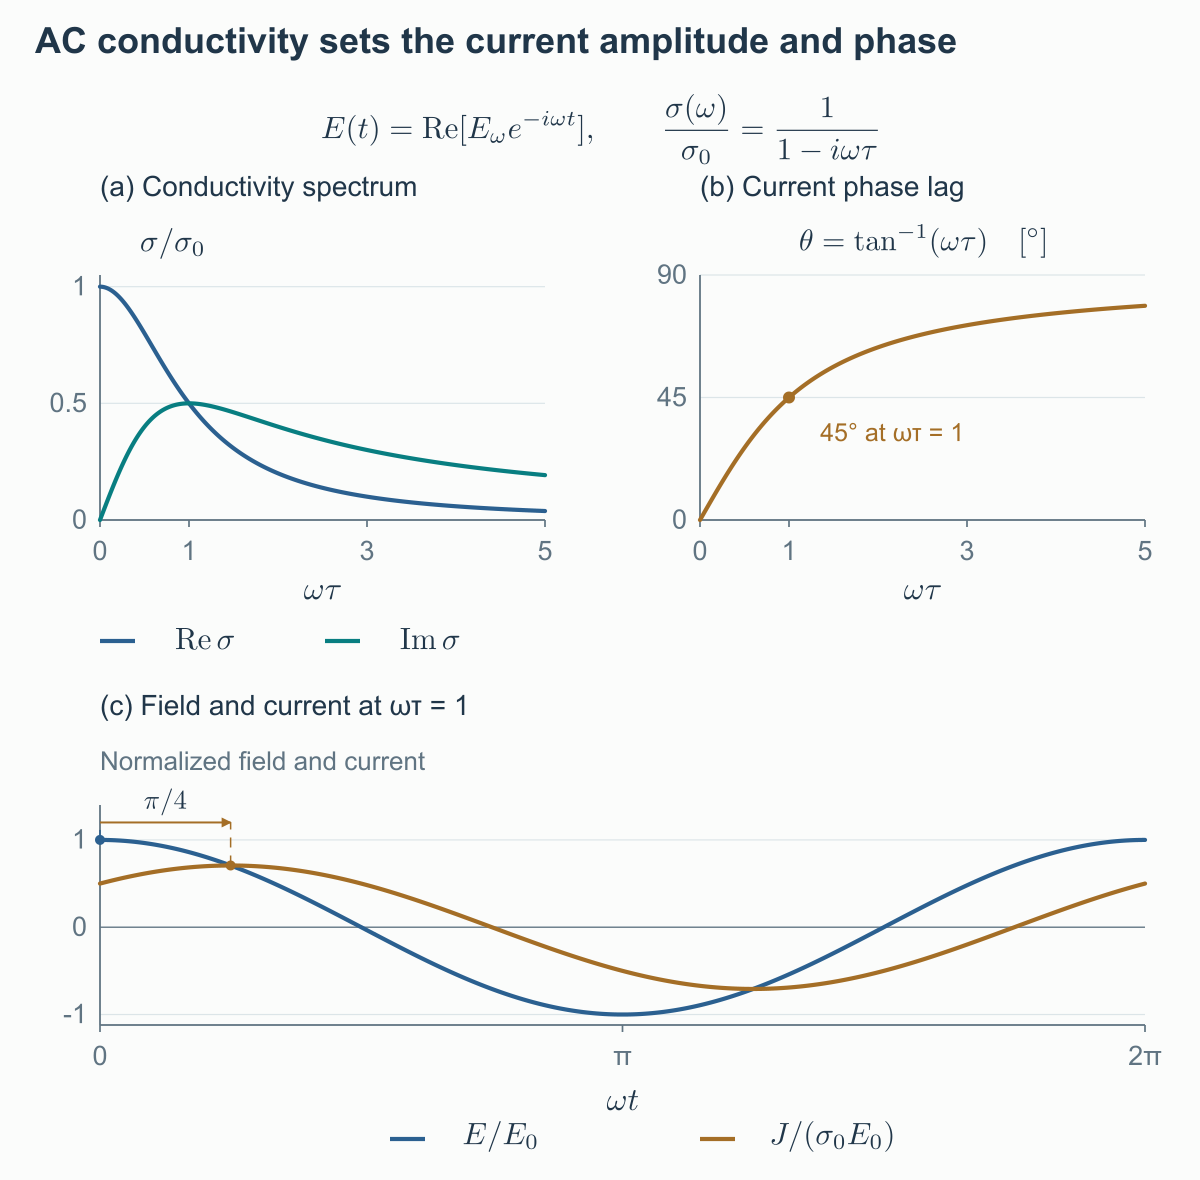

*그림 6. Conductivity의 실수부와 허수부는 $e^{-i\omega t}$ 규약을 따른다. $\omega\tau=1$에서 normalized current의 진폭은 $1/\sqrt2$이고, 전기장보다 위상이 $\pi/4$ 늦다. (c)의 가로 표시는 전기장이 최대가 되는 순간부터 전류가 최대가 되는 순간까지의 차이를 나타낸다. 이 conductivity는 같은 위치의 전기장과 conduction current를 연결한다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-ac)


이 예제의 물질값은 $\tau=100\,\mathrm{fs}$, $n=10^{23}\,\mathrm{m}^{-3}$, $m^{\ast}=0.2m_0$, $E_0=1000\,\mathrm{V/m}$로 고정했다. 주파수는 THz, 시간은 ps로 표시한다. 주파수를 높이면 같은 시간 구간에 더 많은 진동이 들어간다. 동시에 전류의 진폭은 줄고 phase lag는 1/4주기에 가까워진다. 관찰 시각을 바꾸면 파형 위의 선택점이 움직인다. 주파수가 0이면 전기장과 전류는 시간에 따라 변하지 않는다.



**AC steady state와 전기장을 켠 직후의 transient는 어떻게 다를까?**


식 (13)의 주기적인 해를 $J_{\rm ss}(t)$라 하자. 같은 정현파 전기장을 $t=0$부터 가하면 임의의 초기 전류에 대해

$$
J(t)=J_{\rm ss}(t)
+[J(0)-J_{\rm ss}(0)]e^{-t/\tau}.
$$

추가된 항은 외부 전기장 항을 0으로 둔 **homogeneous equation**의 해다. 이 항은 시간 척도 $\tau$로 사라진다. Cosine 전기장에서 초기조건을 $J(0)=0$으로 정하면, transient가 주기적인 해의 초기값을 정확히 상쇄한다. 주파수가 0인 극한에서는 $J_{\rm ss}=\sigma_0E_0$이므로 전체 식은 $\sigma_0E_0(1-e^{-t/\tau})$가 되어 식 (9)의 step response와 일치한다. Complex conductivity가 나타내는 것은 AC steady state이지, 전기장을 켠 순간부터의 전 과정이 아니다.





**Conduction current와 displacement current에서 dielectric function까지**


Conduction current density는 여전히 $\mathbf J=\sigma\mathbf E$다. Maxwell equation에는 배경의 **displacement current** $\varepsilon_0\varepsilon_b\partial_t\mathbf E$도 들어간다. 단자에서 측정하는 AC 전류에는 두 성분이 모두 기여할 수 있고, 소자의 모양과 크기도 영향을 준다.

주파수가 0이 아닐 때 conduction current와 배경의 displacement current를 합쳐 effective relative dielectric function을 정의하자.

$$
\begin{aligned}
&\mathbf J_{\mathrm{total},\omega}\\
&=[\sigma(\omega)-i\omega\varepsilon_0\varepsilon_b]\mathbf E_\omega\\
&=-i\omega\varepsilon_0\varepsilon_r(\omega)\mathbf E_\omega.
\end{aligned}
$$

이 등식을 $\varepsilon_r$에 대해 풀면

$$
\begin{aligned}
&\varepsilon_r(\omega)=\varepsilon_b+\frac{i\sigma(\omega)}{\varepsilon_0\omega}\\
&=\varepsilon_b-\frac{\omega_{p0}^2}{\omega(\omega+i/\tau)},\\
&\omega_{p0}^2=\frac{ne^2}{\varepsilon_0m^{\ast}}.
\end{aligned}
\tag{14}
$$

진공의 permittivity로 정의한 주파수가 $\omega_{p0}$이며, 배경 screening을 포함한 undamped **plasma frequency**는 $\omega_p=\omega_{p0}/\sqrt{\varepsilon_b}$다. 전자 밀도가 조금 달라졌을 때 그 전하가 만든 복원 전기장으로 밀도가 집단적으로 진동하는 angular frequency를 뜻하며, damping이 없는 경우의 값이다. 이 운동은 19절에서 유도한다. 분모와 부호는 식 (11)과 같은 시간 규약을 따른다. 이 Drude dielectric function은 같은 위치의 전기장과 전류를 연결하는 local model이다. Interband transition과 spatial dispersion은 생략했으므로, 결정의 optical spectrum 전체를 설명하지는 않는다.



## 7. 결정의 전자 상태와 energy band


Drude 식의 질량과 relaxation time은 어디서 정해질까? 자유전자라면 전자 자체의 질량인 bare mass를 쓰면 된다. 결정에서는 불순물이 없어도 주기적인 격자 potential 때문에 같은 힘에 대한 속도 변화가 자유전자와 다르다. 힘에 대한 반응을 나타내는 질량도, scattering으로 어떤 상태에 옮겨 갈 수 있는지도 결정 안의 전자 상태와 그 에너지에서 출발한다.

자유전자의 에너지는 $\hbar^2k^2/(2m_0)$다. 여기서 $\hbar=h/(2\pi)$는 reduced Planck constant다. 결정에서는 격자의 주기적인 potential이 전자의 **고유상태(eigenstate)**와 그 에너지를 바꾸므로, 이 포물선이 모든 wavevector에서 성립하지는 않는다. Wavevector를 바꾸며 에너지를 그리면 여러 곡선이나 곡면이 나온다. 각각을 **energy band** $\epsilon_b(\mathbf k)$라고 하며, 번호 $b$로 서로 다른 band를 구분한다.

**Wavevector**는 위치에 따라 위상이 어떻게 달라지는지 나타낸다. 1차원 평면파 $e^{ikx}$에서 $k$가 0이 아니면, 파장 $2\pi/\lvert k\rvert$만큼 떨어진 두 지점에서 위상이 같다. 따라서 wavevector의 단위는 길이의 역수다. 결정에서는 전자가 어디에 있는지가 아니라, 한 단위격자에서 다음 단위격자로 옮겨 보았을 때 파동함수의 위상이 어떻게 바뀌는지를 나타낸다. 주기적인 격자 자체는 전자가 가질 수 있는 band 상태를 정한다. 불순물이나 격자 결함처럼 그 주기성을 깨는 요소가 있으면 전자는 한 상태에서 다른 상태로 산란할 수 있다.

1차원에서는 격자 간격 $a$만큼 평행이동해도 Hamiltonian이 변하지 않는다. 따라서 Hamiltonian과 평행이동 연산자의 공통 고유상태를 고를 수 있다. 이 상태를 한 격자 간격만큼 옮기면 파동함수에는 위상 인자만 곱해진다.

$$
\begin{aligned}
&\psi_k(x+a)=e^{ika}\psi_k(x),\\
&\psi_k(x)=e^{ikx}u_k(x),\\
&u_k(x+a)=u_k(x).
\end{aligned}
\tag{15}
$$

이것이 **Bloch form**이다. 평면파 인자를 떼고 남은 $u_k$는 단위격자마다 같은 모양을 되풀이하는 주기함수다. 앞에서 쓴 평균 drift velocity $\mathbf u$와는 다른 기호다. Wavevector가 $2\pi/a$만큼 달라도 한 격자 간격을 옮겼을 때 곱해지는 위상 인자는 같다. 따라서 $k$는 $[-\pi/a,\pi/a)$처럼 폭이 한 주기인 범위에서만 고르면 된다. 이 범위를 **Brillouin zone**이라 한다. 위상 인자가 같아도 단위격자 안의 파동함수와 에너지는 다를 수 있다. 그런 상태는 서로 다른 band로 구분한다. [Tong, Band Structure](https://davidtong.org/pdfs/teaching/solid-state-physics/solidstate2.pdf)

격자마다 되풀이되는 모양에 phase factor를 곱해 보면 두 인자의 역할을 구별할 수 있다. 격자점 $x=ja$마다 peak가 있는 실수 주기함수를 하나 정하자.

$$
\begin{aligned}
&u_{\rm demo}(x)=0.25+0.75\cos^8(\pi x/a),\\
&\psi_k^{\rm demo}(x)=e^{ikx}u_{\rm demo}(x),\\
&\operatorname{Re}\psi_k^{\rm demo}=u_{\rm demo}(x)\cos(kx),\\
&\operatorname{Im}\psi_k^{\rm demo}=u_{\rm demo}(x)\sin(kx).
\end{aligned}
$$

$u_{\rm demo}$는 격자 간격 $a$마다 같은 모양을 되풀이하고, phase는 다음 격자점으로 갈 때마다 $ka$씩 달라진다. $ka=0$이면 전체 함수는 실수이며 격자마다 똑같이 반복된다. $ka=\pi/4$이면 실수부와 허수부가 여러 격자점에 걸쳐 서서히 달라지고, $ka=\pi$이면 이웃한 격자점에서 부호가 반대다. 실수부가 0인 곳에서도 허수부가 남아 있으면 전체 파동함수는 0이 아니다.

여기서는 phase를 곱하는 효과만 보기 위해 $u_{\rm demo}$를 직접 정하고 고정했다. 이 함수들은 Bloch translation 조건을 만족하지만, 특정 atomic potential의 eigenstate를 계산한 결과는 아니다. 실제 band의 $u_k$는 일반적으로 $k$에 따라 달라진다. 이 예제에서는 $\lvert e^{ikx}\rvert=1$이므로 상대적인 density는 $\lvert\psi_k^{\rm demo}\rvert^2=u_{\rm demo}^2$로 같다. Phase factor는 전자가 특정 위치에 모인 wave packet의 envelope와는 다르다.


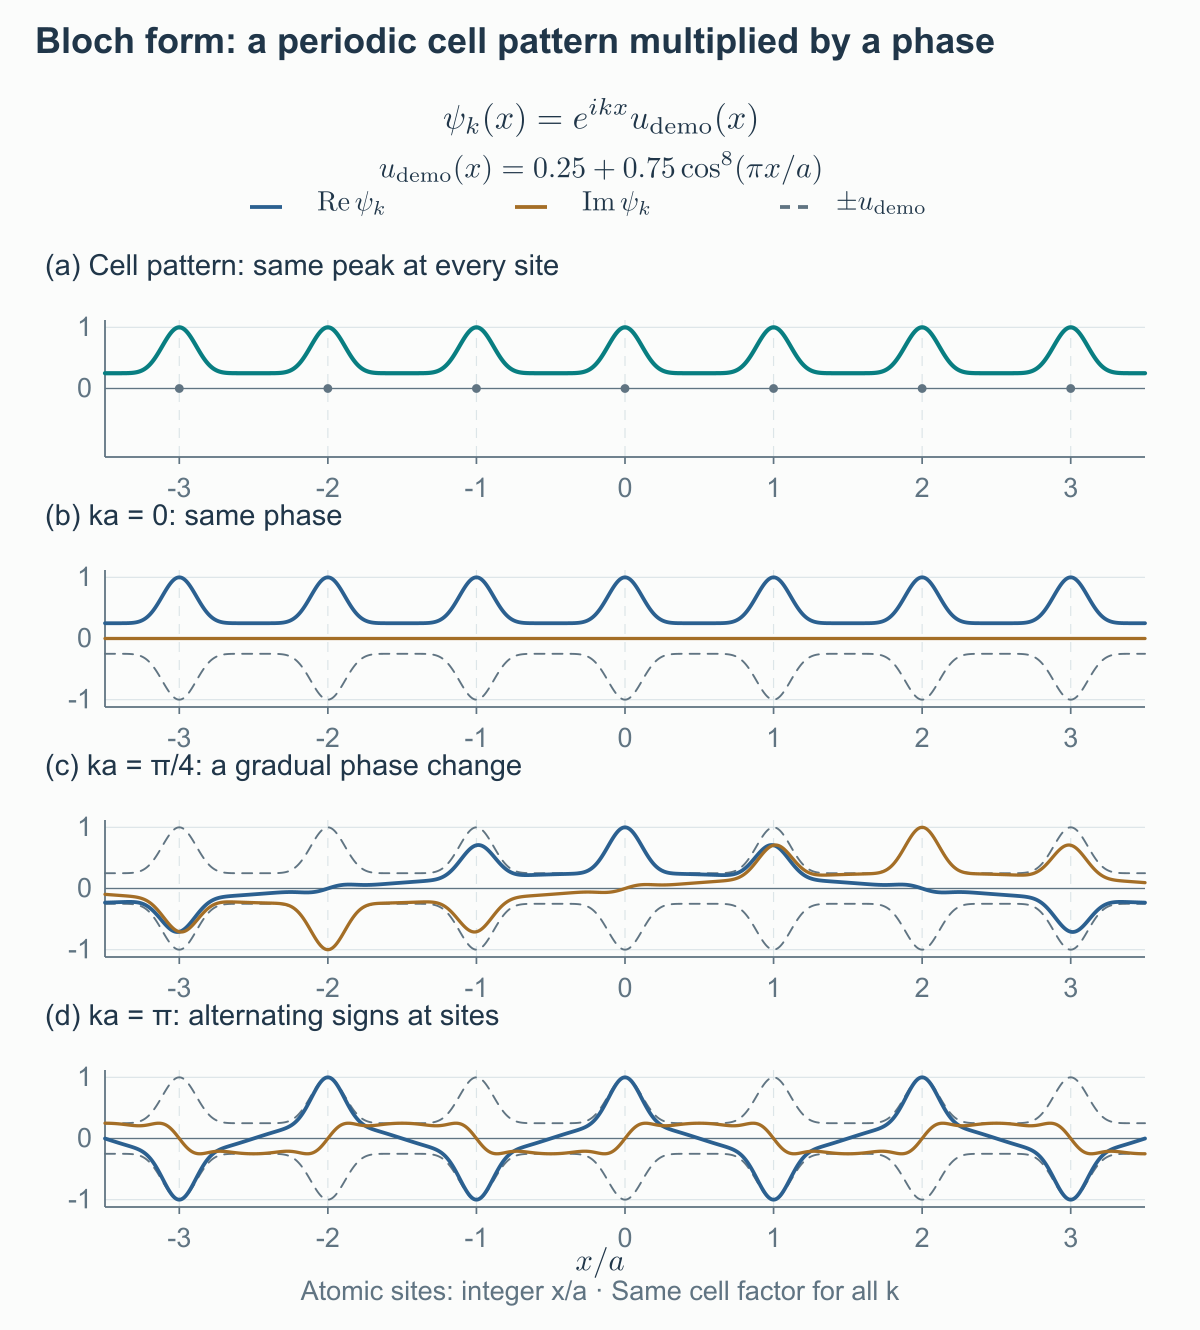

*그림 7. (a) 정수 격자점 $x/a=j$마다 같은 모양의 peak가 반복된다. (b–d)는 $ka=0,\pi/4,\pi$에서 전체 함수의 실수부와 허수부를 파란색과 금색으로 그린 것이다. 회색 점선은 $\pm u_{\rm demo}$이며 모든 행의 세로축은 같은 상대 진폭이다. 한 시각의 공간 분포를 그렸으며 전자가 움직인 경로는 아니다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-bloch)


Interactive 예제에서는 $a=0.5\,\mathrm{nm}$와 공간축을 고정했다. $k$를 바꾸면 축이 늘어나는 대신 phase와 전체 함수가 달라진다. 두 번째 조작 항목은 주기함수를 $u(x)=1-\eta+\eta\cos^8(\pi x/a)$로 바꾼다. $\eta=0$이면 평면파가 되고, $\eta=0.75$이면 그림 7의 모양이 된다. 아래 행렬 계산에서는 tight-binding Hamiltonian의 정확한 eigenstate와 에너지를 따로 확인할 수 있다.

**Tight-binding** 모델에서는 격자점마다 그 주변에 모여 있는 orbital $\lvert j\rangle$ 하나를 기저로 잡는다. 이 orbital들이 정규화되어 있고 서로 직교하면, 각 기저 계수의 절댓값을 제곱해 해당 orbital을 관측할 확률을 구할 수 있다. $j$는 격자점 번호이고, $\epsilon_0$는 격자점 하나에 할당한 orbital 에너지다. 1절의 진공 유전율과는 다른 기호다. 이웃한 orbital의 진폭을 이어 주는 결합의 크기는 에너지 단위의 **hopping parameter** $t_h>0$로 나타낸다. Hamiltonian의 대각항은 각 orbital의 에너지이고, 비대각항은 이웃한 orbital 사이의 결합이다.

$$
\begin{aligned}
&H=\epsilon_0\sum_j\lvert j\rangle\langle j\rvert\\
&\quad-t_h\sum_j\left(
\begin{aligned}[t]
&\lvert j+1\rangle\langle j\rvert\\
&+\lvert j\rangle\langle j+1\rvert
\end{aligned}
\right).
\end{aligned}
\tag{16}
$$

격자점 $N$개를 고리로 연결한 chain에서는 계수가 $c_j=e^{ikja}/\sqrt{N}$인 상태가 이 Hamiltonian의 고유상태다. 한 바퀴 돌아 처음 격자점에 오면 계수가 다시 같아야 하므로, 허용되는 wavevector는 정수 $l$에 대해 $k=2\pi l/(Na)$다. 오른쪽과 왼쪽 이웃의 계수를 현재 격자점의 계수로 나누면 각각 $e^{ika}$, $e^{-ika}$이고, 둘을 더하면 $2\cos ka$다. 따라서 에너지는

$$
\begin{aligned}
&\epsilon(k)=\epsilon_0-2t_h\cos ka.\\
&\text{With }\epsilon_0=2t_h:\\
&\epsilon(k)=2t_h(1-\cos ka).
\end{aligned}
\tag{17}
$$

이렇게 에너지 기준을 잡으면 band의 최솟값이 0이다. 에너지를 한꺼번에 같은 양만큼 옮겨도 힘이나 속도는 변하지 않는다. $ka=0$에서는 이웃한 계수의 위상이 같고 에너지는 0이다. $ka=\pi$에서는 이웃한 계수의 부호가 반대여서 에너지가 $4t_h$다. 이 차이는 두 상태에서 이웃 orbital의 진폭이 서로 다른 위상으로 결합하기 때문에 생긴다.

Hopping 항은 Schrödinger 방정식에서 orbital들의 진폭을 상대 위상까지 포함해 결합한다. Scattering rate처럼 일정 시간 동안 전자가 다른 상태로 옮겨 갈 확률을 주는 항이 아니다. $t_h$가 커지면 band의 폭은 넓어지지만, 그 사실만으로 relaxation time이 짧아진다고 할 수는 없다.



**네 site로 이루어진 ring의 Hamiltonian을 직접 풀어 보자**


격자점 네 개를 고리로 연결하자. $\epsilon_0=2t_h$로 놓고 기저를 $\lvert0\rangle,\lvert1\rangle,\lvert2\rangle,\lvert3\rangle$ 순서로 잡으면 Hamiltonian은 다음 행렬이 된다.

$$
H_4=t_h
\begin{pmatrix}
2&-1&0&-1\\
-1&2&-1&0\\
0&-1&2&-1\\
-1&0&-1&2
\end{pmatrix}.
$$

오른쪽 위와 왼쪽 아래의 비대각항은 마지막 격자점과 첫 격자점이 이웃이라는 뜻이다. 모든 성분이 같은 정규화 벡터 $(1,1,1,1)^T/2$에 이 행렬을 곱하면 각 행에서 $2t_h-t_h-t_h=0$으로 상쇄되므로 에너지는 0이다. 부호가 번갈아 나오는 벡터 $(1,-1,1,-1)^T/2$는 이웃 두 항이 오히려 같은 부호로 더해져 에너지가 $4t_h$다. 허용되는 $ka=-\pi,-\pi/2,0,\pi/2$를 식 (17)에 넣으면 $4t_h,2t_h,0,2t_h$를 얻는다. 이 값들은 행렬을 직접 대각화해 얻은 네 고유값과 일치한다.


In [4]:
ring_size, hopping_four_eV = 4, 1.0
H_four = 2 * hopping_four_eV * np.eye(ring_size)
for site in range(ring_size):
    neighbor = (site + 1) % ring_size
    H_four[site, neighbor] = -hopping_four_eV
    H_four[neighbor, site] = -hopping_four_eV

ring_ka = np.array([-np.pi, -np.pi / 2, 0.0, np.pi / 2])
band_four_eV = 2 * hopping_four_eV * (1 - np.cos(ring_ka))
matrix_four_eV = np.linalg.eigvalsh(H_four)
uniform_four = np.ones(ring_size) / np.sqrt(ring_size)
alternating_four = (-1.0)**np.arange(ring_size) / np.sqrt(ring_size)
assert np.allclose(matrix_four_eV, np.sort(band_four_eV))
assert np.allclose(H_four @ uniform_four, 0.0)
assert np.allclose(H_four @ alternating_four, 4 * hopping_four_eV * alternating_four)
print("Four-site energies (eV):", matrix_four_eV)


Four-site energies (eV): [-4.22320895e-16  2.00000000e+00  2.00000000e+00  4.00000000e+00]


이 행렬에서 구하는 것은 전자가 가질 수 있는 상태와 그 에너지다. 전기장을 끈 뒤 전류가 얼마나 빨리 줄어드는지 알려면, 그 상태 사이의 scattering rate가 별도로 필요하다.



Bloch 고유상태 하나는 결정 전체에 퍼져 있다. 특정 위치 주변에 전자가 모인 상태를 만들려면, 같은 band에서 서로 가까운 wavevector의 상태를 겹쳐야 한다. 원하는 위치 주변에서는 진폭이 보강되고 다른 곳에서는 대부분 상쇄되도록 겹치면, 그 주변에 모인 **wave packet**이 생긴다. 격자 간격 규모로 빠르게 진동하는 부분을 감싸는 느린 윤곽이 **envelope**다. Wavevector 분포가 좁은 packet의 중심은 band의 **group velocity**로 움직인다. Packet의 크기만큼 떨어진 지점들 사이에서 외부 potential이 크게 달라지지 않으면, 이 중심의 운동을 semiclassical 방정식으로 추적할 수 있다.



**공간에 퍼진 eigenstate로 움직이는 wave packet을 어떻게 만들까?**


서로 가까운 wavevector의 Bloch 상태를 겹치면, 시간에 따라 각 상태의 위상이 달라져 packet이 이동한다. 중심 $k_0$ 근처에서 에너지를 $\epsilon(k)\simeq\epsilon(k_0)+\epsilon^{\prime}(k_0)(k-k_0)$로 근사하자. 각 상태의 위상 $kx-\epsilon(k)t/\hbar$에 이 식을 넣으면 envelope는 $x-\epsilon^{\prime}(k_0)t/\hbar$의 함수가 된다. 이 조합을 일정하게 유지하며 움직이는 점의 속도가 식 (18)의 group velocity다.

에너지를 일차식으로 근사할 수 있을 만큼 packet의 $k$ 분포가 좁아야 한다. 외력이 있을 때는 packet 자체도 potential이 뚜렷하게 달라지는 거리보다 충분히 작아야 한다. 이 두 조건은 위치와 운동량에 대한 불확정성 관계가 허용하는 범위에서 함께 충족해야 한다.



## 8. Wave packet의 운동과 effective mass


### Wave packet 중심의 위치·속도·가속도

한곳에 모인 정규화된 전자 wave packet $\lvert\psi(t)\rangle$을 생각하자. 위치의 기댓값을 packet의 중심으로 잡으면, 이 중심을 시간에 따라 미분해 속도와 가속도를 정의할 수 있다.

$$
\begin{aligned}
&\mathbf r_c(t)=\langle\psi(t)\lvert\widehat{\mathbf r}\rvert\psi(t)\rangle,\\
&\mathbf v_c(t)=\frac{d\mathbf r_c}{dt},\\
&\mathbf a_c(t)=\frac{d\mathbf v_c}{dt}.
\end{aligned}
$$

식의 모자 표시는 위치 연산자를 뜻한다. 중심 위치는 이 packet의 확률분포에서 구한 평균이며, 전자 하나가 실제로 지나간 경로가 아니다. **가속도 역시 이 평균 위치가 움직이는 속도의 변화율**이다. 앞에서 쓴 drift velocity $\mathbf u$는 여러 전하 운반자의 속도를 평균한 값이다. 하나는 packet 하나의 위치 확률분포에 대한 평균이고, 다른 하나는 여러 전자의 속도에 대한 평균이다.

외력이 없는 결정에서 wavevector가 정해진 하나의 Bloch 고유상태는 확률밀도가 시간에 따라 변하지 않는다. 속도의 기댓값은 0이 아닐 수도 있지만, 상태가 결정 전체에 퍼져 있어 따라갈 만한 위치의 중심은 없다. 서로 가까운 Bloch 상태를 겹쳐 한곳에 모인 packet을 만들면, 외력이 그 packet의 중심 wavevector와 중심 속도를 어떻게 바꾸는지 따져 볼 수 있다.

### 하나의 band에서 wave packet의 운동을 근사하기

다른 band와 분리된 한 band 안에 wavevector 분포가 좁은 packet이 있다고 하자. 외부 potential은 packet 하나의 크기 안에서 크게 달라지지 않아야 한다. 또 외력은 다른 band로의 전이를 무시할 수 있을 만큼 약하고 천천히 변한다고 가정한다. Scattering과 scattering 사이의 운동을 구할 때, 아래 식의 $\mathbf r$과 $\mathbf k$는 각각 packet의 중심 위치와 중심 wavevector를 나타낸다. $\mathbf v$는 $\mathbf v_c$의 근삿값이다. 이 중심 운동에 쓰는 Hamiltonian은

$$
\begin{aligned}
&\mathcal H_{\rm packet}=\epsilon(\mathbf k)+U_{\rm ext}(\mathbf r),\\
&\mathbf p_{\rm crys}=\hbar\mathbf k.
\end{aligned}
$$

여기서 $U_{\rm ext}$는 외부 potential energy다. 격자의 주기성은 band 에너지 $\epsilon(\mathbf k)$를 구할 때 이미 반영했다. 이 Hamiltonian의 운동량 변수는 결정 운동량 $\mathbf p_{\rm crys}$다. Hamilton 방정식에서 에너지를 운동량으로 미분하면 속도가 나오고, 에너지의 위치 미분에 음의 부호를 붙이면 외력이 나온다. $\partial/\partial p_{\mathrm{crys},i}=(1/\hbar)\partial/\partial k_i$를 쓰면

$$
\begin{aligned}
&v_i(\mathbf k)=\frac{1}{\hbar}\frac{\partial\epsilon}{\partial k_i},\\
&\hbar\dot k_j=F_j.
\end{aligned}
\tag{18}
$$

아래첨자 $i,j$는 직교좌표의 성분을 구분한다. 첫째 식은 band의 기울기가 packet 중심의 group velocity를 정한다는 뜻이고, 둘째 식은 외력이 결정 운동량을 바꾸는 속도를 나타낸다. 이 근사는 wavevector 분포가 좁을 때 쓴다. 결정에서 $\hbar\mathbf k$는 격자 간격을 평행이동할 때의 위상으로 정해지며, 일반적으로 전자의 역학적 운동량과 다르다. 따라서 자유전자에서처럼 group velocity를 항상 $\hbar\mathbf k/m_0$로 구할 수는 없다. 전기장만 있으면 $U_{\rm ext}=-e\varphi$이고 $\mathbf F=-e\mathbf E$다. 여기서는 자기장과 Berry curvature에 따른 보정을 제외한다. [Tong, Secs. 3.2.1–3.2.3](https://davidtong.org/pdfs/teaching/solid-state-physics/solidstate3.pdf)

외력이 $\mathbf k(t)$를 바꾸면 packet은 band에서 기울기가 다른 곳으로 옮겨 갈 수 있다. 그에 따라 달라지는 group velocity를 시간에 대해 미분하면 packet 중심의 가속도가 나온다. 연쇄 법칙을 쓰면

$$
\begin{aligned}
&\dot v_i=\sum_j\frac{\partial v_i}{\partial k_j}\dot k_j\\
&=\sum_j\frac{1}{\hbar^2}\frac{\partial^2\epsilon}{\partial k_i\partial k_j}F_j.
\end{aligned}
\tag{19}
$$

식 (19)는 외력의 각 성분이 packet 중심의 가속도에 얼마나 기여하는지 보여 준다. 자유입자의 질량 역수에 해당하는 이 계수들을 모아 **band inverse-effective-mass tensor**로 정의한다.

$$
\begin{aligned}
&\left(m_{\rm curv}^{-1}\right)_{ij}=\frac{1}{\hbar^2}\frac{\partial^2\epsilon}{\partial k_i\partial k_j}.\\
&\text{In 1D:}\\
&\frac{1}{m_{\rm curv}(k)}=\frac{\epsilon''(k)}{\hbar^2}.
\end{aligned}
\tag{20}
$$

이 행렬에 외력 벡터를 곱하면 packet 중심의 가속도가 나온다. 1차원에서는 계수가 하나뿐이다. Band의 곡률(curvature)이 직접 정하는 것은 **단위 외력에 대한 가속도**, 즉 질량의 역수이지 질량 자체가 아니다.

Band에서 기울기가 가파른 지점일수록 packet의 group velocity가 크다. 양의 curvature가 큰 지점에서는 외력이 $k$를 조금 바꿔도 그 기울기가 크게 달라진다. 같은 힘으로 더 크게 가속하므로 양의 effective mass는 더 작다. 지금 얼마나 빠르게 움직이는지와 같은 힘을 받았을 때 속도가 얼마나 빨리 변하는지는 서로 다른 문제다.

Band가 최솟값을 갖는 매끄러운 지점 $k_0$에서는 Taylor 전개의 1차 항이 0이다. 곡률이 양수라면 2차 항까지 남겨

$$
\begin{aligned}
&\epsilon(k)\simeq E_c+\frac{\hbar^2(k-k_0)^2}{2m^{\ast}},\\
&v=\frac{\hbar(k-k_0)}{m^{\ast}},\\
&\dot v=\frac{F}{m^{\ast}}.
\end{aligned}
\tag{21}
$$

여기서 $E_c$는 band의 최솟값이다. Scattering 사이의 packet 중심 가속도는 마지막 줄과 같다. 이 포물선 근사가 유효하고 곡률이 방향에 따라 같으면, wavevector가 다른 packet에도 같은 양의 질량을 쓸 수 있다. 여러 전자의 가속도를 평균해도 Drude 식의 전기력 항이 같은 형태로 남는 이유다. Scattering으로 평균 속도가 줄어드는 효과는 별도 항으로 들어간다.


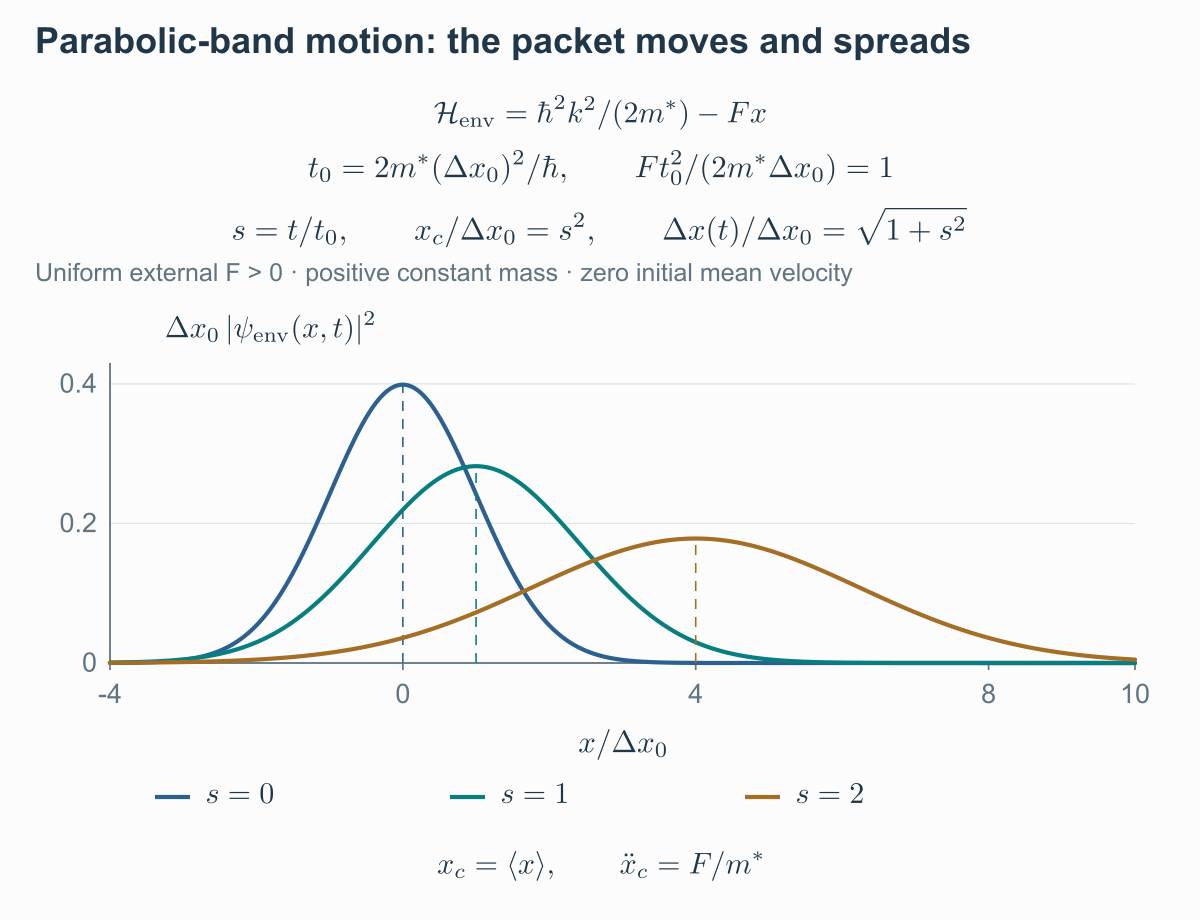

*그림 8. 포물선 band에서 초기 envelope를 실수 Gaussian $\psi_{\rm env}(x,0)\propto\exp[-x^2/(4(\Delta x_0)^2)]$으로 놓는다. $\Delta x_0$는 초기 위치 분포의 표준편차다. 시간 척도는 $t_0=2m^{\ast}(\Delta x_0)^2/\hbar$이며, $Ft_0^2/(2m^{\ast}\Delta x_0)=1$이 되는 일정한 외력 $F>0$을 가한다. 세 곡선은 $t/t_0=0,1,2$에서의 위치 확률밀도다. 시간이 지나면 중심이 오른쪽으로 이동하고 분포도 넓어진다. 곡선마다 전체 면적은 1이다. 점선은 각 시각의 평균 위치를 가리킨다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-packet)


이 예제에서는 초기 폭 $\Delta x_0=10\,\mathrm{nm}$와 질량 $m^{\ast}=m_0$를 고정했다. 위치와 폭은 nm, 시간은 ps, 확률밀도는 nm의 역수로 표시한다. 외력이나 시간을 바꿔도 축 범위는 그대로이며, 초기 확률밀도는 점선으로 함께 표시한다.

전자의 bare mass 자체가 바뀌는 것은 아니다. 원자 수준의 scalar potential로 계산하면, Ehrenfest 정리에 따라 **격자가 주는 힘과 외력을 합한 뒤 그 기댓값**을 bare mass로 나누어 packet 중심의 가속도를 구한다. 반면 band 계산에서는 격자의 효과가 고유상태와 에너지 곡선에 이미 들어 있다. 그러므로 single-band 근사에서 effective mass를 쓰면, 격자의 힘을 따로 계산하지 않고도 **외력**이 packet 중심의 속도를 얼마나 바꾸는지 구할 수 있다. [Fitzpatrick, Ehrenfest theorem](https://farside.ph.utexas.edu/teaching/qmech/lectures/node36.html)

## 9. Nonparabolic band와 anisotropic effective mass


어디서나 같은 숫자 하나로 유효 질량을 나타내려면, 전자가 차지하는 band 영역에서 곡률이 거의 일정하고 방향에 따라서도 달라지지 않아야 한다. **Nonparabolic** band에서는 wavevector가 바뀌면 곡률도 달라져, 지점마다 유효 질량이 달라질 수 있다. **Anisotropic** band에서는 같은 지점에서도 방향마다 곡률이 다르므로, 외력을 어느 방향으로 가하는지가 중요하다.

### Cosine band의 group velocity와 curvature

Scattering 사이에 packet이 한 band 안에서 움직인다고 하자. 식 (17)의 cosine band를 포물선으로 바꾸지 않고 그대로 미분하면

$$
\begin{aligned}
&v(k)=\frac{2t_ha}{\hbar}\sin ka,\\
&\frac{1}{m_{\rm curv}(k)}=\frac{2t_ha^2}{\hbar^2}\cos ka,\\
&m_{\rm edge}=\frac{\hbar^2}{2t_ha^2}.
\end{aligned}
\tag{22}
$$

$ka=0$ 근처에서는 band를 양의 유효 질량 $m_{\rm edge}$를 갖는 포물선으로 근사할 수 있다. $ka=\pi/3$에서는 곡률이 절반이어서 그 지점의 유효 질량은 두 배다. $ka=\pi/2$에서는 group velocity가 최대다. 그런데 속도가 최대인 바로 그 지점에서는 속도를 wavevector로 미분한 값이 0이므로 유효 질량의 역수도 0이다. 이는 그 순간 힘을 가해도 가속도가 0이라는 뜻이지, 속도 자체가 0이라는 뜻이 아니다. 이 **변곡점(inflection point)**을 지나면 곡률이 음수가 되어, packet 중심이 외력과 반대 방향으로 가속할 수 있다.

지금 구한 가속도는 특정 wavevector를 중심으로 한 packet 하나의 값이다. 도선 전체의 전류를 알려면 전자가 실제로 차지한 상태를 모두 더해야 한다. Band의 한 지점에서 곡률이 음수라는 사실만으로 conductivity의 부호를 정할 수는 없다.

$t_h=1\,\mathrm{eV}$, $a=0.5\,\mathrm{nm}$을 넣으면 $m_{\rm edge}\simeq0.1524m_0$이고 최대 속도는 약 $1.5193\times10^6\,\mathrm{m/s}$다. 코드에서는 SI 단위의 $\hbar$와 맞추기 위해 hopping 에너지를 joule로 바꾼다.


In [5]:
def cosine_band(ka, hopping_eV=1.0, lattice_nm=0.5):
    # ka is dimensionless. Convert the Hamiltonian energy and lattice spacing to SI.
    z = np.asarray(ka)
    th, a = hopping_eV * E_CHARGE, lattice_nm * 1e-9
    energy_J = 4 * th * np.sin(z / 2)**2  # Same band; avoids cancellation near ka=0.
    velocity = 2 * th * a / HBAR * np.sin(z)
    inverse_mass = 2 * th * a**2 / HBAR**2 * np.cos(z)
    return energy_J / E_CHARGE, velocity, inverse_mass

probe = np.array([0, np.pi / 3, np.pi / 2, np.pi])
energies, velocities, inv_mass = cosine_band(probe)
print("energy (eV):", energies)
print("m0/m_curv:", M0 * inv_mass)
assert np.isclose(inv_mass[1], inv_mass[0] / 2)
assert abs(inv_mass[2] / inv_mass[0]) < 1e-14
assert inv_mass[-1] < 0


energy (eV): [0. 1. 2. 4.]
m0/m_curv: [ 6.56171060e+00  3.28085530e+00  4.01788894e-16 -6.56171060e+00]


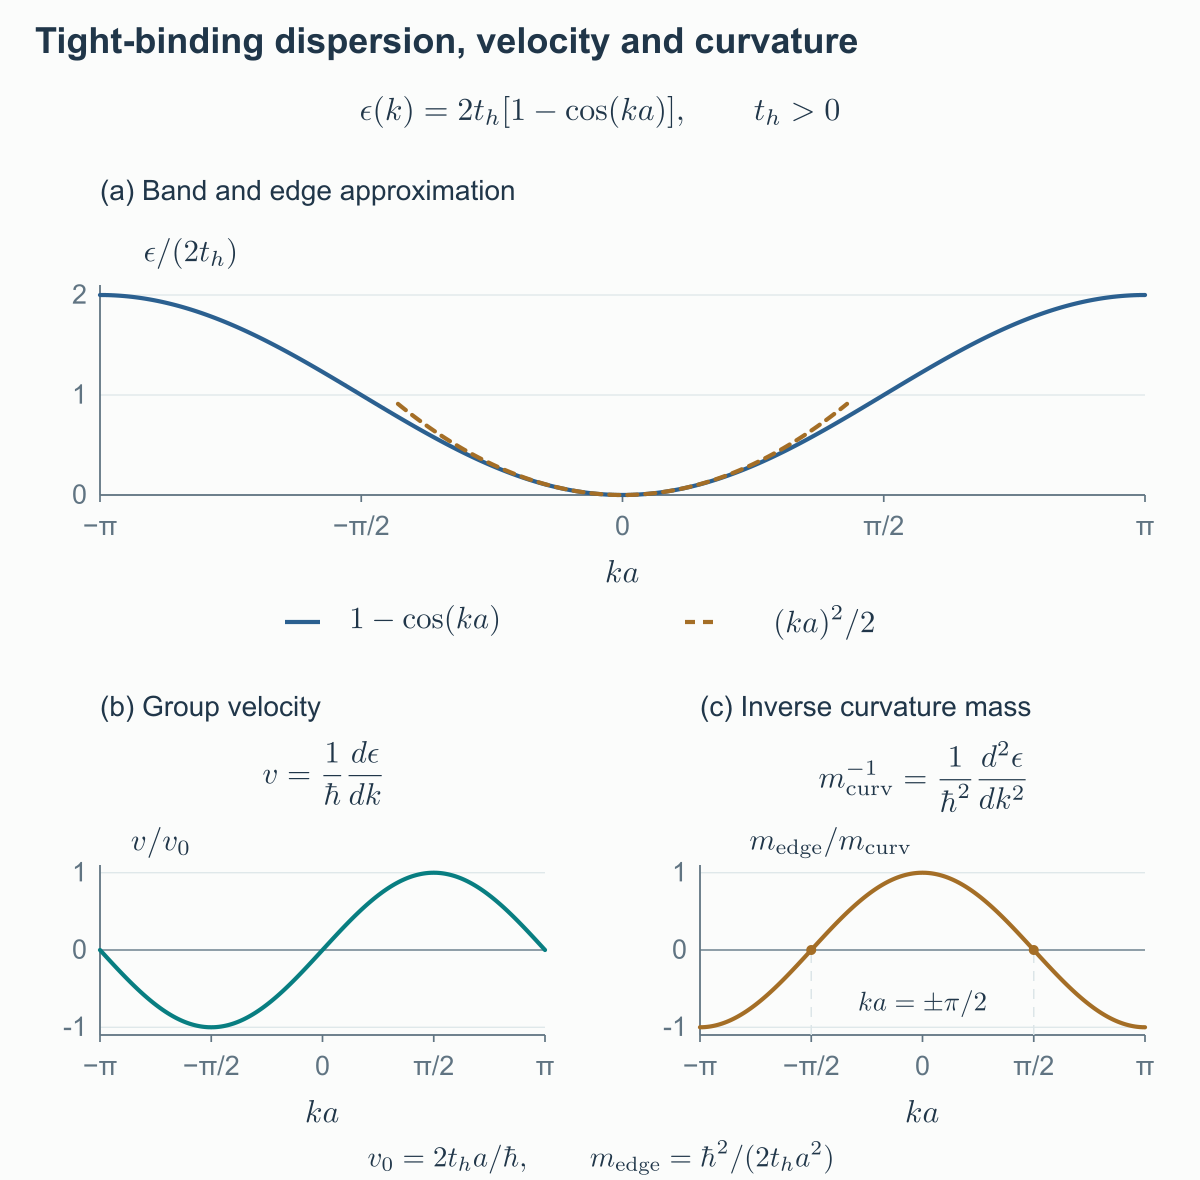

*그림 9. 같은 tight-binding band의 기울기와 곡률로, wavevector 분포가 좁은 packet의 group velocity와 질량의 역수를 각각 구한다. 점으로 표시한 두 변곡점에서 속력은 최대지만 질량의 역수는 0을 지난다. Band-edge mass를 상수로 쓸 수 있는 범위는 band 바닥 근처다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-band)


세 그래프 모두 같은 물리적 $k$ 축을 쓰며 단위는 nm의 역수다. 세로축은 각각 energy, velocity, inverse curvature mass로 나누고 범위를 고정했다. $t_h$를 키우면 energy와 velocity, curvature의 변화 폭이 위아래로 커진다. $a$를 키우면 가로 주기 $2\pi/a$가 짧아져 곡선이 옆으로 압축되고, first-zone 경계 $\pm\pi/a$도 안쪽으로 이동한다. 반복되는 곡선은 같은 tight-binding band를 extended zone으로 그린 것이지, 서로 다른 band가 아니다. 속도가 0인 지점과 곡률이 0인 지점을 찾아보자. 두 지점이 반드시 같지는 않다.



**Curvature가 음수면 conductivity도 음수일까?**


아니다. 개별 packet의 가속도와 전자가 함께 만드는 전류는 다르게 계산한다. 거의 다 찬 band에서는 꼭대기 근처의 빈 전자 상태를 양전하를 띠는 **hole**로 다룰 수 있다. 꼭대기를 아래로 굽은 포물선으로 근사할 수 있는 범위에서는 hole의 유효 질량이 양수다. 완전히 찬 band에는 일반적인 intraband DC 전류가 흐르지 않는다. Brillouin zone 전체의 속도 기여를 더하면 상쇄되고, 온도가 0이면 같은 band 안에 occupation을 바꿀 가까운 빈 상태도 없기 때문이다.

Conductivity는 10절처럼 occupation 전체를 놓고 계산해야 한다. 거기서 쓰는 relaxation 근사에서는 band 일부가 아래로 굽어도, 전기장과 같은 방향으로 잰 conductivity는 음수가 되지 않는다. 거의 다 찬 band의 전자 밀도와 꼭대기에서 구한 음의 유효 질량 하나를 $ne^2\tau/m$에 넣으면, 이런 상태별 차이를 놓친다.





**하나의 cosine band에서 나타나는 Bloch oscillation**


일정한 전기장 아래에서 packet이 하나의 cosine band에 머물면, wavevector와 속도는 다음과 같이 변한다.

$$
\begin{aligned}
&k(t)=k(0)-\frac{eE}{\hbar}t,\\
&v(t)=\frac{2t_ha}{\hbar}\sin[k(t)a],\\
&\omega_B=\frac{e\lvert E\rvert a}{\hbar}.
\end{aligned}
\tag{23}
$$

전기장은 wavevector를 한쪽으로 계속 밀지만, 속도는 $k$에 대해 주기적이어서 일정한 주기로 방향을 바꾼다. 이것이 **Bloch oscillation**이다. Band 바닥 근처의 포물선으로 Brillouin zone 전체를 대신하면 이 진동이 나오지 않는다. 실제 시료에서 진동을 보려면 전기장이 정하는 한 주기 동안 scattering과 다른 band로의 전이를 무시할 수 있어야 한다.



### Anisotropic quadratic band의 mass tensor와 좌표축 회전

질량 행렬이 대각행렬이 되는 두 **주축(principal axis)**을 잡자. 이 2차원 포물선 band에서는 두 축의 질량 $m_1,m_2$가 모두 양수다. 같은 크기의 힘을 각 축 방향으로 가하면 질량이 작은 쪽에서 packet 중심이 더 크게 가속한다. 질량 행렬과 그 역행렬은 고유값이 모두 양수인 **positive-definite** 행렬이다. 주축과 실험실 좌표축이 어긋나 있어도 고유값은 그대로지만, 한 좌표축 방향의 힘이 여러 가속도 성분에 기여할 수 있다. 길이를 보존하는 직교행렬 $R$로 축을 회전시키면, 실험실 좌표에서

$$
\begin{aligned}
&\epsilon(\mathbf k)=E_c+\frac{\hbar^2}{2}\mathbf k^{T}M^{-1}\mathbf k,\\
&M^{-1}=R\begin{pmatrix}1/m_1&0\\0&1/m_2\end{pmatrix}R^{T},\\
&\dot{\mathbf v}=M^{-1}\mathbf F.
\end{aligned}
\tag{24}
$$

$m_1=0.2m_0$, $m_2=m_0$인 주축을 $30^\circ$ 회전시키면

$$
m_0M^{-1}=\begin{pmatrix}4&\sqrt3\\\sqrt3&2\end{pmatrix}.
$$

실험실 $x$ 방향으로만 힘을 가해도 packet 중심은 *x*, *y* 방향으로 모두 가속한다. 행렬의 첫 번째 열을 보면 두 가속도 성분의 비가 $a_y/a_x=\sqrt3/4\simeq0.433$임을 알 수 있다. 즉 가속도가 힘과 나란하지 않다.


In [6]:
angle = np.pi / 6
Raxes = np.array([[np.cos(angle), -np.sin(angle)],
                  [np.sin(angle),  np.cos(angle)]])
inverse_M = Raxes @ np.diag([1 / (0.2 * M0), 1 / M0]) @ Raxes.T
force = np.array([1e-18, 0.0])  # N; this example specifies a force, not an E field.
acceleration = inverse_M @ force
assert np.allclose(M0 * inverse_M, [[4, np.sqrt(3)], [np.sqrt(3), 2]])
print("acceleration direction ay/ax:", acceleration[1] / acceleration[0])


acceleration direction ay/ax: 0.4330127018922192


이 포물선 band에서 relaxation time을 일정한 수 하나로 놓으면 mobility tensor는 $e\tau M^{-1}$이다. 전자의 drift velocity를 구할 때는 4절과 마찬가지로 전자의 음전하에 따른 부호를 붙인다. 좌표축을 돌려서 생긴 비대각 성분은 서로 같으므로, 자기장이 만들어 내는 반대칭 Hall 응답과는 다르다. 시료의 *y* 방향이 개방되어 그쪽으로 전류가 흐를 수 없다면, *y* 방향 전류를 상쇄할 전기장이 추가로 생긴다. 위 tensor는 그런 시료 경계 조건과 별개로, 물질 안에서 전기장과 전류를 연결한다.

## 10. Occupation과 Boltzmann equation으로 conductivity 계산하기


앞에서 구한 속도는 packet 하나의 속도다. 반면 drift velocity $\mathbf u$는 작은 영역 안에 있는 전자들의 평균 속도다. 같은 수의 전자가 같은 속력으로 서로 반대 방향으로 움직이면 두 전류는 상쇄된다. 전류를 구할 때는 각 상태의 속도에 그 상태를 차지한 전자의 수를 곱해 더한 뒤, 전자 한 개의 전하를 곱한다.

자기장이 없고 두 spin의 전자가 같은 분포를 따르는 한 band를 생각하자. Wavevector의 방향을 뒤집어도 에너지가 같다고, 즉 $\epsilon(-\mathbf k)=\epsilon(\mathbf k)$라고 가정한다. 에너지가 같아도 기울기는 반대이므로 group velocity는 $\mathbf v(-\mathbf k)=-\mathbf v(\mathbf k)$다. 열평형에서는 에너지가 같은 이 두 상태에 전자가 있을 확률도 같아서 전류가 상쇄된다.

Spin을 하나 지정했을 때, 해당 상태가 전자로 차 있을 확률을 **occupation** $f(\mathbf k)$로 나타낸다. 각 값은 0과 1 사이지만, 여러 상태가 동시에 차 있을 수 있으므로 합이 1일 필요는 없다. $f=1/2$라면 같은 조건의 시료를 여러 번 준비했을 때 평균적으로 절반에서 그 상태에 전자가 있다는 뜻이다. 두 spin 상태를 모두 세므로 계수는 $g_s=2$다.

7절의 고리처럼 양쪽 끝을 이어 붙이는 주기적 경계 조건으로 상태 수를 셀 수 있다. 길이 $L_{\rm box}$인 1차원 상자에서는 한 바퀴 뒤의 파동함수가 같아야 한다. 즉 $e^{ikL_{\rm box}}=1$이고, 허용되는 wavevector 사이의 간격은 $2\pi/L_{\rm box}$다. 정육면체 상자에서는 spin 하나의 허용 상태마다 wavevector 공간에서 $(2\pi/L_{\rm box})^3$만큼의 부피가 배정된다. Wavevector 공간의 작은 부피 $d^3k$에 들어 있는 상태를 세고, 그 수를 실제 상자의 부피로 나누면

$$
\frac{d^3k}{(2\pi/L_{\rm box})^3}
\frac{1}{L_{\rm box}^3}
=\frac{d^3k}{(2\pi)^3}.
$$

상자가 충분히 크면 허용 상태 사이의 간격이 촘촘해져 합을 적분으로 바꿀 수 있다. 두 spin을 포함하면 실제 공간의 단위 부피당 상태 수는 $g_s\,d^3k/(2\pi)^3$이다. 여기에 occupation을 곱해 적분한 전자 밀도는 $n=g_s\int f\,d^3k/(2\pi)^3$다. 실제 결정의 한 band는 Brillouin zone 하나에서 적분한다. Band를 포물선으로 근사할 때는 모든 wavevector까지 적분 범위를 넓힐 수 있다. 전자가 주로 포물선 근사가 잘 맞는 에너지 범위에 있을 때 쓰는 방법이다.

$T$는 kelvin으로 나타낸 양의 절대온도다. Boltzmann 상수 $k_B$를 곱한 $k_BT$는 온도에 해당하는 에너지 척도다. 열평형에서 occupation은 $f_0(\epsilon)=1/[1+\exp((\epsilon-\mu_F)/(k_BT))]$다. **화학 퍼텐셜(chemical potential)** $\mu_F$의 단위는 에너지다. 아래첨자로 mobility $\mu$와 구분한다. 온도와 전자 밀도를 알고 있다면, occupation을 모두 합했을 때 그 밀도가 나오도록 화학 퍼텐셜을 정한다.

이 **Fermi–Dirac 분포**에는 spin까지 같은 한 상태에 전자가 둘 이상 들어갈 수 없다는 조건이 반영되어 있다. $\epsilon=\mu_F$에서 occupation은 $1/2$다. 이보다 에너지가 충분히 낮으면 상태가 대부분 차 있고, 충분히 높으면 대부분 비어 있다. 저온의 **degenerate** 전자 기체에서 두 경우를 잇는 구간은 $\mu_F$ 근처에 좁게 모여 있다. 약한 전기장에 따라 occupation이 바뀌는 곳도 주로 이 구간이다. 온도가 오르면 이 구간이 넓어진다. 반면 nondegenerate 전자 기체에서는 occupation이 전반적으로 낮고, 전자들이 열에너지 규모의 범위에 걸쳐 퍼져 있다. 열평형에서는 반대 방향의 전류가 상쇄되지만, 분포에 작은 변화 $\delta f=f-f_0$가 생기면 전류가 흐를 수 있다.

에너지가 같고 속도는 각각 $+v$와 $-v$인 두 상태를 같은 비중으로 세어 보자. 처음에 $f_+=f_-=0.500$이면 occupation의 합은 $1.000$이고, 속도를 곱해 더한 값은 0이다. 그런데 $f_+=0.499$, $f_-=0.501$로 바꾸면 occupation의 합은 여전히 $1.000$이지만, 속도를 곱한 합은

$$
vf_+-vf_-=v(0.499-0.501)=-0.002v.
$$

왼쪽으로 움직이는 상태에 전자가 조금 더 많아진 셈이다. 이 값에 두 상태를 세는 공통 가중치와 전자의 음전하를 곱하면 전류는 양수가 된다. 전자 밀도는 그대로여도 방향별로 전자가 얼마나 분포하는지에 따라 전류가 달라진다.


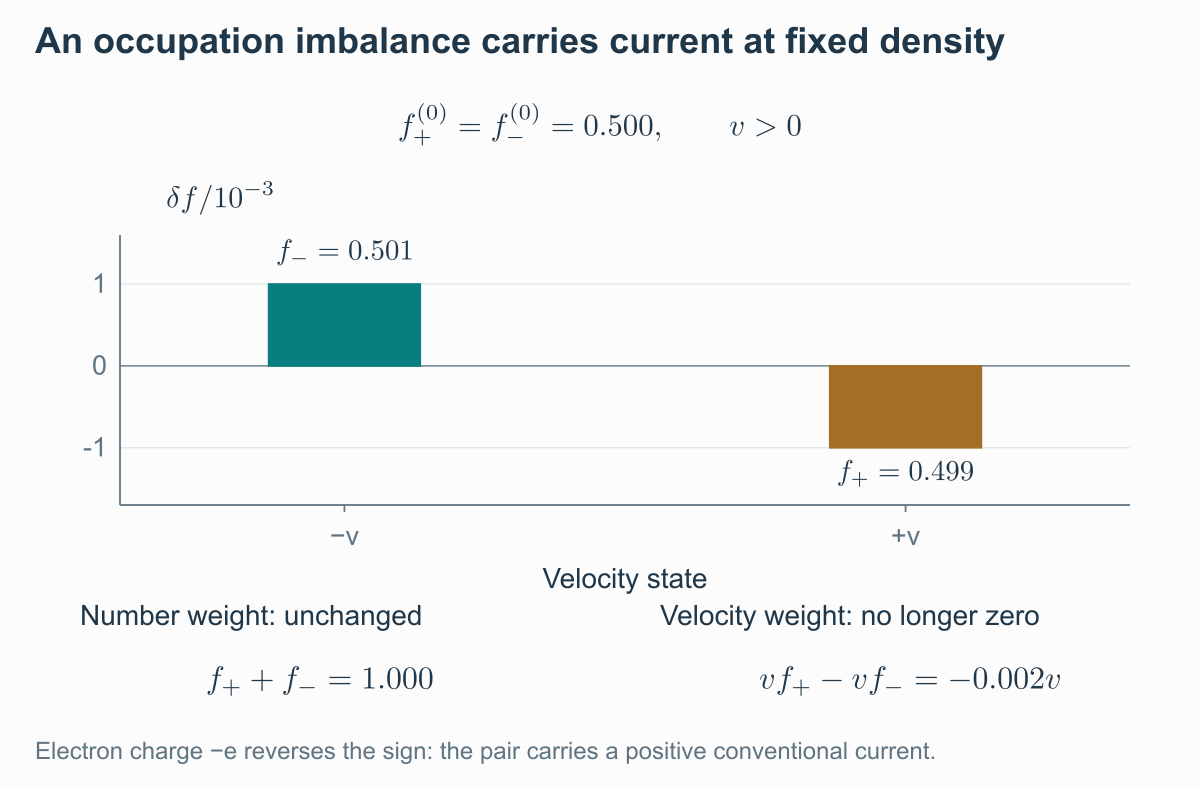

*그림 10. 막대가 보여 주는 값은 occupation의 변화량 $\delta f$다. 아래로 향한 막대는 확률이 음수라는 뜻이 아니라, 평형값 $0.500$보다 occupation이 줄었다는 뜻이다. 같은 비중으로 세는 두 상태의 occupation이 각각 $f_+=0.499$, $f_-=0.501$로 바뀌었다. 전자 수는 그대로지만 왼쪽으로 움직이는 전자가 더 많아져, 전류는 오른쪽으로 흐른다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-occupation)


상태별 속도를 알면, 전류를 구하는 데 남은 것은 전자들이 각 상태를 얼마나 채우는지다. **Kinetic model**에서는 파동함수의 상대 위상을 따라가는 대신 occupation의 변화만 계산한다. 상태 사이의 위상 관계가 오래 유지되어 수송에 영향을 준다면, occupation만으로는 그 효과를 설명할 수 없다.

공간적으로 균일한 계에서 **Boltzmann transport equation**은 두 가지 변화를 함께 계산한다. 전기장이 전자의 wavevector를 바꾸어 분포를 $\mathbf k$ 공간에서 옮기고, scattering은 상태 사이에 전자를 재분배한다. Scattering이 없다면 전자의 wavevector를 따라가면서 본 occupation은 그대로다. 짧은 시간에 $f(\mathbf k+\dot{\mathbf k}\,dt,t+dt)=f(\mathbf k,t)$가 성립한다. 이 관계를 Taylor 전개해 분포가 옮겨 가는 **advection** 항을 얻고, scattering으로 인한 단위 시간당 변화 $C[f]$를 더하면

$$
\partial_t f+\dot{\mathbf k}\cdot\nabla_{\mathbf k}f=C[f].
$$

분포가 위치에 따라 달라지지 않는 정상상태에서는 $\partial_t f=0$이고, 전기장에 의해 $\dot{\mathbf k}=-e\mathbf E/\hbar$가 된다. $f=f_0+\delta f$로 나누어 $\delta f$를 전기장의 1차까지만 구하자. 그러면 $\mathbf E\cdot\nabla_{\mathbf k}\delta f$는 전기장의 2차 항이라 생략한다. 평형 분포 자체에는 $C[f_0]=0$이므로, 남은 1차 collision 항을 $C[\delta f]$라 쓴다.

전류를 만드는 분포의 변화가 얼마나 빨리 줄어드는지, 에너지에만 의존하는 양의 transport time 하나로 나타내자. 등방적인 band에서는 에너지가 같은 상태들의 속력이 같다. 이 상태들 사이의 elastic scattering이 입사 방향과 산란 뒤 방향 사이의 각도에만 의존하면, 아래와 같은 collision 항을 유도할 수 있다. Band나 scattering이 더 일반적이라면, 이는 앞의 Taylor 전개에서 나오는 결과가 아니라 따로 도입한 근사다. 정상상태의 1차 방정식에 이 항을 넣으면

$$
\begin{aligned}
&-\frac{e\mathbf E}{\hbar}\cdot\nabla_{\mathbf k}f_0
=C[\delta f],\\
&C[\delta f]=-\frac{\delta f}{\tau_{\rm tr}(\epsilon)}.
\end{aligned}
\tag{25}
$$

둘째 식에서 줄어드는 것은 전류를 만드는 방향별 치우침, 즉 **angular mode**다. 앞의 두 상태 예처럼 같은 에너지에서도 움직이는 방향에 따라 occupation이 다른 성분을 말한다. 이 식을 밀도 변화까지 포함한 모든 분포에 적용할 수는 없다. 등방적인 elastic scattering에서 전류 성분이 이 식을 따르는 이유는 14절에서 유도한다.

정상상태에서도 전자는 움직이고 scattering은 계속 일어난다. Wavevector 하나를 고정해서 보면 전기장은 전자들을 그 상태로 보내거나 거기서 밀어 내고, scattering도 상태 사이에 전자를 재분배한다. 식 (25)는 두 효과가 상쇄되어 occupation이 일정하다는 뜻이다. 방향별 치우침이 그대로이므로 전류도 일정하다. 전기장을 끄면 그 치우침을 만들어 내는 쪽이 사라져 scattering에 의해 전류가 줄어든다.

$\nabla_{\mathbf k}f_0=\hbar\mathbf v\,\partial_\epsilon f_0$를 쓰면 식 (25)에서

$$
\delta f=-e\tau_{\rm tr}(\epsilon)(\mathbf E\cdot\mathbf v)
\left(-\frac{\partial f_0}{\partial\epsilon}\right).
\tag{26}
$$

Wavevector를 뒤집어도 에너지와 transport time은 그대로이고, 속도만 부호가 바뀐다. 따라서 식 (26)의 occupation 변화도 부호가 바뀌는 **홀수(odd) 성분**이다. 반대 wavevector의 상태를 짝지어 보면, occupation 변화는 서로 상쇄되어 밀도를 바꾸지 않는다. 그러나 각 변화에 속도를 곱하면 두 부호가 함께 뒤집혀 전류에는 같은 방향으로 더해진다. 전기장의 1차 응답에서는 밀도가 그대로여도 전류가 흐를 수 있다.

예를 들어 전기장이 오른쪽을 향하면 식 (26)에 따라 오른쪽으로 움직이는 상태의 occupation은 줄어든다. 이것은 분포의 변화에 관한 설명이다. 전자에 작용하는 힘은 왼쪽을 향하지만, packet 하나의 가속도는 band 곡률에도 달려 있다. Conductivity 행렬은 $J_i=\sum_j\sigma_{ij}E_j$로 정의한다. 전기장의 $j$ 성분이 전류 밀도의 $i$ 성분을 얼마나 만드는지 나타내는 행렬이다. 전기장에 의해 occupation이 바뀔 때 $v_j$가 들어가고, 그 변화를 전류 밀도로 환산할 때는 $v_i$를 곱한다. 전하를 곱해 모든 상태를 더하면 $v_iv_j$가 들어간 다음 식이 된다.

$$
\sigma_{ij}=g_se^2\int\frac{d^3k}{(2\pi)^3}\,
\tau_{\rm tr}(\epsilon)v_iv_j
\left(-\frac{\partial f_0}{\partial\epsilon}\right).
\tag{27}
$$

Conductivity는 특정 $k$의 전자 수나 곡률 하나로 정해지지 않는다. 각 상태에서 전기장이 occupation을 얼마나 바꾸는지, 그 상태의 속도와 transport time이 얼마인지를 모두 반영한다. 임의의 실수 벡터 $\mathbf a$에 대해 $\mathbf a^T\sigma\mathbf a$는 $\tau_{\rm tr}(\mathbf a\cdot\mathbf v)^2(-\partial_\epsilon f_0)$에 양의 상수를 곱해 적분한 값이므로 음수가 아니다. Band 일부에서 곡률이 음수여도 이 결과는 달라지지 않는다.

등방적인 포물선 band에서 양의 질량과 $\tau$가 일정하면, 부분적분으로 scalar Drude 식을 얻을 수 있다. $\delta_{ij}$는 **Kronecker delta**다. $i=j$이면 1이고 $i\ne j$이면 0이므로, 이 모델에서 전류 밀도의 각 성분은 전기장의 같은 성분에만 비례한다.

$$
\begin{aligned}
&g_s\int\frac{d^3k}{(2\pi)^3}v_iv_j
\left(-\frac{\partial f_0}{\partial\epsilon}\right)
=\frac{n}{m^{\ast}}\delta_{ij},\\
&\sigma_{ij}=\frac{ne^2\tau}{m^{\ast}}\delta_{ij}.
\end{aligned}
\tag{28}
$$

따라서 전자 분포가 Fermi–Dirac 분포여도, 수송에 기여하는 에너지 범위에서 band가 포물선이고 transport time을 상수로 둘 수 있으면 간단한 Drude 식이 성립한다. 다만 전자가 어느 에너지에 주로 분포하는지에 따라 어떤 scattering이 중요한지는 달라질 수 있다. [Tong, Sec. 3.2.5](https://davidtong.org/pdfs/teaching/solid-state-physics/solidstate3.pdf); [Giustino, transport discussion and erratum](https://doi.org/10.1103/RevModPhys.89.015003)



**Integration by parts로 Drude 식을 얻는 과정과 particle conservation**


포물선 band에서는 $\partial_{k_i}v_j=\hbar\delta_{ij}/m^{\ast}$다. $\partial_{k_i}(v_jf_0)$를 모든 $\mathbf k$에 대해 적분하면, 높은 에너지에서 $f_0$가 충분히 빨리 0으로 줄어들어 경계항이 사라진다. 곱의 미분을 펼친 두 항 $\hbar\delta_{ij}\int f_0/m^{\ast}$와 $\hbar\int v_iv_j\partial_\epsilon f_0$의 합은 따라서 0이다. 이를 정리하면 식 (28)이 된다. 일정한 positive-definite 질량 행렬에 대해서도 같은 계산으로 $\sigma=ne^2\tau M^{-1}$를 얻는다.

Relaxation time을 상수로 두고, 밀도가 달라진 경우에도 $C[f]=-(f-f_0^{\rm fixed})/\tau$로 항상 같은 평형 분포를 향해 되돌리면 $\int C\propto-(n-n_0)/\tau$가 된다. 즉 scattering만으로 전자가 생기거나 사라지는 셈이다. 식 (25)의 근사는 밀도는 바꾸지 않고 전류만 만드는 홀수 성분에 한정했다. 밀도 변화도 다루려면, 입자 수를 보존하는 collision operator를 쓰거나 각 위치의 밀도에 맞게 local equilibrium을 정해야 한다. [MS-BTE 유도](https://pilkwangkim.github.io/posts/Multi-Subband-Boltzmann-Transport-From-Scratch/)에서도 이 보존 조건을 확인한다.

Band나 scattering kernel이 일반적으로 방향에 따라 다르면, $\tau(\epsilon)$ 하나만으로는 Boltzmann 방정식의 1차 해를 나타내기 어려울 수 있다. 이때는 식 (27)에 lifetime 하나를 추정해 넣는 대신, 전기장이 주어졌을 때 방향별 occupation이 얼마나 달라지는지 직접 풀어야 한다.



## 11. Transition amplitude와 Fermi's golden rule


밴드 구조에서 전자의 속도와 유효 질량은 구할 수 있다. 하지만 전도도를 계산하려면 산란으로 전류가 줄어드는 시간 $\tau$도 알아야 한다. 그 출발점은 전자가 한 상태에서 다른 상태로 전이할 확률이다. 전자의 고유상태 $\lvert a\rangle$와 에너지 $E_a$를 해밀토니언 $H_0$으로 구했다고 하자. 격자의 주기적인 퍼텐셜은 이미 $H_0$에 포함되어 있다. 불순물이 만드는 약한 퍼텐셜 $U$를 $t=0$에 더하고, 그 뒤에는 시간에 따라 변하지 않는다고 가정한다. **행렬 원소(matrix element)** $M_{ba}=\langle b\lvert U\rvert a\rangle$는 이 섭동이 두 상태를 얼마나 강하게 연결하는지 나타낸다. 단위는 에너지다.

처음 상태가 $H_0$의 고유상태라고 해서 $U$를 더한 해밀토니언의 고유상태이기도 한 것은 아니다. 그래서 시간이 지나면 다른 $H_0$ 고유상태의 성분이 생긴다. 시간이 지나도 변하지 않는 불순물 퍼텐셜이 전자를 산란시킬 수 있는 이유다. 이 과정에서 파동함수와 그 위상은 슈뢰딩거 방정식을 따라 변한다. 전이율은 그 시간 변화에서 평균을 내어 얻는 양이지, 전자가 불순물을 만나는 순간마다 파동함수를 초기화해서 얻는 양이 아니다.

시간에 따라 변하는 상태를 이 고유상태들의 합으로 쓰면

$$
\lvert\psi(t)\rangle=\sum_b c_b(t)e^{-iE_bt/\hbar}\lvert b\rangle.
$$

$H_0$만으로 생기는 위상 변화를 지수 인자로 떼어 놓았다. 남은 계수 $c_b(t)$가 **interaction picture**의 계수다. 따라서 $U$가 없으면 이 계수는 일정하다. 처음에는 $c_a(0)=1$이고 나머지는 0이다. 위 전개를 슈뢰딩거 방정식에 대입한 뒤, 섭동이 곱해진 우변의 계수를 초기값으로 놓으면 아래의 1차 적분식이 나온다. 섭동이 Hermitian이어도 서로 다른 두 상태를 잇는 행렬 원소는 복소수일 수 있다.

처음과 다른 상태 $b\ne a$의 계수를 1차 시간 의존 섭동 이론으로 구하면

$$
c_b^{(1)}(t)=-\frac{i}{\hbar}\int_0^t
M_{ba}e^{i(E_b-E_a)t'/\hbar}\,dt'.
\tag{29}
$$

확률 진폭은 단위가 없는 복소수다. 여러 진폭을 합할 때는 위상에 따라 간섭이 달라지지만, 전이 확률은 합한 진폭의 절댓값을 제곱해 구한다. $\Delta E=E_b-E_a$라 쓰면

$$
\begin{aligned}
&P_{a\to b}^{(1)}(t)\\
&=\frac{4\lvert M_{ba}\rvert^2}{(\Delta E)^2}\sin^2\!\left(\frac{\Delta E\,t}{2\hbar}\right)\\
&=\frac{\lvert M_{ba}\rvert^2t^2}{\hbar^2}\operatorname{sinc}^2\!\left(\frac{\Delta E\,t}{2\hbar}\right),
\end{aligned}
\tag{30}
$$

여기서 $\operatorname{sinc}z=\sin z/z$이고 $\operatorname{sinc}0=1$이다. 위첨자와 함수 이름 `first_order_probability`의 ‘1차’는 확률이 아니라 진폭에 붙는 말이다. 진폭은 섭동 $U$에 비례하므로, 그 절댓값을 제곱한 확률은 섭동의 크기의 제곱에 비례한다.

에너지가 같은 두 상태 사이에서도 $P\simeq\lvert M_{ba}\rvert^2t^2/\hbar^2$로 유한하다. 이 두 상태만 놓고 보면, 초기에 전이 확률이 시간의 제곱으로 늘어난다. 따라서 확률을 시간으로 나눈 값은 상수가 아니다. 1차 섭동 이론은 전이 확률이 작은 동안에만 쓸 수 있다. [MIT, time-dependent perturbation theory, Sec. 4.3.1](https://ocw.mit.edu/courses/8-06-quantum-physics-iii-spring-2018/89ef6d5958ee59bae9a91345c3d8c8e4_MIT8_06S18ch4.pdf)

코드에서 **detuning**은 에너지 차이 $\Delta E$다. 이 값이 0이라는 말은 두 상태의 에너지가 같다는 뜻이다. 두 상태 사이의 결합이나 전이 확률이 0이 되는 것은 아니다.


In [7]:
def first_order_probability(detuning_eV, coupling_eV, time_s):
    # np.sinc(y)=sin(pi*y)/(pi*y), unlike the sinc convention in Eq. (30).
    delta = np.asarray(detuning_eV) * E_CHARGE
    coupling = coupling_eV * E_CHARGE
    z = delta * time_s / (2 * HBAR)
    return (np.abs(coupling) * time_s / HBAR)**2 * np.sinc(z / np.pi)**2

detunings = np.linspace(-0.1, 0.1, 501)
probability = first_order_probability(detunings, 0.001, 50e-15)
p_resonant = first_order_probability(0.0, 0.001, 50e-15)
assert np.isclose(probability.max(), p_resonant)
assert 0 < p_resonant < 0.01  # A weak-transition example, not an exact Rabi solution.
assert np.isclose(first_order_probability(0.0, 0.001j, 50e-15), p_resonant)
print("First-order resonant probability:", p_resonant)


First-order resonant probability: 0.005770433945459083


전이할 수 있는 준위가 충분히 촘촘하면, 각 상태의 확률을 하나씩 더하는 대신 에너지에 대해 적분할 수 있다. 이렇게 준위를 연속적으로 다루는 것을 **continuum 근사**라 한다. 적분에 들어가는 **상태 밀도(density of states)**는 에너지 구간마다 상태가 얼마나 많은지를 나타낸다. 그 상태들이 실제로 얼마나 채워져 있는지는 별개다. 결합이 약할 때 식 (30)의 확률을 최종 상태에 대해 합해 보자. 전이 확률 곡선의 폭은 $1/t$에 비례해 좁아지지만, 면적은 $t$에 비례해 커진다. 이처럼 빠른 진동을 일일이 추적하는 대신 그 효과를 평균해 점유의 완만한 변화를 구하는 것을 **coarse-graining**이라 한다. 면적이 늘어나는 속도에서 **Fermi's golden rule**을 얻는다.

$$
\begin{aligned}
&W_{a\to b}=\frac{2\pi}{\hbar}\lvert M_{ba}\rvert^2\delta(E_b-E_a),\\
&\Gamma_a=\sum_{b\ne a} W_{a\to b}.
\end{aligned}
\tag{31}
$$

에너지 역수 단위의 Dirac delta는 최종 상태를 합하거나 적분할 때 두 에너지가 같은 기여만 남긴다. 따라서 $\delta(0)$을 숫자 하나로 읽을 수는 없다. 연속 준위에서 $W_{a\to b}$는 적분에 넣는 **전이율 커널**이다. 이를 최종 상태에 대해 적분한 $\Gamma_a$가 시간의 역수 단위를 갖는 유한한 전이율이다.

공명점에서 전이 확률은 시간의 제곱으로 커지는 반면, 적분에 기여하는 에너지 구간은 시간에 반비례해 좁아진다. 상태 밀도가 이 구간에서 거의 일정하면 전체 확률은 시간에 비례하고, 그 비례계수가 전이율이다. 퍼텐셜이 시간에 따라 변하지 않으면 델타 함수 때문에 산란 전후 에너지가 같은 전이만 남는다. 즉, 불순물이 전자의 운동량이나 방향을 바꾸어도 에너지는 바꾸지 않는 **탄성 산란(elastic scattering)**이다. 전자가 여럿이면 실제 전이에 어느 상태가 기여하는지 판단할 때 점유도 함께 고려해야 한다.

유한한 시간에 얻은 확률 봉우리의 에너지 폭은 대략 $\hbar/t$다. 행렬 원소와 상태 밀도가 눈에 띄게 달라지는 에너지 간격을 $W_{\rm smooth}$, 실제 준위 간격을 $\delta E_{\rm level}$이라 쓰면, 이 근사는 $\hbar/W_{\rm smooth}\ll t\ll\hbar/\delta E_{\rm level}$인 시간 구간에서 성립한다. 봉우리 안에서는 행렬 원소와 상태 밀도가 거의 일정해야 하고, 그 안에 실제 준위가 여럿 들어 있어야 하기 때문이다. 또 1차 섭동 이론을 쓰려면 **전체** 전이 확률도 $\Gamma_a t\ll1$이어야 한다. 이 범위를 넘어 긴 시간의 지수 감쇠를 쓰는 수송 모형에는, 이후의 전이율이 과거 산란 이력에 의존하지 않는다는 추가 가정이 들어간다. 고립된 두 준위계의 정확한 시간 변화에서 곧바로 나오는 결과는 아니다. [MIT, Lecture 26](https://ocw.mit.edu/courses/8-321-quantum-theory-i-fall-2017/81f6e90a6cdd311ca5f3afb32e9da1f2_MIT8_321F17_lec26.pdf)


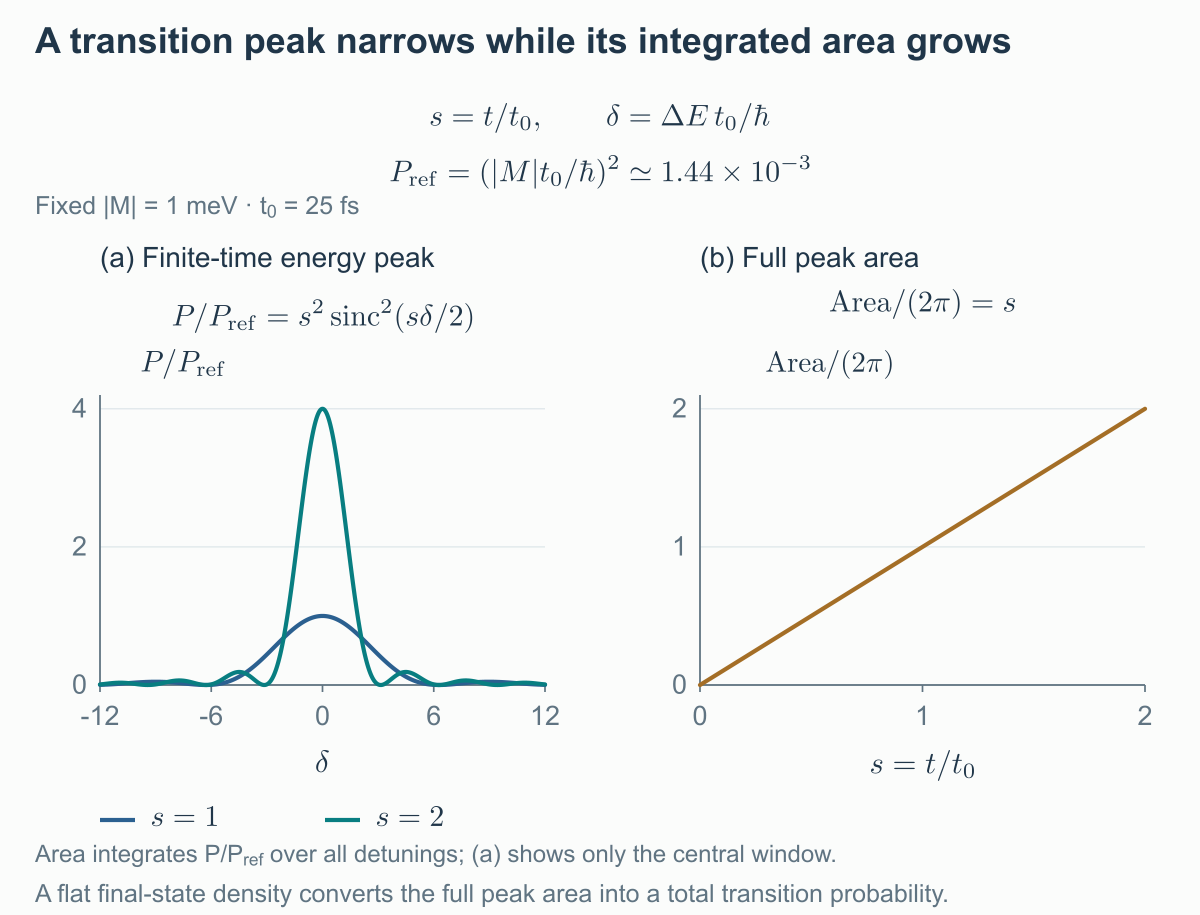

*그림 11. 결합 세기는 $1\,\mathrm{meV}$, 기준 시간은 $t_0=25\,\mathrm{fs}$다. (a) 시간이 지날수록 봉우리는 높고 좁아진다. 공명점의 확률은 시간의 제곱에 비례한다. (b) $\mathrm{Area}=\int_{-\infty}^{\infty}(P/P_{\rm ref})\,d\delta$는 (a)에서 잘라 낸 구간 바깥까지 포함해 무차원 곡선을 적분한 면적이다. 이 면적 자체가 전체 전이 확률은 아니다. 그래프의 $\mathrm{Area}/(2\pi)=t/t_0$는 시간에 비례한다. 최종 준위가 충분히 촘촘하고 상태 밀도가 매끄럽다면, 상태 밀도를 포함해 에너지에 대해 적분한 값이 전체 전이 확률이다. 그림에서 상태 하나로 전이할 확률은 1차 진폭을 쓸 수 있을 만큼 작다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-transition)




**공명점의 확률은 시간의 제곱에 비례하는데, 전체 전이 확률은 왜 시간에 비례할까?**


결합 행렬 원소 $M$과 최종 상태 밀도 $D_f$가 $E_a$ 근처에서 거의 일정하다고 하자. $D_f\,dE$는 초기 상태를 정했을 때 에너지 구간 $dE$에 있는 최종 상태의 수다. 따라서 $D_f$의 단위는 에너지의 역수다. 15절에서는 이 상태 수를 **단위 부피당** 값으로 센다는 점이 다르다. $\Delta E=E_b-E_a$를 쓰면

$$
\begin{aligned}
P_{\rm sum}(t)&\simeq\int_{-\infty}^{\infty}
D_f\,P_{a\to b}^{(1)}(t)\,d\Delta E\\
&=\frac{2\lvert M\rvert^2D_f t}{\hbar}
\int_{-\infty}^{\infty}\operatorname{sinc}^2y\,dy\\
&=\frac{2\pi}{\hbar}\lvert M\rvert^2D_f t.
\end{aligned}
$$

$y=\Delta E\,t/(2\hbar)$로 변수를 바꾸면 $\int_{-\infty}^{\infty}\operatorname{sinc}^2y\,dy=\pi$를 쓸 수 있다. 공명점의 전이 확률은 $t^2$에 비례하고, 적분에 주로 기여하는 에너지 폭은 $1/t$에 비례한다. 따라서 전체 확률은 $t$에 비례하며, 전이율은 $\Gamma=2\pi\lvert M\rvert^2D_f/\hbar$다. 봉우리가 밴드의 경계에서 충분히 멀리 떨어져 있으면 적분 범위를 무한대로 늘려도 결과가 거의 달라지지 않는다.

에너지 차이의 범위를 $-1$부터 $1\,\mathrm{eV}$로 제한하고, $M=10^{-7}\,\mathrm{eV}$, $D_f=10^6\,\mathrm{eV}^{-1}$로 두어 적분해 보자. 아래 코드는 연속 적분을 계산하기 위해 구간을 잘게 나눈다. 이 격자점들이 실제 에너지 준위를 나타내지는 않는다.


In [8]:
continuum_detunings = np.linspace(-1.0, 1.0, 40001)  # eV.
continuum_coupling_eV, continuum_dos_per_eV = 1e-7, 1e6
continuum_gamma = (2 * np.pi * abs(continuum_coupling_eV)**2
                   * continuum_dos_per_eV / (HBAR / E_CHARGE))
for continuum_time in (50e-15, 100e-15, 200e-15):
    continuum_p = first_order_probability(
        continuum_detunings, continuum_coupling_eV, continuum_time)
    continuum_total = continuum_dos_per_eV * np.sum(
        (continuum_p[:-1] + continuum_p[1:]) / 2
        * np.diff(continuum_detunings))
    assert 0 < continuum_total < 1e-3
    assert np.isclose(continuum_total / continuum_time,
                      continuum_gamma, rtol=0.01)
    print("time (fs), total P, rate / golden rate:",
          continuum_time * 1e15, continuum_total,
          continuum_total / continuum_time / continuum_gamma)


time (fs), total P, rate / golden rate: 50.0 4.732649429693988e-06 0.9915628110226089
time (fs), total P, rate / golden rate: 100.0 9.505602294889118e-06 0.995784905685763
time (fs), total P, rate / golden rate: 200.0 1.9051575724001707e-05 0.9978994989981068


Golden rule로 구한 전이율은 약 $9.54584\times10^7\,\mathrm{s}^{-1}$다. 유한한 에너지 구간에서 계산한 전이율은 시간 순서대로 이 값의 $0.99156$, $0.99578$, $0.99790$배다. 세 경우 모두 전체 전이 확률은 $2\times10^{-5}$보다 작다.



## 12. Matrix element 계산: wavefunction의 overlap과 momentum transfer


Golden rule에서 전이율을 정하는 것 중 하나가 행렬 원소의 절댓값 제곱이다. 이 행렬 원소를 구하려면 불순물 퍼텐셜뿐 아니라 초기 상태와 최종 상태의 파동함수도 알아야 한다. 초기 상태의 파동함수에 퍼텐셜과 최종 상태 파동함수의 켤레복소수를 곱해 공간에 대해 적분한다. 불순물 퍼텐셜의 모양이나 두 파동함수의 겹침이 달라지면 전이율도 달라진다.

밴드 가장자리에서 전자의 운동은 원자 간격보다 큰 길이 척도에서 서서히 변하는 파동함수의 포락선(envelope)으로 나타낼 수 있다. 아래의 **effective-mass envelope approximation**에서는 유효 질량을 하나의 스칼라 값으로 두고, 포락선을 평면파 기저로 전개한다. 단위 셀 안에서 Bloch 함수의 주기적인 부분이 얼마나 겹치는지는 따로 계산하지 않는다. 평면파 하나는 공간 전체에 퍼져 있지만, 7절에서 Bloch 상태를 겹쳤듯이 여러 평면파를 합하면 한곳에 모여 입사하는 wave packet을 나타낼 수 있다.

유효 질량이 일정한 양수인 등방적 포물선 밴드를 생각하자. 상태 수를 세기 위해 부피가 $\mathcal V$인 큰 상자를 두고, 그 안에서 정규화한 포락선 평면파를 $\psi_{\mathbf k}=e^{i\mathbf k\cdot\mathbf r}/\sqrt{\mathcal V}$로 쓴다. $1/\sqrt{\mathcal V}$를 곱하면 상자 안에서 확률 밀도의 적분이 1이 된다. 이 상자는 계산을 위한 것이므로 실제 소자 크기를 정하거나 접촉 저항을 설명하지는 않는다. 국소적으로 작용하는 퍼텐셜 $U(\mathbf r)$의 행렬 원소는

$$
\begin{aligned}
&M_{\mathbf k'\mathbf k}=\frac{1}{\mathcal V}\int d^3r\,U(\mathbf r)e^{-i(\mathbf k'-\mathbf k)\cdot\mathbf r}\\
&=\frac{\widetilde U(\mathbf q)}{\mathcal V},\\
&\mathbf q=\mathbf k'-\mathbf k,\\
&\widetilde U(\mathbf q)=\int d^3r\,U(\mathbf r)e^{-i\mathbf q\cdot\mathbf r}.
\end{aligned}
\tag{32}
$$

입사 평면파에 산란 후 평면파의 켤레를 곱하면 지수에 두 파동벡터의 차이 $\mathbf q$가 나타난다. **푸리에 변환(Fourier transform)**은 퍼텐셜을 파동벡터별 성분으로 나누는데, 이 행렬 원소에는 그중 산란 전후의 차이에 해당하는 성분만 들어간다. $\hbar\mathbf q$는 이때 전자에 전달된 결정 운동량이다. 위 정의에 따라 $U$와 $M$의 단위는 에너지이고, $\widetilde U$의 단위는 에너지와 부피의 곱이다.

퍼텐셜이 공간에서 완만하게 변할 때는 큰 $q$에서 지수 인자가 빠르게 진동해 서로 다른 위상의 기여가 대부분 상쇄된다. 따라서 운동량이 크게 바뀌는 산란은 억제된다. 이 포물선 밴드에서 탄성 산란 전후에는 파동벡터의 크기가 같으므로, 운동량 전달이 작다는 것은 방향이 조금만 꺾인다는 뜻이다. 반대로 좁은 영역에서 작용하는 섭동은 큰 운동량을 전달하는 성분도 상당히 가질 수 있다.

1차원 가우시안 퍼텐셜에서 적분값 $g=\int U(x)\,dx$는 그대로 두고 폭 $\ell$만 바꿔 보자.

$$
\begin{aligned}
&U_\ell(x)=\frac{g}{\sqrt{2\pi}\ell}e^{-x^2/(2\ell^2)},\\
&\widetilde U_\ell(q)=g\,e^{-q^2\ell^2/2},\\
&M_{k'k}=\frac{\widetilde U_\ell(k'-k)}{\mathcal L}.
\end{aligned}
\tag{33}
$$

1차원에서 $g$와 $\widetilde U$의 단위는 에너지와 **길이**의 곱이다. $\mathcal L$은 정규화에 쓴 상자의 길이다. $g$를 그대로 두고 $\ell$을 두 배로 늘리면 퍼텐셜의 높이는 절반이 된다. 운동량 전달이 없을 때의 $\widetilde U(0)=g$는 그대로지만, 운동량을 크게 전달하는 푸리에 성분은 더 작아진다.

$q\ell_0=1$로 놓으면 $\widetilde U/g$는 폭이 좁을 때 약 0.6065, 넓을 때 약 0.1353이다. 절댓값의 제곱은 각각 약 0.3679와 0.0183이다. 산란율에 들어가는 것은 이 제곱이므로, 퍼텐셜의 적분값이 같다고 해서 주어진 운동량 전달에서 산란율도 같은 것은 아니다.


In [9]:
ell0, box_length = 1e-9, 100e-9
g_1d = 0.1 * E_CHARGE * 1e-9  # 0.1 eV nm; energy times length.
x_grid = np.linspace(-12 * ell0, 12 * ell0, 12001)
dx = x_grid[1] - x_grid[0]
q_probe = 1.0 / ell0
for ell in (ell0, 2 * ell0):
    potential = g_1d / (np.sqrt(2 * np.pi) * ell) * np.exp(-x_grid**2 / (2 * ell**2))
    fourier_numeric = np.sum(potential * np.exp(-1j * q_probe * x_grid)) * dx
    fourier_exact = g_1d * np.exp(-0.5 * (q_probe * ell)**2)
    assert np.isclose(fourier_numeric / g_1d, fourier_exact / g_1d, atol=1e-8)
    print("width (nm), M (eV):", ell * 1e9, fourier_exact / box_length / E_CHARGE)


width (nm), M (eV): 1.0 0.0006065306597126337
width (nm), M (eV): 2.0 0.00013533528323661278


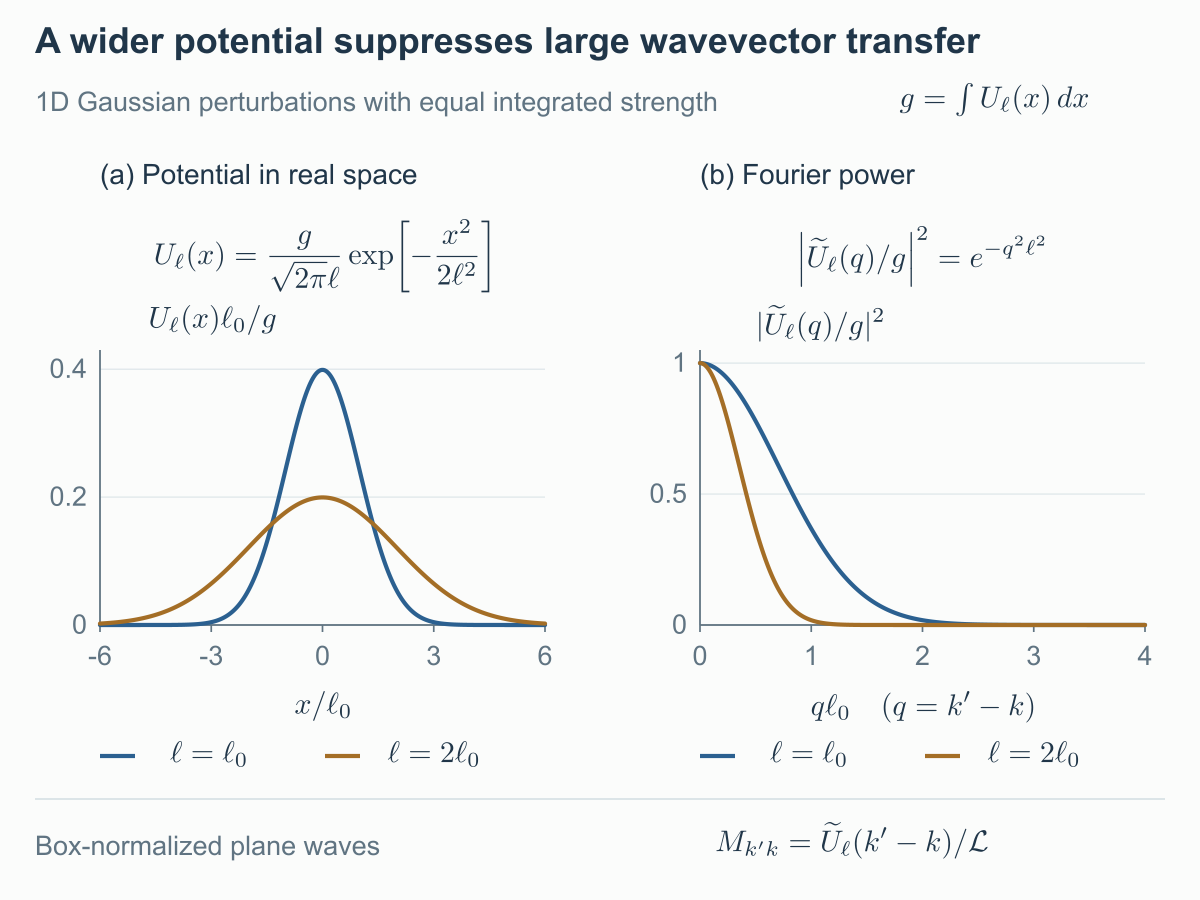

*그림 12. 기준 폭은 $\ell_0$이고, 두 곡선의 폭은 각각 $\ell=\ell_0$와 $2\ell_0$다. 두 1차원 가우시안 퍼텐셜은 높이가 다르지만 적분값 $g$는 같다. $q$는 산란 전후 파동벡터의 차이, $\hbar q$는 운동량 전달이다. 운동량이 바뀌지 않는 지점에서는 푸리에 파워가 같지만, 넓은 퍼텐셜 쪽이 큰 $q$에서 더 작다. 행렬 원소의 절댓값 제곱도 같은 모양을 따른다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-gaussian)


기준값은 $\ell_0=1\,\mathrm{nm}$, $g_{\rm ref}=1\,\mathrm{eV\,nm}$로 고정했다. Potential, Fourier amplitude, amplitude의 제곱은 단위가 다르므로 eV, eV nm, eV² nm²의 별도 축에 그린다. Wavevector transfer를 바꾸면 Fourier 곡선 자체가 아니라 곡선 위의 선택점과 세로 보조선이 움직인다. 처음 폭은 2 nm이므로 적분값을 고정할 때와 peak를 고정할 때의 차이가 바로 보인다. 폭이 1 nm이면 두 조건은 같은 potential을 준다.

불순물이 여러 개라면, 공간적으로 균일한 평균 퍼텐셜은 밴드 에너지에 포함하고 그 평균에서 벗어나는 부분만 산란에 넣는다. 불순물의 위치가 서로 독립적이면, 위치에 따라 달라지는 간섭항은 평균을 낼 때 사라진다. 남는 평균 산란율은 불순물 밀도 $n_i$에 비례한다. 정규화 상자의 부피는 행렬 원소와 최종 상태 수에 모두 들어가지만, 둘을 곱하면 계산에서 소거된다.



**불순물이 여러 개일 때 정규화 상자의 크기는 왜 결과에서 사라질까?**


서로 독립적인 위치 $\mathbf R_\alpha$에 같은 불순물이 $N_i$개 있으면 행렬 원소에 $\sum_\alpha e^{-i\mathbf q\cdot\mathbf R_\alpha}$가 곱해진다. 이 위상 합의 절댓값을 제곱한 뒤 위치에 대해 평균하면, 불순물 사이의 간섭을 뺀 성분은 $N_i$다. 공간적으로 균일한 평균 퍼텐셜은 산란을 일으키지 않으므로 밴드 에너지에 포함한다. 남은 비간섭 산란 성분은

$$
\begin{aligned}
&\left\langle\lvert M_{\mathbf k'\mathbf k}^{\rm total}\rvert^2\right\rangle
=\frac{N_i}{\mathcal V^2}\lvert\widetilde U(\mathbf q)\rvert^2,\\
&n_i=\frac{N_i}{\mathcal V}.
\end{aligned}
\tag{34}
$$

최종 상태를 합할 때는 $\mathcal V\int d^3k^{\prime}/(2\pi)^3$가 들어간다. 여기에 $N_i/\mathcal V^2$를 곱하면 상자 크기 대신 실제 불순물 밀도 $n_i$가 남는다. 불순물 위치에 상관관계가 있는 결정이라면 그 영향이 구조 인자(structure factor)로 추가된다.

Bloch 상태를 직접 쓰면 단위 셀 안에서의 겹침이나 오비탈의 종류, 스핀, 밴드 번호도 행렬 원소에 영향을 줄 수 있다. 식 (32)는 이 세부 구조를 제외하고 스칼라 포락선으로 계산한 결과다.



## 13. Matrix element, scattering amplitude, cross section


12절처럼 3차원 등방적 포물선 밴드에서 약한 정적 불순물 퍼텐셜을 쓰고, 불순물 위치는 서로 독립적이라고 하자. Golden rule에서 각 최종 상태의 기여는 결합의 절댓값 제곱에 비례한다. 에너지 delta 때문에 그중 산란 전후의 에너지가 같은 상태만 남는다. $n_i$는 단위 부피당 불순물 수다. 초기 상태의 스핀을 정하고 산란 중 스핀이 뒤집히지 않는다고 가정하면, 같은 스핀의 최종 상태만 세므로 여기에 스핀 계수 $g_s$를 곱하지 않는다. 초기 상태에서 다른 상태로 나가는 전체 산란율은

$$
\begin{aligned}
&\Gamma_q(\mathbf k)=\frac{1}{\tau_q}\\
&=\frac{2\pi n_i}{\hbar}\int\frac{d^3k'}{(2\pi)^3}\lvert\widetilde U(\mathbf k'-\mathbf k)\rvert^2\delta(\epsilon_{\mathbf k'}-\epsilon_{\mathbf k}).
\end{aligned}
\tag{35}
$$

$\tau_q$에서 아래첨자 $q$는 **quantum**의 약자이며, 산란 전후 파동벡터의 차이 $\mathbf q$와는 무관하다. 약한 무질서 근사에서 이를 **단일 입자 탄성 산란 시간(single-particle 또는 quantum elastic lifetime)**이라 부른다. 산란율이 이전 이력에 의존하지 않는 모형에서는 전체 산란율의 역수가 초기 상태를 떠날 때까지의 평균 대기시간이다. 전류가 얼마나 바뀌든 모든 방향의 산란을 똑같이 한 번씩 센다. 다체계에서의 수명, 전자·정공의 재결합 시간, 전자의 에너지가 줄어드는 시간과는 구별해야 한다.

같은 불순물의 산란율을 구하는 또 다른 방법은, 입사파가 불순물을 만나 어느 방향으로 얼마나 퍼지는지 계산하는 것이다. 3차원에서 국소적인 산란체에 파동이 양의 $z$ 방향으로 입사한다고 하자. 산란체에서 멀리 떨어진 곳의 정상 산란 상태에는 입사 평면파와 바깥으로 퍼지는 구면파가 함께 있다. 구면파가 퍼지는 면적은 거리의 제곱에 비례해 커진다. 이 구면파의 계수인 **산란 진폭(scattering amplitude)**은 앞에서 구한 시간 의존 계수와 다른 양이다. $r$은 산란체까지의 거리, $k>0$는 입사 파동벡터의 크기다. $\theta$는 입사 방향에서 잰 각도이고, $\phi$는 입사 축을 중심으로 잰 방위각이다.

이 상태는 식 (32)처럼 상자 안의 확률 적분이 1이 되도록 정규화하지 않는다. 대신 입사 진폭을 1로 놓고, 이를 기준으로 입사 플럭스와 산란 플럭스를 비교한다. **1차 Born 근사(first Born approximation)**에서는 퍼텐셜이 없을 때의 입사파를 써서 산란 진폭을 퍼텐셜의 1차 항까지 구한다. 그 결과가 아래 두 번째 식이다.

$$
\begin{aligned}
&\psi(\mathbf r)\simeq e^{ikz}+f_{\rm sc}(\theta,\phi)\frac{e^{ikr}}{r},\\
&f_{\rm sc}^{\rm Born}(\theta,\phi)
=-\frac{m^{\ast}}{2\pi\hbar^2}\widetilde U(\mathbf q).
\end{aligned}
\tag{36}
$$

구면파의 계수 $f_{\rm sc}$는 $1/r$에 곱해지므로 길이 단위를 갖는다. 에너지 단위의 행렬 원소 $M_{ba}$나 단위가 없는 전이 진폭 $c_b(t)$와 구분해야 한다. [Zwiebach, Scattering, Sec. 7.3](https://ocw.mit.edu/courses/8-06-quantum-physics-iii-spring-2018/45dbd7038c3e969491eceeae86c44d42_MIT8_06S18ch7.pdf); [Tong, Scattering Theory, Sec. 6.3](https://davidtong.org/pdfs/teaching/topics-in-quantum-mechanics/topicsinqm6.pdf)

3차원에서 어느 방향으로 얼마나 넓게 퍼지는지는 **입체각(solid angle)**으로 잰다. 구면의 작은 조각에 해당하는 입체각은 $d\Omega=\sin\theta\,d\theta\,d\phi$다. **미분 산란 단면적(differential cross section)**은 한 방향으로 **단위 시간·단위 입체각당** 산란되는 입자 수를 입사 플럭스, 즉 단위 면적·단위 시간당 들어오는 입자 수로 나눈 값이다. 단위는 면적/steradian이다.

$$
\begin{aligned}
&\frac{d\sigma_{\rm sc}}{d\Omega}=\lvert f_{\rm sc}(\theta,\phi)\rvert^2,\\
&\sigma_{\rm sc}^{\rm total}=\int d\Omega\,\lvert f_{\rm sc}\rvert^2.
\end{aligned}
\tag{37}
$$

산란 단면적 $\sigma_{\rm sc}$는 전도도 $\sigma$와 다른 양이다. 불순물의 기하학적 단면적을 뜻하는 것이 아니라, 입사 플럭스를 단위 시간에 산란되는 입자 수로 환산하는 유효 면적이다. 입자 플럭스는 입자 수로 세고, 전류 밀도는 여기에 입자의 전하를 곱한 값이다. 이 단면적 관계는 3차원에서 성립한다. 12절의 1차원 예제에서는 최종 상태를 세는 방식이 다르므로 그대로 적용할 수 없다. 입사 속력이 $v=\hbar k/m^{\ast}$이고 불순물 밀도가 $n_i$이면 전자 하나의 전체 산란율은

$$
\Gamma_q=n_iv\int d\Omega\,\frac{d\sigma_{\rm sc}}{d\Omega}.
\tag{38}
$$

단위는 $(\mathrm{m}^{-3})(\mathrm{m/s})(\mathrm{m}^2)=\mathrm{s}^{-1}$다. 식 (38)에 Born 진폭으로 구한 단면적을 넣으면 식 (35)와 같은 값이 나온다. 식 (35)에서 파동벡터의 크기 $k^{\prime}$를 적분할 때 에너지 delta가 $m^{\ast}k/\hbar^2$를 남긴다. 하나는 운동량 공간에서 상태 수를 세어 얻은 산란율이고, 다른 하나는 입사 플럭스와 단면적으로 구한 같은 산란율이다.

예를 들어 $n_i=10^{22}\,\mathrm{m}^{-3}$, $v=10^5\,\mathrm{m/s}$, $\sigma_{\rm sc}^{\rm total}=10^{-18}\,\mathrm{m}^2$로 놓으면 전체 산란율은 $10^9\,\mathrm{s}^{-1}$이고 평균 대기시간은 1 ns다. 방향이 조금만 꺾여도, 완전히 뒤집혀도 이 계산에서는 모두 산란 한 번이다. 그러나 두 경우에 전류가 줄어드는 정도는 다르다.


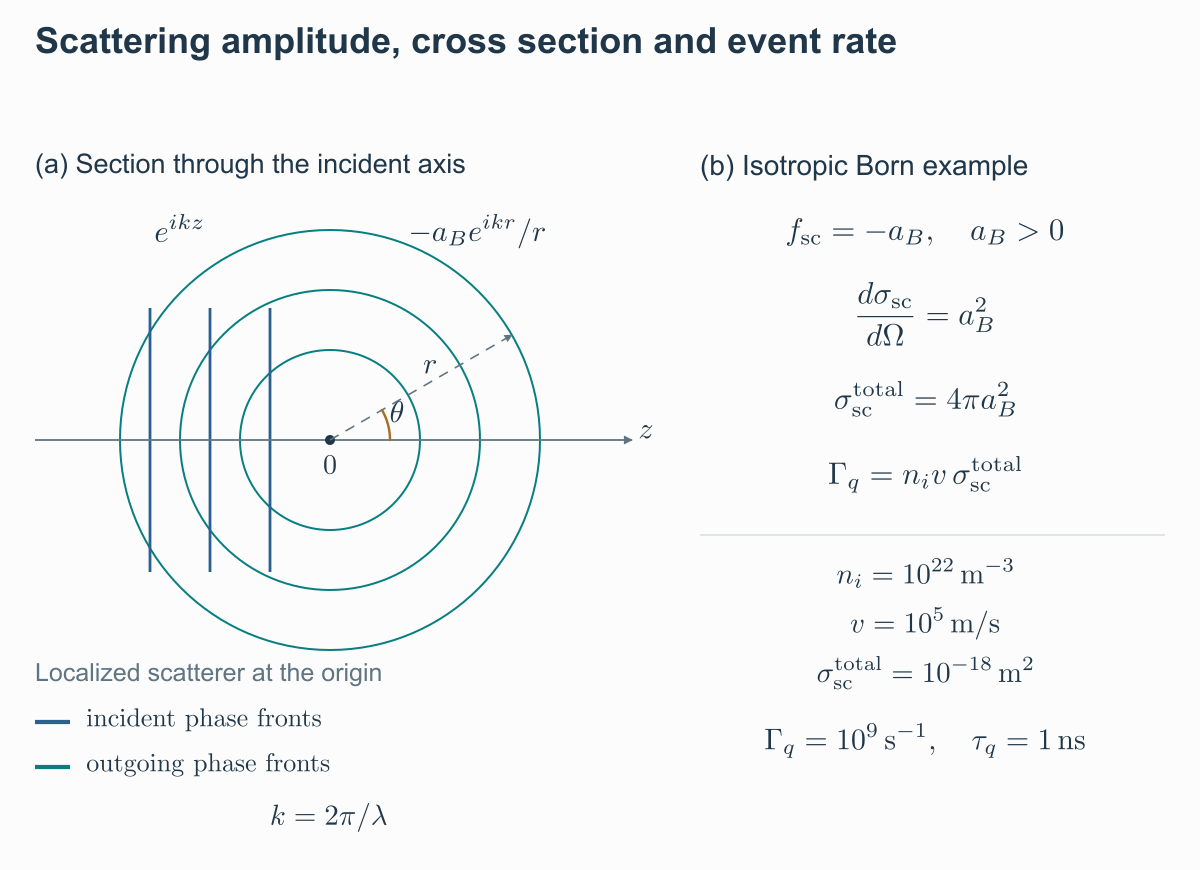

*그림 13. 왼쪽은 3차원 파동을 한 단면에서 본 모습이다. 직선과 원호는 위상이 같은 곳을 이은 파면으로, 서로 한 파장씩 떨어져 있다. 점선 화살표는 산란체에서의 거리와 방향을 나타내며 입자의 궤적은 아니다. 오른쪽은 모든 방향에서 Born 진폭이 $f_{\rm sc}=-a_B$로 같은 예다. $a_B>0$는 길이 단위다. 진폭의 절댓값을 제곱해 미분 산란 단면적을 얻고, 이를 모든 방향에 대해 적분하면 전체 단면적이 된다. 이 면적으로 본문의 산란율과 평균 대기시간을 계산한다.*


Born 근사를 쓰려면 계산하려는 에너지 범위에서 산란 퍼텐셜이 충분히 약해야 한다. 불순물 농도가 낮으면 불순물별 산란을 독립적으로 다루기 쉽다. 그렇다고 불순물 하나가 만드는 퍼텐셜까지 약해지는 것은 아니다. 실제 물질에 적용할 때는 퍼텐셜과 차폐(screening), 파동함수를 정한 뒤 섭동 근사가 성립하는지 따로 확인해야 한다.

## 14. Angular scattering의 quantum·transport relaxation time


전자 진행 방향이 조금 꺾여도, 완전히 뒤집혀도 산란은 한 번이다. 하지만 앞의 경우에는 원래 방향의 속도 성분이 거의 그대로 남고, 뒤의 경우에는 그 부호가 바뀐다. 따라서 전류가 얼마나 빨리 줄어드는지는 산란 횟수뿐 아니라 방향이 얼마나 바뀌는지에도 달려 있다.

등방적인 분산 관계를 갖는 밴드에서 에너지를 하나 고정하자. 탄성 산란으로는 속력이 바뀌지 않고 방향만 바뀐다. 어느 방향으로 입사하든 산란율이 산란 전후의 각도 $\theta$에만 의존한다고 가정한다. 방향을 단위 벡터 $\widehat{\mathbf k}=\mathbf k/\lvert\mathbf k\rvert$로 표시하고, 단위 입체각당 산란율을 $w(\theta)=n_iv\,d\sigma_{\rm sc}/d\Omega$로 쓰자. 한 방향의 점유는 다른 방향에서 전자가 들어오면 늘고, 다른 방향으로 나가면 줄어든다. 평형에서는 점유가 모든 방향에서 같아 유입과 유출이 상쇄된다. 따라서 선형화한 충돌 연산자에는 평형에서 벗어난 분포만 남는다.

$$
C[\delta f](\widehat{\mathbf k})
=\int d\Omega'\,w(\theta)
\left[\delta f(\widehat{\mathbf k}')-\delta f(\widehat{\mathbf k})\right].
\tag{39}
$$

전기장 $\mathbf E$와 전자의 파동벡터 $\mathbf k$ 사이의 각도를 $\alpha$라 하자. 산란 전후의 각도 $\theta$와는 다른 각도다. 에너지를 고정하면 식 (26)의 점유 변화는 $\delta f=A\cos\alpha$ 꼴이다. $A$는 부호를 갖는 작은 실수 계수이며, 앞의 도선 단면적과는 관계없다. 전기장을 기준으로 서로 반대쪽 반구의 점유가 반대 부호로 바뀌는 이 모양을 dipole이라 부른다. 전기장 반대쪽으로 움직이는 전자 상태는 점유가 늘고, 전기장 쪽으로 움직이는 상태는 점유가 줄어든다. 전자가 음전하를 띠므로 전류는 전기장 방향으로 흐른다. 점유가 모든 방향에서 같다면 반대 방향끼리 기여가 상쇄되어 순전류가 없다.

산란각을 고정하고 입사 축 주위의 방위각을 평균하면, $\widehat{\mathbf k}^{\prime}$에서 입사 방향에 수직인 성분은 상쇄된다. 그러면 산란 후 방향에서의 점유 변화는 평균적으로 $A\cos\alpha\cos\theta$다. 여기서 원래 방향의 점유 변화를 빼면, 산란각을 적분하기 전의 유입·유출 차이는 $A\cos\alpha(\cos\theta-1)$이 된다. 따라서 이 분포에 식 (39)를 적용하면 $C=-\delta f/\tau_{\rm tr}$이고, 두 이완율은 다음과 같다.

$$
\begin{aligned}
&\frac{1}{\tau_q}=\int d\Omega\,w(\theta),\\
&\frac{1}{\tau_{\rm tr}}=\int d\Omega\,w(\theta)(1-\cos\theta).
\end{aligned}
\tag{40}
$$

가중치 $1-\cos\theta$는 산란 전 속도 방향으로 투영한 성분이 원래 크기에 비해 얼마나 감소했는지 나타낸다. 방향이 조금만 꺾이면 거의 0이다. 산란 후 방향이 모든 입체각에서 고르게 나오면 평균값은 1이고, 정확히 뒤집히면 성분이 양수에서 같은 크기의 음수로 바뀌므로 감소량은 2배다. 충돌 연산자는 이 코사인 모양의 점유 변화를 다른 모양으로 바꾸지 않고 크기만 줄인다. 이것을 **angular relaxation eigenmode**라 부르며, 그 크기가 줄어드는 시간 척도가 스칼라 전도도에 들어가는 수송 이완 시간(transport relaxation time)이다. 비등방적이거나 비탄성인 산란에는 이 가중치 하나로 같은 계산을 할 수 없다. [Kim, Woo and Min, Eq. (1) and Sec. II](https://arxiv.org/html/1901.04135v2)

산란할 때마다 방향이 $10^\circ$씩 꺾이고 방위각은 무작위라면, 전류의 이완율은 전체 산란율의 $1-\cos10^\circ\simeq0.01519$배다. 따라서 수송 이완 시간은 산란 사이의 평균 대기시간보다 약 65.8배 길다. 산란을 여러 번 겪어도 조금씩만 꺾이면 처음에 움직이던 방향의 성분이 오래 남는다.


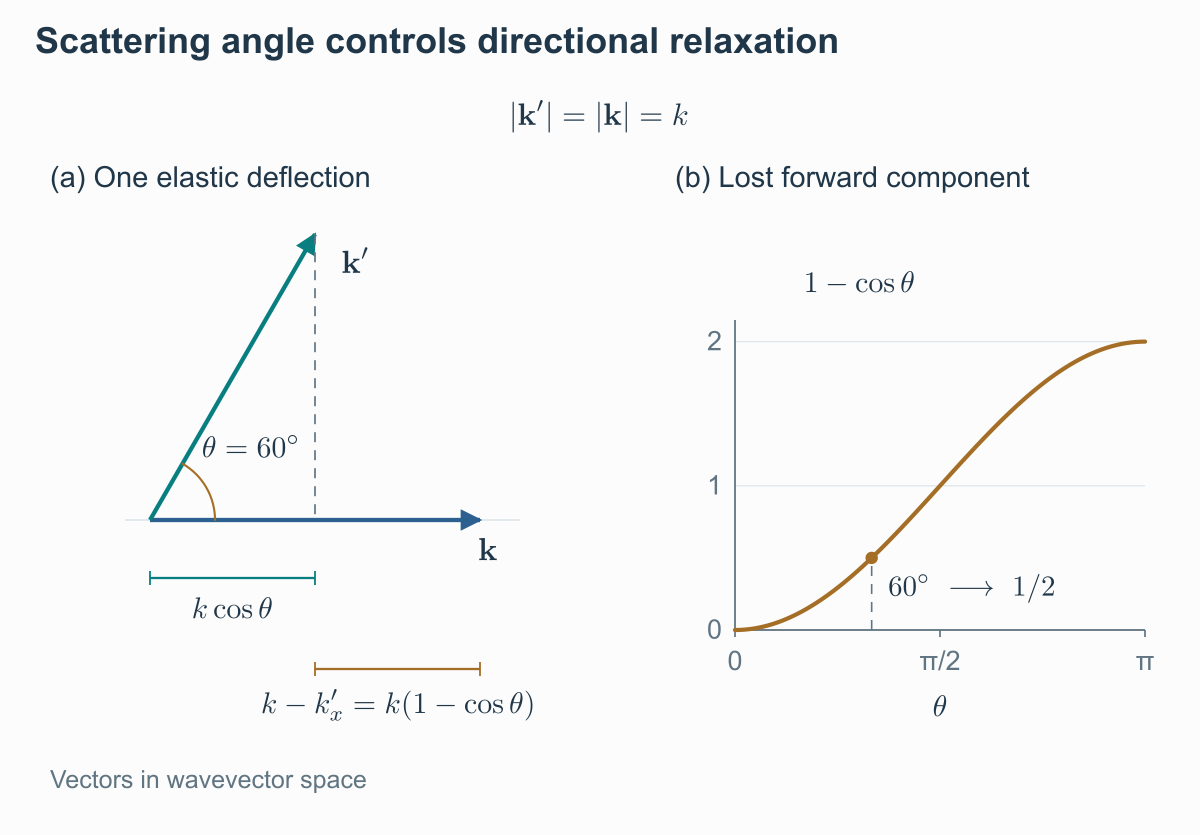

*그림 14. 산란 전후 파동벡터의 크기는 모두 $k$다. 산란 뒤에 입사 방향으로 남는 성분은 $k\cos\theta$이고, 감소량은 $k-k_x^{\prime}=k(1-\cos\theta)$다. 그림에는 $\theta=60^\circ$인 경우를 표시했다. 파동벡터 성분의 감소량에 $\hbar$를 곱하면 운동량 성분의 감소량이 된다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-angle)




**탄성 산란의 유입·유출 항에서 Pauli 인자가 상쇄되는 이유**


같은 가중치의 두 방향 상태 사이에 양방향 전이율이 같은 탄성 산란이 일어나면, 유입 항에서 유출 항을 뺀 점유 인자는 다음과 같다.

$$
f'(1-f)-f(1-f')=f'-f.
$$

이처럼 유입과 유출을 함께 계산하면 Pauli 인자가 상쇄된다. 같은 에너지의 모든 방향에서 점유가 같은 평형 분포는 변하지 않는다. 식 (39)가 나타내는 것은 한 전자가 Pauli 차단을 피해 특정 상태에서 나갈 확률이 아니라, 전체 점유 분포가 평형으로 돌아가는 과정이다. 식 (35)의 단일 입자 산란 시간 $\tau_q$를 해석할 때도 이 둘을 구별해야 한다. 비탄성 산란이나 전자 사이의 충돌에서는 일반적으로 에너지와 점유가 전이율에 미치는 영향도 고려해야 한다.



전기장을 꺼서 산란만 남겨 보자. 처음에 한쪽으로 움직이는 전자가 조금 더 많다고 하자. 산란이 없다면 각 전자는 그 방향을 유지한다. 반대로 같은 에너지에서 독립적인 산란이 반복되면, 현재 속도에 처음 방향의 성분이 얼마나 남아 있는지 평균했을 때 그 값이 줄어들 수 있다.

마지막 산란에서 얼마나 시간이 지났든 단위 시간당 산란율이 일정하다고 하자. 각도 가중치를 넣지 않은 전체 탄성 산란율은 $\Gamma_q$다. 한 번 산란한 뒤 직전 방향에 투영한 성분은 평균적으로 산란 전 값의 $\langle\cos\theta\rangle$배다. 이 평균의 가중치는 각 방향의 산란율을 전체 산란율로 나눈 값이다. 같은 방향으로 출발한 전자들이 서로 다른 산란을 겪은 뒤, 처음 방향으로 남은 성분을 평균하면

$$
\begin{aligned}
&\langle\widehat{\mathbf k}(t)\cdot\widehat{\mathbf k}(0)\rangle\\
&=\exp\!\left[-\Gamma_q\big(1-\langle\cos\theta\rangle\big)t\right].
\end{aligned}
\tag{41}
$$

앞쪽으로 조금만 꺾이는 산란이 대부분이면 $\tau_{\rm tr}\gg\tau_q$다. 반대로 방향이 크게 바뀌는 산란이 주로 일어나면 수송 이완 시간이 오히려 짧을 수 있다. 서로 반대인 두 방향 사이에서 어느 쪽이든 전이율 $r$로 뒤집히고, 그 전이율이 이전 이력과 무관한 모형에서는

$$
\begin{aligned}
&\frac{d(f_+-f_-)}{dt}=-2r(f_+-f_-),\\
&\tau_{\rm tr}=\frac{1}{2r},\\
&\tau_q=\frac{1}{r}.
\end{aligned}
\tag{42}
$$

방향이 한 번 뒤집히면 원래 방향의 속도 성분은 처음 크기의 두 배만큼 줄어든다. 따라서 다음 산란까지 걸리는 시간, 한쪽으로 치우친 속도 분포가 줄어드는 시간, 전자가 에너지를 잃는 시간은 서로 다르다.

## 15. Short-range impurity: 에너지를 고정한 scattering 계산


결함이 충분히 좁으면 전자가 산란하면서 주고받을 수 있는 운동량 범위에서 결함 퍼텐셜의 푸리에 성분이 거의 일정하다. 결함이 좁다는 조건과 Born 근사를 쓸 만큼 퍼텐셜이 약하다는 조건은 별개다. 두 조건을 만족하면 산란 진폭이 방향에 거의 무관해지고, 이 근사에서는 전체 산란율과 전류 이완율이 같아진다.

3차원 등방적 포물선 밴드에서 밴드 바닥을 기준으로 잰 운동에너지를 $K=\epsilon-E_c>0$라 하자. 결함이 전자 파장보다 충분히 작다면, 이 에너지에서 가능한 운동량 전달에 대해 푸리에 성분을 상수 $U_0$로 놓을 수 있다. Born 진폭의 크기를 길이 단위의 $a_B$로 정하면

$$
\begin{aligned}
&U_0=\frac{2\pi\hbar^2}{m^{\ast}}a_B,\\
&f_{\rm sc}^{\rm Born}=-a_B,\\
&\sigma_{\rm sc}^{\rm total}=4\pi a_B^2.
\end{aligned}
\tag{43}
$$

산란 후 방향은 모든 입체각에서 고르게 나온다. 따라서 14절의 각도 가중치가 평균 1이 되어 $\tau_{\rm tr}=\tau_q$다. $a_B$는 Born 진폭의 크기이지 결함의 반지름이 아니다. 푸리에 성분을 상수로 둔 것은 3차원에서 유한한 범위에 작용하는 약한 퍼텐셜을 낮은 운동량 전달에서 근사한 결과다. $a_B$만으로 모든 운동량 전달에서의 퍼텐셜을 정할 수는 없다.

상태 하나로 가는 진폭만으로는 전체 산란율을 구할 수 없다. 에너지를 보존하면서 도달할 수 있는 상태를 모두 세어야 한다. 등방적 포물선 밴드에서는 같은 에너지의 상태가 파동벡터 공간의 한 구면에 놓인다. 에너지 구간에 들어오는 상태를 세려면 이 구면 주위의 얇은 층을 보면 된다. 그 부피는 $4\pi k^2dk$다. 앞서 전도도를 구할 때와 같이 이 값을 $(2\pi)^3$로 나누고, $dK/dk=\hbar^2k/m^{\ast}$를 써서 에너지 변수로 바꾸면 단위 부피·단위 에너지·**스핀 하나당** 상태 밀도는

$$
\begin{aligned}
&D_1(K)=\frac{m^{\ast}k}{2\pi^2\hbar^2},\\
&k=\frac{\sqrt{2m^{\ast}K}}{\hbar}.
\end{aligned}
\tag{44}
$$

단위는 $\mathrm{J}^{-1}\mathrm{m}^{-3}$다. 상태 밀도는 채워졌든 비어 있든 해당 에너지에 존재하는 모든 상태를 센다. 각 상태의 점유는 별도로 반영한다. 이 상태 밀도를 golden rule에 넣고 적분하면

$$
\begin{aligned}
&\frac{1}{\tau_{\rm tr}}=\frac{1}{\tau_q}\\
&=\frac{2\pi n_i}{\hbar}\lvert U_0\rvert^2D_1(K)\\
&=n_iv\,4\pi a_B^2.
\end{aligned}
\tag{45}
$$

한 스핀으로 출발하면 산란 뒤에도 같은 스핀을 유지하므로, 최종 상태를 셀 때 2를 곱하지 않는다. 반면 전체 전류를 구할 때는 $n$ 또는 $g_s$에 같은 분포를 갖는 두 스핀 집단이 모두 들어간다.

$m^{\ast}=0.2m_0$, $K=50\,\mathrm{meV}$, $n_i=10^{25}\,\mathrm{m}^{-3}$, $a_B=0.2\,\mathrm{nm}$로 두자. 그러면 $k\simeq0.51232\,\mathrm{nm}^{-1}$, $v\simeq2.9655\times10^5\,\mathrm{m/s}$, $\tau_{\rm tr}\simeq0.67086\,\mathrm{ps}$다. 이 에너지의 이동도는 $e\tau_{\rm tr}/m^{\ast}\simeq0.58996\,\mathrm{m^2/(V\,s)}$다. 전자가 여러 에너지에 걸쳐 분포한다면 18절과 같이 에너지별 기여를 평균해야 한다.


In [10]:
impurity_mass, kinetic = 0.2 * M0, 0.050 * E_CHARGE
impurity_density, a_born = 1e25, 0.2e-9
k_shell = np.sqrt(2 * impurity_mass * kinetic) / HBAR
v_shell = HBAR * k_shell / impurity_mass
u0 = 2 * np.pi * HBAR**2 * a_born / impurity_mass  # J m^3.
dos_one_spin = impurity_mass * k_shell / (2 * np.pi**2 * HBAR**2)
rate_dos = 2 * np.pi / HBAR * impurity_density * u0**2 * dos_one_spin
rate_flux = impurity_density * v_shell * 4 * np.pi * a_born**2
tau_impurity = 1 / rate_flux
assert np.isclose(rate_dos / rate_flux, 1.0)
print("tau (ps), shell mobility (m^2/Vs):", tau_impurity * 1e12,
      E_CHARGE * tau_impurity / impurity_mass)
print("mean free path (nm):", v_shell * tau_impurity * 1e9)


tau (ps), shell mobility (m^2/Vs): 0.6708639326399617 0.5899644538131571
mean free path (nm): 198.9436788648691


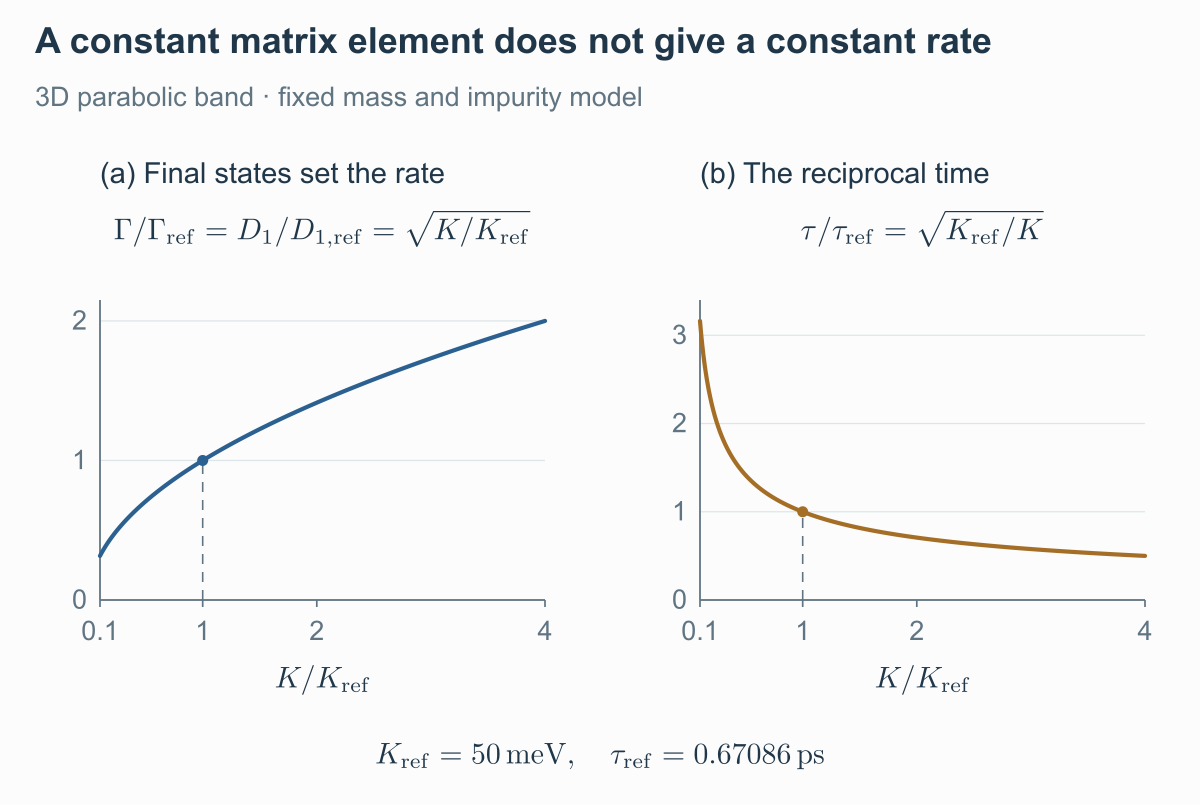

*그림 15. 유효 질량, 불순물 밀도, Born 진폭은 일정하다. 행렬 원소는 방향에 무관하지만, 에너지가 높을수록 최종 상태의 밀도가 커진다. 따라서 산란율 $\Gamma=1/\tau$는 커지고 그 역수인 이완 시간은 짧아진다. 두 점은 같은 기준 에너지를 표시한다. 가로축의 에너지는 밴드 바닥을 기준으로 잰 양수다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-impurity)


전자 하나하나는 빠르게 움직여도, 서로 반대 방향의 속도가 평균에서 상쇄되면 drift 속도는 작다. 전자가 진행 방향의 기억을 잃을 때까지 이동하는 거리의 척도인 **수송 평균 자유 행로(transport mean free path)**에는 평균 drift 속도가 아니라, 주어진 에너지에서 전자 한 개의 속력을 넣는다. 여기에 수송 이완 시간을 곱하면

$$
\ell_{\rm tr}=v\tau_{\rm tr}.
\tag{46}
$$

이 예제에서는 $\ell_{\rm tr}\simeq198.94\,\mathrm{nm}$, $k\ell_{\rm tr}\simeq101.92$다. 국소적인 확산 수송의 저항으로 설명하려면 시료가 평균 자유 행로보다 충분히 커야 하고, 전자가 그 거리를 가는 동안 전기장이 분포를 크게 바꾸지 않아야 한다. 파동벡터 크기의 역수는 위상이 달라지는 미시적 거리 척도다. 수송 평균 자유 행로가 이보다 훨씬 길면, 산란으로 방향의 기억이 사라지기 전에 파동의 위상이 여러 번 바뀔 만큼 이동할 수 있다. $k\ell$이 크면 약한 무질서 가정과 일관되지만, 개별 결함에 Born 근사를 적용할 수 있다는 뜻은 아니다. 이를 확인하려면 이 예제에서 입력으로 정한 $a_B$뿐 아니라 결함 퍼텐셜의 범위와 세기도 알아야 한다.

## 16. Screened Coulomb scattering의 quantum·transport rate


앞의 short-range 예제에서는 Fourier transform이 각도에 따라 달라지지 않아 두 lifetime이 같았다. Elastic scattering이라고 해서 항상 그런 것은 아니다. 공간에서 완만하게 변하는 potential은 wavevector가 조금만 바뀌는 산란을 더 잘 일으킬 수 있다. 전하를 띤 결함이 그 예다. 결함 주위의 이동 전하가 재배치되고 배경 물질이 분극하면 멀리까지 미치는 전기장이 약해진다. 이 현상을 **screening**이라고 한다. 방향에 무관한 간단한 screened potential energy와 그 Fourier transform은 다음과 같다.

$$
\begin{aligned}
&U(r)=\frac{Ze^2}{4\pi\varepsilon}\frac{e^{-q_sr}}{r},\\
&\widetilde U(q)=\frac{Ze^2}{\varepsilon(q^2+q_s^2)}.
\end{aligned}
\tag{47}
$$

$Z$는 전자가 느끼는 potential energy의 부호를 정하는 계수다. 양전하를 띤 결함은 전자를 끌어당기므로 이 표기에서는 계수가 음수다. Born amplitude의 부호도 이에 따라 바뀌지만 rate에는 절댓값의 제곱이 들어간다. 양의 $q_s$는 screening length의 역수다. 결함 주위의 전하 분포를 직접 풀어 구하는 대신, **Yukawa** potential과 screening length를 주어진 값으로 둔다. [Tong, Sec. 6.3.2](https://davidtong.org/pdfs/teaching/topics-in-quantum-mechanics/topicsinqm6.pdf)

Elastic scattering에서는 산란 전후의 wavevector 크기가 같다. 이 공통 크기를 $k=\lvert\mathbf k\rvert=\lvert\mathbf k^{\prime}\rvert$로 쓴다. 두 벡터 사이의 각도로부터 wavevector 변화량을 구하면

$$
\begin{aligned}
&q=\lvert\mathbf k'-\mathbf k\rvert=2k\sin\frac{\theta}{2},\\
&x_s=\frac{4k^2}{q_s^2}.
\end{aligned}
\tag{48}
$$

식 (48)의 무차원수는 산란 전후 wavevector가 최대로 달라질 때의 변화량을 screening wavevector로 나눈 뒤 제곱한 값이다. Screening wavevector가 가능한 변화량보다 훨씬 크면 식 (47)의 분모는 산란 각도에 따라 거의 바뀌지 않는다. 반대로 $q_s\ll k$이면 matrix element는 $\theta=0$ 부근에서 크고, 큰 각도에서는 작다. 이때 산란이 잦아 single-particle broadening이 크더라도, 산란 한 번에 진행 방향이 조금씩만 바뀌어 전류는 훨씬 천천히 줄어들 수 있다. 두 rate를 계산하기 위해 $z=1-\cos\theta$, $C_U=Ze^2/\varepsilon$로 두고 방위각을 적분하면

$$
\begin{pmatrix}\Gamma_q\\\Gamma_{\rm tr}\end{pmatrix}
=\frac{n_im^{\ast}kC_U^2}{2\pi\hbar^3}
\int_0^2\frac{1}{(q_s^2+2k^2z)^2}
\begin{pmatrix}1\\z\end{pmatrix}dz.
\tag{49}
$$

두 적분을 계산하면

$$
\begin{aligned}
B(x_s)&=\ln(1+x_s)-\frac{x_s}{1+x_s},\\
\Gamma_q&=\frac{n_im^{\ast}kC_U^2}{\pi\hbar^3q_s^4(1+x_s)},\\
\Gamma_{\rm tr}&=\frac{n_im^{\ast}C_U^2}{8\pi\hbar^3k^3}B(x_s).
\end{aligned}
\tag{50}
$$

두 lifetime의 비를 취하면 결함과 전자 사이의 coupling 세기에 해당하는 공통 인자가 약분된다.

$$
\begin{aligned}
&\frac{\tau_{\rm tr}}{\tau_q}=\frac{\Gamma_q}{\Gamma_{\rm tr}}\\
&=\frac{x_s^2}{2(1+x_s)B(x_s)}.
\end{aligned}
\tag{51}
$$

$x_s\to0$이면 matrix element의 각도 의존성이 사라져 두 시간의 비가 1에 가까워진다. $x_s\gg1$에서는 이 비가 대략 $x_s/[2(\ln x_s-1)]$에 따라 커진다. 다만 $q_s=0$을 그대로 대입하면 forward 방향의 특이점 때문에 유한한 total rate를 얻을 수 없다.

수치적분에도 입체각의 가중치가 필요하다. $\sin\theta$를 빼고 $\theta$에 대해 적분하면 같은 폭의 각도 구간이 차지하는 입체각이 서로 다르다는 점을 놓친다. 아래의 256점 적분은 $0<x_s\le400$에서 해석식과 대조했다. 더 큰 $x_s$에서는 forward peak가 더 좁아져 이 적분법으로 놓치기 쉽다. 이때는 각도 분해능을 높이거나, 필요한 구간을 더 촘촘히 나누는 adaptive integration 또는 변수 변환을 써야 한다.


In [11]:
nodes, gauss_weights = np.polynomial.legendre.leggauss(256)
z_angle = nodes + 1.0  # z=1-cos(theta) lies in [0,2]; dz=dx here.

def screened_time_ratio(shape):
    if not np.isfinite(shape) or not 0 < shape <= 400:
        raise ValueError("This fixed-order quadrature is verified for 0 < x_s <= 400")
    kernel = 1 / (1 + shape * z_angle / 2)**2
    total = gauss_weights @ kernel
    transport = gauss_weights @ (kernel * z_angle)
    return total / transport

for shape in (0.01, 4.0, 100.0):
    bshape = np.log1p(shape) - shape / (1 + shape)
    analytic = shape**2 / (2 * (1 + shape) * bshape)
    assert np.isclose(screened_time_ratio(shape), analytic, rtol=1e-9)
    print("x_s, tau_tr/tau_q:", shape, analytic)


x_s, tau_tr/tau_q: 0.01 1.0033278035504052
x_s, tau_tr/tau_q: 4.0 1.976680330167093
x_s, tau_tr/tau_q: 100.0 13.656457044536154


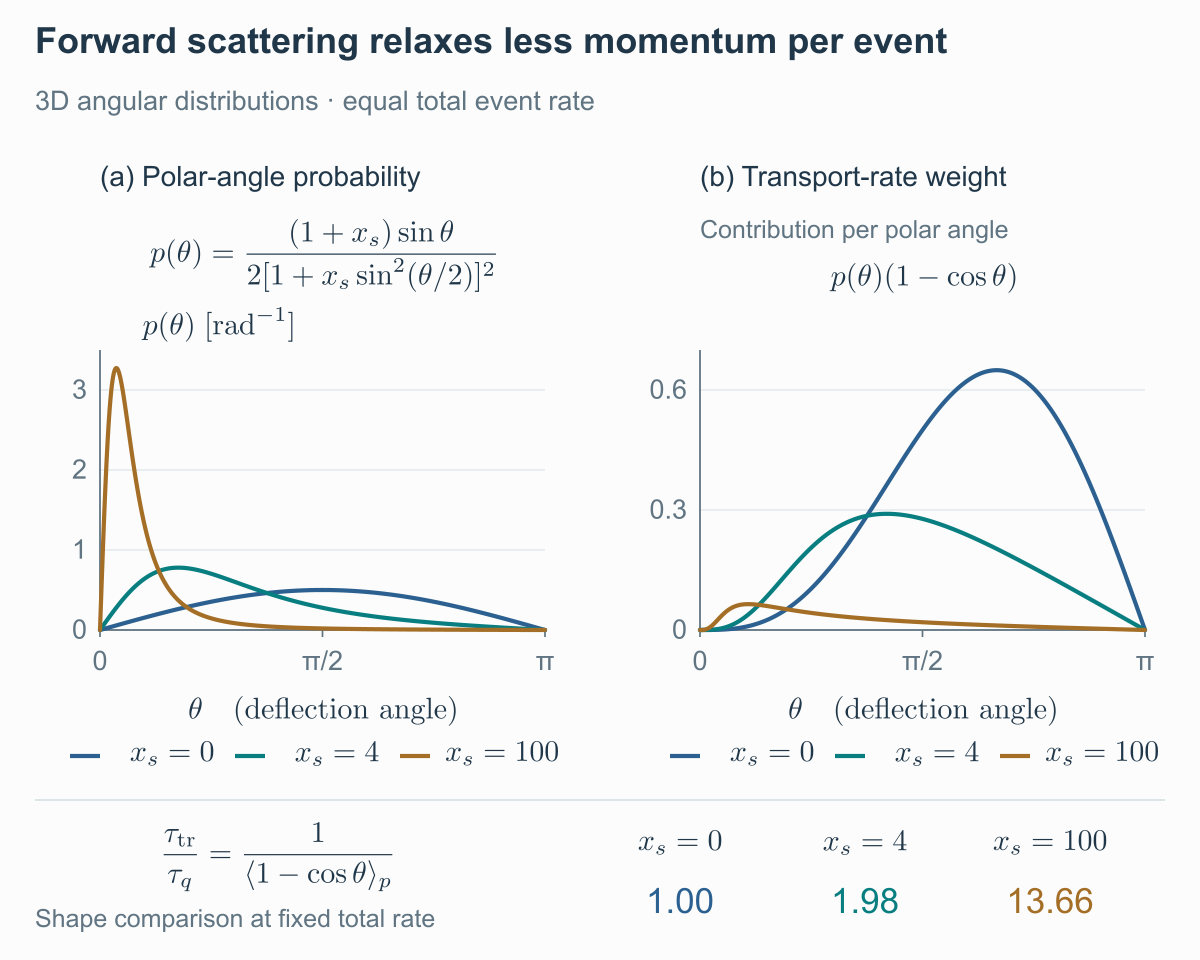

*그림 16. $\sin\theta$까지 포함한 각도 분포를 적분값이 1이 되도록 정규화했다. Total event rate를 고정하고 $x_s=0,4,100$을 비교했다. $x_s=0$인 등방적 극한에서는 단위 입체각당 확률이 일정하지만, 같은 폭의 polar angle 구간이라도 실제 입체각은 서로 다르다. 그래서 $p(\theta)=\sin\theta/2$는 수평선이 아니다. $1-\cos\theta$를 곱하면 forward 쪽에 몰린 산란은 진행 방향의 momentum을 거의 줄이지 않는다는 점이 드러난다. 이 그림에서는 각도 분포의 모양을 비교하려고 rate를 고정했다. 결함 potential의 세기를 고정하고 screening만 바꾼 결과와는 다르다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-scattering)


등방적 산란부터 forward에 집중된 산란까지 바꿔 보면서 전류를 줄이는 데 효과적인 각도가 어디인지 확인할 수 있다. 진행 방향을 매번 뒤집는 경우는 별도의 두 방향 모델이다. 여기서는 total event rate를 일정하게 두지만, 실제로 $n_i,Z,k$를 고정하고 screening을 바꾸면 식 (50)에 따라 total rate도 달라진다.



**Screening wavevector는 어디에서 나올까?**


선형 정적 screening 모델에서 작은 electrostatic potential은 전자의 국소 에너지를 $-e\varphi$만큼 바꾼다. Reservoir의 chemical potential이 일정하다면 그에 따른 전자 밀도 변화는 $\delta n=e\varphi\,\partial n/\partial\mu_F$다. 이 밀도 변화가 만든 전하를 Poisson 방정식에 넣으면 다음과 같은 screening wavevector가 나온다.

$$
q_s^2=\frac{e^2}{\varepsilon}\frac{\partial n}{\partial\mu_F}.
$$

고전적인 nondegenerate 기체에서는 $\partial n/\partial\mu_F=n/(k_BT)$를 대입하면 Debye 식이 된다. 반면 단순한 band에 전자가 낮은 에너지부터 차례로 들어찬 온도 0의 경우, 이 미분값은 Fermi energy에서의 **전체** DOS다. Screening에 기여하는 모든 spin을 세므로 식 (44)의 spin 하나당 final-state DOS와는 다르다.

결함 potential이 강하거나 nonlocal screening, 전자 사이의 상관관계, 여러 band, 낮은 차원의 영향이 중요하면 이 선형 모델로 구한 값과 달라질 수 있다. Charged-defect mobility를 예측하려면 Born approximation이 맞는 조건인지와 screening을 어떻게 모델링할지 각각 판단해야 한다. 식 (51)은 주어진 potential에서 두 lifetime의 비를 구할 뿐이다.



## 17. Longitudinal acoustic phonon의 deformation-potential scattering


정적인 불순물에 산란된 전자는 방향이 바뀌어도 에너지가 그대로다. 전자와 격자 사이의 에너지 교환까지 설명하려면 격자의 운동을 포함해야 한다. 격자가 진동하면 원자의 위치와 함께 전자의 Hamiltonian이 변한다. **Phonon**은 그 격자 진동의 양자다. Electron–phonon matrix element는 원자 변위에 따른 Hamiltonian의 변화를 산란 전후의 전자 상태 사이에서 계산한 값이다.

격자 전체를 통째로 옮기면 bulk band edge는 그대로다. 반면 격자를 누르거나 늘리면 원자 사이의 간격이 달라져 band edge의 에너지도 바뀐다. Longitudinal acoustic **deformation-potential** 모델에서는 전자가 원자의 절대 위치가 아니라 국소적인 부피 변화에 반응한다고 본다. Conduction-band edge의 이동량을 부피의 상대 변화에 비례한다고 두면

$$
U_{\rm ac}(\mathbf r)=D\,\nabla\cdot\mathbf u_{\rm lat}(\mathbf r).
\tag{52}
$$

$\mathbf u_{\rm lat}$는 격자의 변위다. 전자의 drift $\mathbf u$와 기호는 비슷하지만 전혀 다른 물리량이다. 변위의 divergence는 부피가 얼마나 늘거나 줄었는지를 나타내는 무차원 strain이다. $D$는 strain에 따른 band edge의 이동량을 정하므로 에너지 단위를 갖는다. 면적/시간 단위인 2절의 diffusion coefficient $D$와 구분하자. 이 모델은 여러 electron–phonon coupling 가운데 부피 변화가 band edge를 이동시키는 효과를 다룬다. [Bardeen and Shockley](https://doi.org/10.1103/PhysRev.80.72)

Normal mode는 원자들이 일정한 패턴을 이루며 함께 진동하는 방식이다. Wavevector에 따라 이어지는 mode의 계열을 phonon branch라고 한다. Longitudinal acoustic branch 하나를 잡아 $q=\lvert\mathbf q\rvert$, $\omega_q=v_sq$로 두자. $v_s$는 음속이다. Longitudinal은 변위가 wavevector와 평행하다는 뜻이고, acoustic은 $q$가 0으로 가면 주파수도 0으로 간다는 뜻이다. 변위를 양자화하고 mode의 임의 위상을 phonon operator의 정의에 포함하면 전자와 phonon 사이의 coupling 계수는

$$
\begin{aligned}
&M_q=Dq\sqrt{\frac{\hbar}{2\rho_m\mathcal V\omega_q}},\\
&\lvert M_q\rvert^2=
\frac{D^2\hbar q}{2\rho_m\mathcal Vv_s}.
\end{aligned}
\tag{53}
$$

$\rho_m$은 질량 밀도이며 단위는 $\mathrm{kg/m^3}$다. Charge density $\rho$와는 다르다. 식 (53)의 제곱근은 단위가 m인 변위 진폭이다. 여기에 $q$를 곱하면 strain이 되고, $D$를 더 곱하면 에너지 단위가 된다. 인자 $q$는 식 (52)에서 변위를 공간에 대해 미분할 때 생긴다. 이 계수는 정규화한 진동 mode 하나와의 coupling을 나타낸다. 실제 transition rate에는 mode에 들어 있는 phonon 수와 에너지 보존 조건도 필요하다.



**Harmonic oscillator로 phonon displacement와 absorption/emission 인자 구하기**


질량 $M$, 주파수 $\omega$인 quantum harmonic oscillator에서 변위의 기준 크기는 $\sqrt{\hbar/(2M\omega)}$다. 격자 진동을 부피로 정규화하면 질량 자리에 $\rho_m\mathcal V$가 들어간다. Longitudinal mode의 변위장을 쓰면

$$
\begin{aligned}
\widehat{\mathbf u_{\rm lat}}(\mathbf r)
&=\sum_{\mathbf q}\sqrt{\frac{\hbar}{2\rho_m\mathcal V\omega_q}}\,
\mathbf e_{\mathbf q}\\
&\quad\left(\widehat a_{\mathbf q}e^{i\mathbf q\cdot\mathbf r}
+\widehat a_{\mathbf q}^{\dagger}e^{-i\mathbf q\cdot\mathbf r}\right),
\end{aligned}
$$

$\mathbf e_{\mathbf q}$는 $\mathbf q$와 평행한 실수 단위벡터로, 원자가 움직이는 방향을 나타낸다. $D\nabla\cdot\widehat{\mathbf u_{\rm lat}}$에서 공간 미분을 하면 $i\mathbf q\cdot\mathbf e_{\mathbf q}$가 생긴다. 이 가운데 $i$는 phonon operator의 위상 정의에 포함할 수 있다. 그러면 식 (53)의 계수 $M_q$를 얻으며, $\lvert M_q\rvert^2$는 위상을 어디에 두든 같다.

Phonon 수가 정수 $N$인 상태에 ladder operator를 작용시키면

$$
\begin{aligned}
\widehat a\lvert N\rangle&=\sqrt N\,\lvert N-1\rangle,\\
\widehat a^{\dagger}\lvert N\rangle&=\sqrt{N+1}\,\lvert N+1\rangle.
\end{aligned}
$$

따라서 matrix element의 절댓값 제곱에는 absorption이면 $N$, emission이면 $N+1$이 곱해진다. 열평형에서는 $N$ 대신 평균 phonon 수 $N_q$를 넣는다. 처음부터 비어 있는 mode에도 phonon을 새로 만들 수 있어 emission의 1은 남는다. $\widehat a$와 $\widehat{\mathbf u_{\rm lat}}$의 hat은 quantum operator를 표시한다. 14절의 $\widehat{\mathbf k}$에서 단위벡터를 표시한 hat과는 뜻이 다르다.



열평형에서 mode 하나에 들어 있는 평균 phonon 수는 $N_q=1/[\exp(\hbar\omega_q/(k_BT))-1]$이다. 전자 상태 하나의 점유 확률과 달리, 한 mode에 phonon이 여러 개 있을 수 있다. Absorption에서는 기존 phonon 하나를 없애고, emission에서는 비어 있는 mode에도 phonon을 새로 만든다. 두 과정에 곱해지는 occupation factor가 다른 이유다. Golden rule을 적용하면

$$
\begin{aligned}
&W^{\rm abs}_{\mathbf k\to\mathbf k+\mathbf q}=\frac{2\pi}{\hbar}\lvert M_q\rvert^2N_q\\
&\qquad\delta(\epsilon_{\mathbf k+\mathbf q}-\epsilon_{\mathbf k}-\hbar\omega_q),\\
&W^{\rm em}_{\mathbf k\to\mathbf k-\mathbf q}=\frac{2\pi}{\hbar}\lvert M_q\rvert^2(N_q+1)\\
&\qquad\delta(\epsilon_{\mathbf k-\mathbf q}-\epsilon_{\mathbf k}+\hbar\omega_q).
\end{aligned}
\tag{54}
$$

Phonon을 흡수하면 전자의 에너지가 늘고, 방출하면 줄어든다. Emission에 붙는 1 덕분에 처음부터 비어 있는 mode에도 자발 방출이 가능하다. 식 (54)는 Pauli blocking을 적용하기 전의 transition rate다. 전자가 처음 상태에 있고 최종 상태는 비어 있어야 한다는 조건은 gain–loss collision equation에 넣는다. 여기서는 작은 wavevector의 intraband normal process만 다룬다. 일반적으로는 crystal momentum의 보존 관계에 reciprocal-lattice vector가 더해질 수도 있다.

이처럼 산란 전후의 전자 에너지가 다르면 한 energy shell에서 빠져나간 전자가 다른 shell로 들어간다. 따라서 일반적인 inelastic scattering에서는 shell을 따로 떼어 계산하거나, 앞서 쓴 각도 인자 $1-\cos\theta$만으로 전류의 감소율을 구할 수 없다.

### Equipartition과 quasielastic 근사의 조건

한 energy shell에서 계산한 식을 다시 쓰려면 두 조건을 확인해야 한다. 첫째, phonon이 충분히 많이 점유되어 mode 하나의 평균 열에너지를 $k_BT$로 볼 수 있어야 한다. 이것이 equipartition 근사다. 둘째, 전자가 phonon을 흡수하거나 방출할 때의 에너지 변화가 전자 쪽 에너지 척도에 비해 작아야 한다. 첫째 조건이 둘째를 보장하지는 않는다.

산란에 기여하는 phonon에 대해 $k_BT\gg\hbar\omega_q$이면 $N_q\simeq k_BT/(\hbar\omega_q)$로 근사한다. Phonon 에너지가 관련 전자 에너지 척도보다도 충분히 작다면 quasielastic 근사를 쓸 수 있다. 식 (54)의 두 delta function에서 에너지 변화량을 무시하고 같은 elastic delta function으로 놓으면, 흡수와 방출의 가중치를 더해

$$
\lvert M_q\rvert^2(2N_q+1)
\simeq\frac{D^2k_BT}{\rho_m\mathcal Vv_s^2}.
\tag{55}
$$

이 근사에서는 $q$에 따라 달라지던 coupling과 occupation factor가 서로 상쇄된다. 최종 상태에 대해 합하면 정규화 부피도 약분되어

$$
\begin{aligned}
&\frac{1}{\tau_{\rm ac}(K,T)}=\frac{2\pi}{\hbar}\frac{D^2k_BT}{\rho_mv_s^2}D_1(K)\\
&\ \propto\ T\sqrt K.
\end{aligned}
\tag{56}
$$

이제 산란율이 각도에 따라 달라지지 않으므로 이 근사에서는 transport time과 single-particle time이 같다. 전자 에너지의 변화를 그대로 포함하는 원래의 inelastic 문제에는 이 결론을 적용할 수 없다. [MIT 6.730, electron–phonon scattering lectures](https://ocw.mit.edu/courses/6-730-physics-for-solid-state-applications-spring-2003/pages/lecture-notes/); [Giustino, Sec. III and erratum](https://doi.org/10.1103/RevModPhys.89.015003)


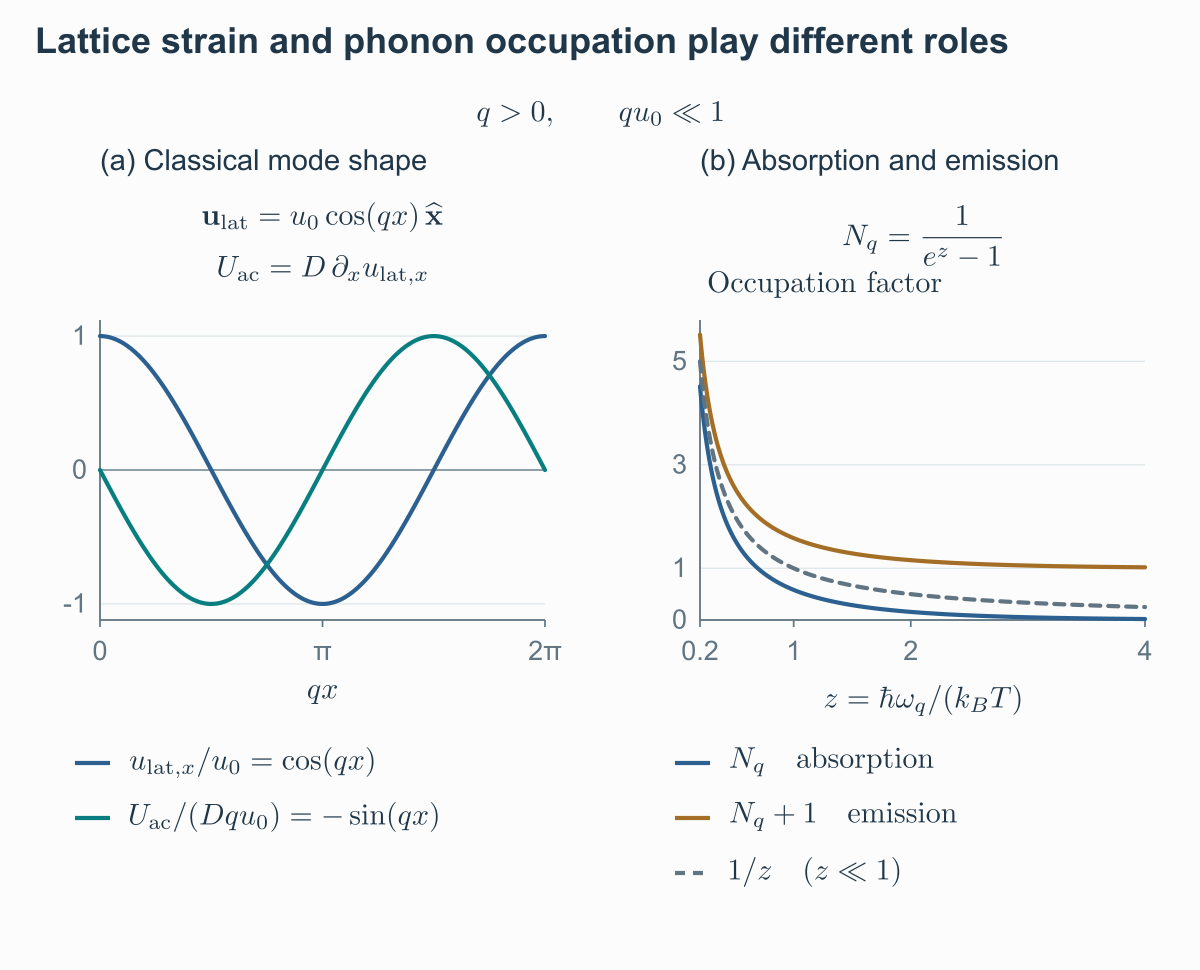

*그림 17. (a) Strain은 고전적인 격자 변위를 공간에 대해 미분한 값이다. 따라서 변위가 가장 큰 위치와 band edge가 가장 크게 변하는 위치는 다르다. 이 그림은 mode의 공간 패턴을 그린 것이며, phonon 수가 정해진 양자 상태의 평균 변위를 그린 것이 아니다. (b) 흡수와 방출에 곱해지는 Bose occupation factor를 비교했다. $\hbar\omega_q/(k_BT)$가 작을수록 점선의 high-occupation 근사가 잘 맞는다. 전자의 에너지 변화까지 무시할 수 있는지는 별도로 판단해야 한다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-phonon)


In [12]:
deformation_J, lattice_density, sound_speed = 5 * E_CHARGE, 5000.0, 5000.0
temperature = 300.0
ac_strength = deformation_J**2 * KB * temperature / (lattice_density * sound_speed**2)
rate_acoustic = 2 * np.pi / HBAR * ac_strength * dos_one_spin
assert ac_strength > 0 and rate_acoustic > 0
print("Illustrative acoustic tau at 50 meV (ps):", 1e12 / rate_acoustic)
print("Doubling T multiplies this fixed-energy rate by:", 2.0)
q_max_elastic = 2 * k_shell  # Elastic geometry, used to check the approximation.
phonon_energy_max = HBAR * sound_speed * q_max_elastic
print("Phonon energy estimate, kBT, electron K (meV):",
      phonon_energy_max / E_CHARGE * 1e3,
      KB * temperature / E_CHARGE * 1e3, kinetic / E_CHARGE * 1e3)
assert np.isclose(phonon_energy_max / E_CHARGE * 1e3, 3.372, rtol=1e-3)
assert np.isclose(KB * temperature / E_CHARGE * 1e3, 25.852, rtol=1e-5)
assert phonon_energy_max < 0.14 * KB * temperature
assert phonon_energy_max < 0.07 * kinetic


Illustrative acoustic tau at 50 meV (ps): 1.8563741480054137
Doubling T multiplies this fixed-energy rate by: 2.0
Phonon energy estimate, kBT, electron K (meV): 3.3721299237441 25.851999786435535 50.0


수치 예제로 $D=5\,\mathrm{eV}$, $\rho_m=5000\,\mathrm{kg/m^3}$, $v_s=5000\,\mathrm{m/s}$인 등방적 물질을 가정했다. Elastic scattering에서의 기하학적 상한 $q\le2k$로 계산한 phonon 에너지는 약 $3.372\,\mathrm{meV}$다. 이 값은 $k_BT=25.852\,\mathrm{meV}$의 약 $0.130$, $K=50\,\mathrm{meV}$의 약 $0.0674$다. 에너지 변화를 작다고 근사한 것이지 0이라고 한 것은 아니다. 온도가 더 낮거나 transition threshold에 가깝거나 optical·polar·intervalley phonon을 다룬다면 식 (56)의 근사가 여전히 맞는지 다시 확인해야 한다.



**실제 물질의 electron–phonon matrix element는 어떻게 구할까?**


전자의 Bloch state와 phonon mode를 구하고, 각 normal mode의 변위가 screening을 포함한 전자 potential을 어떻게 바꾸는지 계산한다. 이 potential 변화를 산란 전후의 Bloch state 사이에 넣어 적분하고, phonon 변위의 정규화 인자를 곱하면 matrix element가 된다. 산란 전후의 band와 전자 wavevector, phonon의 wavevector와 branch에 따라 값이 달라진다.

Deformation-potential 모델은 긴 파장 근사에서 이 복잡한 의존성을 strain에 따른 band edge의 기울기 하나로 나타낸다. First-principles 방법에서는 mode마다 potential이 어떻게 변하는지와 전자 상태 사이의 overlap을 직접 구한다. 그 결과로 mobility를 얻으려면 occupation과 에너지 보존을 반영한 transport equation까지 풀어야 한다. Transition probability를 모두 더해 $\tau$ 하나를 정하는 것만으로는 충분하지 않다.

[EPW](https://docs.epw-code.org/)는 electron–phonon interpolation과 transport 계산을 구현한다. 바탕이 되는 matrix-element formalism은 [Giustino의 review](https://doi.org/10.1103/RevModPhys.89.015003)에서 유도한다. [2019 erratum](https://doi.org/10.1103/RevModPhys.91.019901)에는 current density의 정규화와 선형화한 transport equation의 정정 내용이 실려 있다.



## 18. Mobility를 정하는 transport time의 에너지 평균


앞에서는 에너지가 같은 전자들만 놓고 impurity scattering과 acoustic phonon scattering을 계산했다. 실제로는 에너지가 다른 전자들이 섞여 있고, 에너지가 다르면 속도와 transport time도 달라질 수 있다. $\tau_{\rm tr}$가 에너지에 따라 달라질 때 $\mu=e\tau/m^{\ast}$의 시간 자리에 어떤 평균을 넣어야 할까?

전기장에 따른 전류 변화를 계산하면 속도 인자가 두 번 들어간다. 먼저 전기장 방향의 속도 성분에 비례해 상태의 occupation이 바뀐다. 그 변화량을 전류로 바꿀 때도 같은 속도 성분을 한 번 더 곱한다. DOS는 각 에너지에서 그렇게 셀 상태가 얼마나 있는지를 알려 준다.

등방적인 3차원 parabolic band에서 모든 spin을 포함한 DOS를 $D(K)=g_sD_1(K)$로 쓴다. $K$는 band minimum에서 잰 에너지다. 여기서 DOS의 기호는 앞서 쓴 deformation potential이나 diffusion coefficient와 구분해야 한다. 모든 방향에 대해 평균하면 $\langle v_x^2\rangle=v^2/3$이므로

$$
\begin{aligned}
n&=\int_0^\infty D(K)f_0(K)\,dK,\\
\sigma_0&=\frac{e^2}{3}\int_0^\infty D(K)v^2(K)\tau_{\rm tr}(K)
\left(-\frac{\partial f_0}{\partial K}\right)dK,\\
\mu&=\frac{\sigma_0}{en}=\frac{e\tau_{\rm eff}}{m^{\ast}}.
\end{aligned}
\tag{57}
$$

마지막 줄의 $\tau_{\rm eff}$는 mobility 식을 만족하도록 정한 평균 시간이다. 전자 수만 세어서 낸 평균과는 보통 다르다. 전류에는 빠른 전자에 더 큰 가중치가 붙고, 전기장이 occupation을 얼마나 바꾸는지도 중요하다. 전기장이 분포를 조금 밀어도 이미 가득 찬 영역의 occupation은 거의 그대로이고, 채워진 영역의 가장자리에서만 눈에 띄게 바뀐다. 그래서 저온의 degenerate 기체에서는 $-\partial_Kf_0$가 Fermi energy 부근에 몰린다. Nondegenerate 기체에서는 이 가중치가 열에너지 척도에 걸쳐 넓게 퍼진다.

Nondegenerate 기체에 대해서는 $-\partial_Kf_0=f_0/(k_BT)$이고, parabolic band에서는 $D(K)v^2(K)\propto K^{3/2}$다. 에너지 적분을 부분적분하면

$$
\begin{aligned}
&\int_0^\infty K^{3/2}e^{-K/(k_BT)}\,dK\\
&=\frac32 k_BT\int_0^\infty K^{1/2}e^{-K/(k_BT)}\,dK.
\end{aligned}
$$

에너지 구간 양 끝에서 경계항은 0이다. 이 관계를 식 (57)에 대입하고 전자 밀도로 나누면 가중치의 적분으로 나눈 평균을 얻는다.

$$
\tau_{\rm eff}=
\frac{\displaystyle\int_0^\infty K^{3/2}\tau_{\rm tr}(K)e^{-K/(k_BT)}\,dK}
{\displaystyle\int_0^\infty K^{3/2}e^{-K/(k_BT)}\,dK}.
$$

분자와 분모의 가중치가 같으므로 $\tau$가 일정하면 평균도 그 값이다. 반대로 입자 수에 따라 평균을 내면 속도의 제곱이 빠져 가중치가 $K^{1/2}e^{-K/(k_BT)}$로 바뀐다. $\tau_{\rm tr}(K)=\tau_{\rm ref}(K/K_{\rm ref})^r$로 놓자. 양의 기준 에너지를 하나 골라 그때의 시간을 기준값으로 삼고, 에너지에 따라 시간이 얼마나 빨리 늘거나 줄지는 지수로 정한다. 두 적분에 $y=K/(k_BT)$를 대입하면

$$
\begin{aligned}
&\tau_{\rm eff}=\tau_{\rm ref}
\left(\frac{k_BT}{K_{\rm ref}}\right)^r
\frac{\Gamma(r+5/2)}{\Gamma(5/2)},\\
&r>-5/2.
\end{aligned}
\tag{58}
$$

지수의 범위는 band minimum 부근에서 conductivity 적분이 발산하지 않도록 정해진다. 여기서 $\Gamma(z)$는 scattering rate $\Gamma_q$가 아니라 gamma function이다. 양의 $z$에서 $\Gamma(z)=\int_0^\infty y^{z-1}e^{-y}dy$이며, $\Gamma(n+1)=n!$를 만족해 factorial을 확장한다. 인자 $r+5/2$에는 $\sqrt K$에 비례하는 3차원 DOS, $K$에 비례하는 속도의 제곱, 그리고 에너지 적분이 함께 반영되어 있다.

$\tau$가 일정하면 식 (58)은 그 $\tau$를 돌려준다. 고온 acoustic 모델에서는 $\tau(K,T)\propto T^{-1}K^{-1/2}$다. 에너지에 대한 평균에서 $T^{-1/2}$가 한 번 더 곱해진다. 따라서 질량과 coupling parameter가 일정하고 전자가 nondegenerate 상태를 유지하는 범위에서는 $\mu\propto T^{-3/2}$다. 물질과 산란 방식이 달라지면 온도 의존성도 달라질 수 있다.

15절의 short-range impurity 모델도 산란율이 속력에 비례하므로 $r=-1/2$다. 같은 기준값인 $K_{\rm ref}=50\,\mathrm{meV}$와 $\tau_{\rm ref}=0.670864\,\mathrm{ps}$를 쓰고, $300\,\mathrm K$의 nondegenerate 기체를 가정하자. 전류에 맞게 가중 평균을 내면 $\tau_{\rm eff}=0.701837\,\mathrm{ps}$이고, 이에 해당하는 mobility는 $\mu=0.617202\,\mathrm{m^2/(V\,s)}$다. 같은 시간들을 입자 수에 따라 평균하면 $1.052755\,\mathrm{ps}$가 나온다. 이 값을 mobility 식에 넣으면 conductivity를 $1.5$배로 과대평가한다.


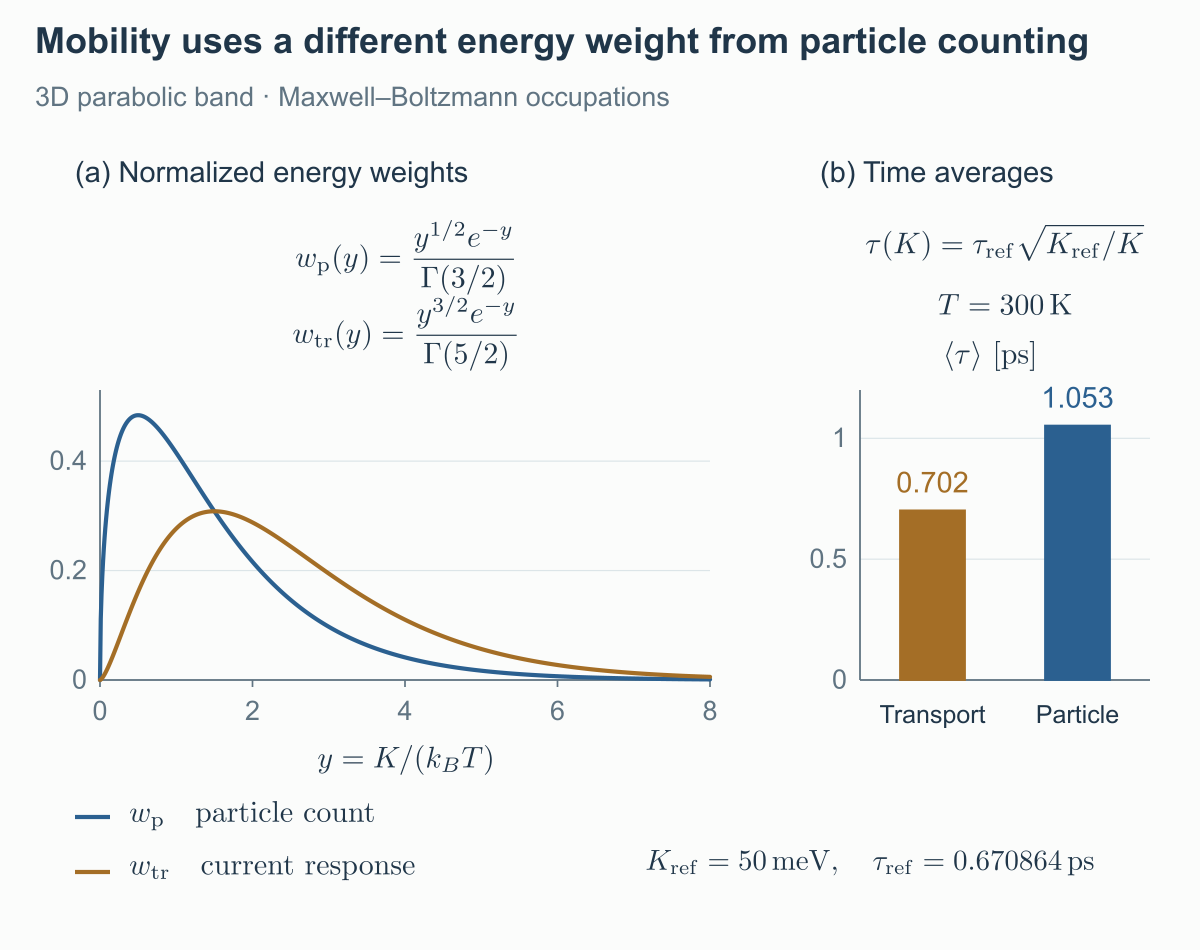

*그림 18. (a) 입자 수를 셀 때의 가중치와 전류를 계산할 때의 가중치다. 둘 다 양의 에너지 전체에 대해 적분하면 1이지만, 전류 가중치는 입자 수 가중치보다 높은 에너지의 전자에 더 큰 비중을 둔다. (b) 같은 relaxation time이라도 어느 가중치로 평균하느냐에 따라 값이 다르다. Mobility 식에 들어가는 것은 전류에 맞게 평균한 값이다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-average)


두 weight는 같은 kinetic energy 축에 meV 단위로 표시한다. 온도를 높이면 가로축이 늘어나는 대신 분포가 실제로 넓어지고 낮아진다. 평균 시간은 온도에 따라 어떻게 달라지는지 ps 단위로 그렸다. 시간의 범위가 넓어서 세로축에는 고정된 log10 scale을 쓴다. 세로축에서 1만큼 올라가면 시간이 열 배가 된다는 뜻이다. Particle average가 발산하는 경우에는 유한한 곡선처럼 그리지 않는다. Energy 그래프의 표시 범위와 달리 평균은 양의 에너지 전체에 대한 analytic integral로 구한다.


In [13]:
def mb_transport_time(tau_ref, energy_ref_J, temperature_K, exponent):
    if tau_ref <= 0 or energy_ref_J <= 0 or temperature_K <= 0 or exponent <= -2.5:
        raise ValueError("Positive scales and exponent > -5/2 are required")
    return tau_ref * (KB * temperature_K / energy_ref_J)**exponent * gamma(exponent + 2.5) / gamma(2.5)

assert np.isclose(mb_transport_time(100e-15, 0.05 * E_CHARGE, 300, 0) / 100e-15, 1)
tau_ac_300 = 1 / rate_acoustic  # Reference energy is the same 50 meV as above.
eff_300 = mb_transport_time(tau_ac_300, kinetic, 300, -0.5)
eff_600 = mb_transport_time(tau_ac_300 / 2, kinetic, 600, -0.5)
assert np.isclose(eff_600 / eff_300, 2**(-1.5))
print("Acoustic-model mobility ratio mu(600K)/mu(300K):", eff_600 / eff_300)
impurity_eff_300 = mb_transport_time(tau_impurity, kinetic, 300, -0.5)
impurity_mobility_300 = E_CHARGE * impurity_eff_300 / impurity_mass
impurity_particle_tau_300 = (tau_impurity * (KB * 300 / kinetic)**(-0.5)
                             * gamma(1.0) / gamma(1.5))
assert np.isclose(impurity_eff_300 * 1e12, 0.701836862, rtol=1e-8)
assert np.isclose(impurity_mobility_300, 0.617202357, rtol=1e-8)
assert np.isclose(impurity_particle_tau_300 * 1e12, 1.052755292, rtol=1e-8)
assert np.isclose(impurity_particle_tau_300 / impurity_eff_300, 1.5)
print("Impurity transport tau (ps), mobility (m^2/Vs), particle tau (ps):",
      impurity_eff_300 * 1e12, impurity_mobility_300,
      impurity_particle_tau_300 * 1e12)


Acoustic-model mobility ratio mu(600K)/mu(300K): 0.35355339059327373
Impurity transport tau (ps), mobility (m^2/Vs), particle tau (ps): 0.7018368615952544 0.6172023573954767 1.052755292392882


서로 독립적인 약한 산란 과정이 같은 에너지에서 동일한 전류 모드를 감쇠시킨다면, 에너지마다 rate를 먼저 더하고 나서 평균을 낸다. 산란 과정마다 시간을 먼저 평균하면 mobility가 달라질 수 있다. 역수를 취하는 순서와 평균을 내는 순서를 일반적으로 바꿀 수 없기 때문이다.



**독립적인 scattering mechanism과 Matthiessen's rule**


서로 독립적인 약한 산란 과정의 collision operator는 더할 수 있다. 여기서 쓰는 등방적 모델에서는 주어진 에너지에서 같은 angular mode를 감쇠시키는 산란 과정끼리 rate를 더한다.

$$
\frac{1}{\tau_{\rm tr}^{\rm total}(K)}
=\sum_\alpha\frac{1}{\tau_{\mathrm{tr},\alpha}(K)}.
\tag{59}
$$

이 관계를 **Matthiessen's rule**이라 한다. 질량이 같고 각 relaxation time이 에너지에 무관하다면 $1/\mu_{\rm total}=\sum_\alpha1/\mu_\alpha$도 성립한다. 그러나 에너지 의존성이 서로 다르면 mobility의 역수부터 더해선 안 된다. 에너지마다 rate를 먼저 합하고 식 (57)을 적분해야 한다. 결함들이 서로 상관되어 있거나 산란 과정마다 감쇠시키는 angular eigenmode가 다르면 rate를 단순히 더하는 것부터 성립하지 않을 수 있다.

실제 물질에서는 band mass와 transport time을 별개로 바꾸기 어렵다. Band mass가 달라지면 속도, DOS, screening이 달라지고 matrix element도 흔히 바뀐다. 질량이 작을수록 mobility가 높다는 결론은 transport time과 나머지 조건이 같을 때만 적용된다.



## 19. Periodic bulk density mode의 감쇠와 진동


균일한 도선에서는 양 끝의 전압을 주고 전하가 쌓이지 않는 경우를 계산했다. 이번에는 전자가 조금 많은 곳과 조금 부족한 곳이 번갈아 있고, 처음에는 평균 drift가 없다고 하자. 밀도가 고르지 않아 전기장이 생기고, 그 전기장에 전자가 움직이면 밀도와 전기장이 다시 바뀐다. 어느 한쪽을 미리 정할 수 없으므로 continuity equation, Poisson equation, 운동 방정식을 함께 풀어야 한다.

Contact의 영향 없이 bulk 안에서 전자가 어떻게 재분배되는지 보자. 3차원 전자 유체에서 밀도, 전기장, drift가 $x$ 방향 위치에만 의존하고, 그 방향으로 같은 cell이 반복된다고 가정한다. 아래에 나오는 drift velocity, 전기장, 전류는 모두 그 방향의 성분이다. $n_0=N_D$는 전자의 기준 수 밀도가 고정 양전하의 수 밀도와 같다는 뜻이다. 단위는 여전히 부피당 입자 수다. 전자의 운동 자체가 1차원으로 제한된 wire의 Coulomb field와 plasma dispersion은 실제 단면 구조를 반영해 따로 계산해야 한다. 외부 전압은 없고 $m^{\ast},\tau,\varepsilon$은 일정하다고 두자. 작은 밀도 변화 $\delta n$과 drift velocity에 대해 선형화하면

$$
\begin{aligned}
&\partial_t\delta n+n_0\partial_xu=0,\\
&\partial_xE=-\frac{e\delta n}{\varepsilon},\\
&\partial_tu+\frac{u}{\tau}=-\frac{eE}{m^{\ast}}.
\end{aligned}
\tag{60}
$$

$\delta n$, $u$, $E$를 모두 작은 양으로 보고 1차 항만 남긴다. Particle flux $(n_0+\delta n)u$에서 $n_0u$는 1차지만 $\delta n\,u$는 작은 양을 두 번 곱하므로 2차다. 유체가 속도가 다른 곳으로 흘러갈 때 생기는 convective acceleration $u\partial_xu$도 같은 이유로 뺀다. 반면 밀도 구배가 만드는 압력에 의한 힘은 1차부터 나타나므로 선형화만으로 없앨 수 없다. 여기서는 긴 파장에서 Coulomb force가 주된 복원력이 되는 경우를 택해 압력과 diffusion을 따로 무시한다. 이 조건이 아니면 thermal pressure나 Fermi pressure가 유한한 wavevector에서 dispersion을 바꾼다. 배경 permittivity는 1절에서 정한 양의 실수 $\varepsilon$을 쓴다.

전기장은 **quasistatic** 근사로 구한다. 관심 있는 길이와 시간 척도에서는 전자기장이 퍼지는 데 걸리는 시간과 유도 전기장을 무시하고, 그 순간의 전하 분포를 Poisson equation에 넣는다. 이는 $\omega\tau\ll1$을 가정하는 것과는 다르다. 식 (60)의 운동 방정식에는 전자의 관성이 남아 있다.

밀도가 cosine 모양이면 전자가 많은 곳과 부족한 곳이 번갈아 나타나며, 한 주기에서 전자 수의 증가분과 감소분이 상쇄된다. 밀도 패턴의 wavenumber를 $q>0$로 놓고 $qL_{\rm cell}=2\pi$로 잡으면 길이 $L_{\rm cell}$인 cell에 파장 하나가 들어간다. Continuity equation은 전자가 모이는 양을 밀도 변화에 연결한다. Drude equation은 전기장이 속도를 어떻게 바꾸는지, Poisson equation은 밀도가 전기장의 공간 변화를 어떻게 만드는지를 정한다. 첫 번째 식을 시간에 대해 미분하고 Drude equation으로 $\partial_tu$를, Poisson equation으로 $\partial_xE$를 바꾸면 밀도 모드 $\delta n=\mathcal A(t)\cos qx$에 대해

$$
\begin{aligned}
&\ddot{\mathcal A}+\frac{\dot{\mathcal A}}{\tau}+\omega_p^2\mathcal A=0,\\
&\omega_p^2=\frac{n_0e^2}{\varepsilon m^{\ast}}.
\end{aligned}
\tag{61}
$$

$\omega_p$는 momentum damping이 없을 때의 밀도 진동 각주파수다. 압력의 영향이 작은 범위로 $qv_{\rm char}\ll\omega_p$를 택할 수 있다. 여기서 $v_{\rm char}$는 대표적인 thermal speed 또는 Fermi speed다.

$\mathcal A$는 전자 수 밀도의 진폭으로, 도선의 단면적 $A$와는 다른 양이다. 부호가 바뀌면 전자가 많았던 곳과 부족했던 곳이 뒤바뀐다. 기준 밀도에 이 작은 밀도 변화가 더해져 전체 밀도 분포를 이룬다. 전자가 과하게 모이면 다시 퍼지게 하는 전기장이 생긴다. 전자의 관성 때문에 밀도가 균일한 순간에도 전자는 계속 움직일 수 있다. 한편 momentum relaxation이 진행되면 밀도 변화의 진폭은 결국 줄어든다. Cell에서 전기장과 전류의 공간 평균을 0으로 두면 각 위치에서

$$
\begin{aligned}
\delta n(x,t)&=\mathcal A(t)\cos qx,\\
E(x,t)&=-\frac{e\mathcal A(t)}{\varepsilon q}\sin qx,\\
J(x,t)&=\frac{e\dot{\mathcal A}(t)}{q}\sin qx.
\end{aligned}
\tag{62}
$$

마지막 줄을 $x$로 미분한 값은 $\partial_t\rho=-e\dot{\mathcal A}\cos qx$와 부호가 반대여서 둘을 더하면 0이다. 즉 전하가 사라지는 것이 아니라 전자가 자리를 옮긴다. Cosine의 공간 평균은 한 주기에서 0이므로 밀도 변화의 진폭이 줄어들어도 전체 전자 수는 그대로다.

초기조건을 $\mathcal A(0)\ne0$, $\dot{\mathcal A}(0)=0$으로 잡자. 처음에는 밀도 차이로 전기장이 생기지만, 전자가 아직 평균적으로 움직이지 않아 $J(0)=0$이다. 관성이 있는 전자는 힘을 받아도 속도가 순간적으로 바뀌지 않는다. 따라서 steady state에서 성립하는 $J=\sigma_0E$를 처음부터 적용할 수 없다.

밀도가 고르게 되는 순간에도 전자들이 계속 움직이면, 이번에는 처음과 반대 방향의 밀도 차이가 생긴다. 반대로 그 전에 drift가 충분히 약해지면 진동 없이 밀도 차이가 줄어든다. 두 과정의 시간 척도는 무차원 비 $\Omega=\omega_p\tau$로 비교할 수 있다. 무차원 시간 $s=t/\tau$와 초기 진폭으로 나눈 밀도 변화 $a(s)=\mathcal A(t)/\mathcal A(0)$를 쓰면

$$
\begin{aligned}
&a''+a'+\Omega^2a=0,\\
&a(0)=1,\quad a'(0)=0.
\end{aligned}
\tag{63}
$$

프라임은 $s$에 대한 미분을 뜻한다. 진동 여부는 식 (63)에 $a\propto e^{\lambda s}$를 넣어 얻는 특성근으로 판단할 수 있다.

$$
\begin{aligned}
&\lambda^2+\lambda+\Omega^2=0,\\
&\lambda_\pm=\frac{-1\pm\sqrt{1-4\Omega^2}}{2}.
\end{aligned}
$$

$0<\Omega<1/2$에서는 두 근이 모두 음의 실수라 이 초기조건에서 진동 없이 진폭이 줄어든다. $\Omega=1/2$에서 두 근이 같아지는 임계 감쇠(critical damping)에 이른다. 진동 여부를 가르는 경계가 $\Omega=1/2$다. 이보다 크면 두 근에 허수부가 생겨 진동하면서 감쇠한다. 예를 들어 $\Omega=1$은 진동하는 경우다. 경계와 그 위의 해는 각각

$$
\begin{aligned}
&\Omega=\tfrac12:\quad a(s)=e^{-s/2}(1+s/2),\\
&\Omega>\tfrac12:\\
&a(s)=e^{-s/2}\left[\cos(\nu s)+\frac{\sin(\nu s)}{2\nu}\right],\\
&\nu=\sqrt{\Omega^2-\tfrac14}.
\end{aligned}
\tag{64}
$$

경계 아래에서는 무차원 시간에 대한 두 감쇠 지수 $-1/2\pm\sqrt{1/4-\Omega^2}$가 모두 음의 실수다. 경계 위에서 실제 시간에 대한 진동의 각주파수는 $\sqrt{\omega_p^2-1/(4\tau^2)}$다.


In [14]:
def density_mode(s, omega_tau):
    s = np.asarray(s, dtype=float)
    if omega_tau <= 0 or np.any(s < 0):
        raise ValueError("Positive omega_p*tau and nonnegative time are required")
    discriminant = omega_tau**2 - 0.25
    if discriminant > 0:
        nu = np.sqrt(discriminant)
        sine_over_nu = s * np.sinc(nu * s / np.pi)
        a = np.exp(-s / 2) * (np.cos(nu * s) + 0.5 * sine_over_nu)
        derivative = -omega_tau**2 * np.exp(-s / 2) * sine_over_nu
    elif discriminant == 0:
        a = np.exp(-s / 2) * (1 + s / 2)
        derivative = -0.25 * s * np.exp(-s / 2)
    else:
        kappa = np.sqrt(-discriminant)
        slow = -omega_tau**2 / (0.5 + kappa)  # Avoid subtracting nearly equal numbers.
        divided = -np.expm1(-2 * kappa * s) / (2 * kappa)
        a = np.exp(slow * s) * (1 - slow * divided)  # Stable near critical damping.
        derivative = -omega_tau**2 * np.exp(slow * s) * divided
    return a, derivative

for omega_tau in (0.2, 0.5, 1.2):
    a0, da0 = density_mode(0.0, omega_tau)
    assert np.isclose(a0, 1.0) and np.isclose(da0, 0.0)
print("Charge snapshot a,a' at Omega=1.2,s=1:", density_mode(1.0, 1.2))


Charge snapshot a,a' at Omega=1.2,s=1: (np.float64(0.5266396887745081), np.float64(-0.7101986364033768))


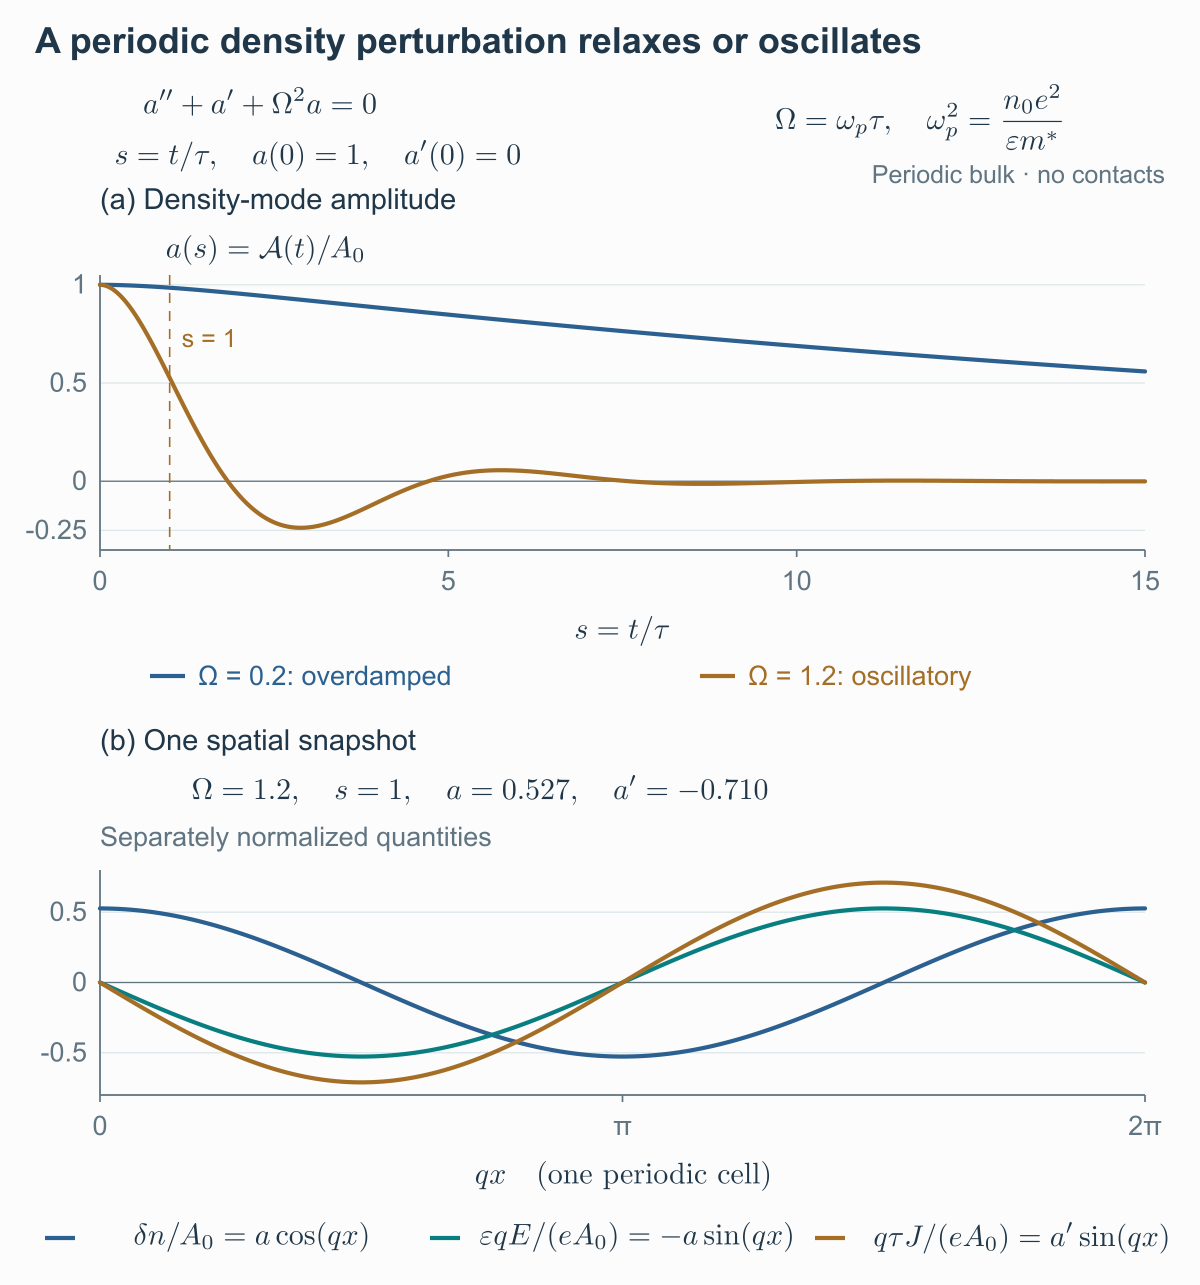

*그림 19. $\Omega=0.2$와 $1.2$ 모두 $a=1,a^{\prime}=0$에서 출발한다. (b)는 (a)에 표시한 $\Omega=1.2,s=1$일 때의 공간 분포다. 이때 $a\simeq0.52664$, $a^{\prime}\simeq-0.71020$이다. $A_0=\mathcal A(0)$는 초기 밀도 변화의 진폭이다. 밀도 변화, 전기장, 전류를 각각 $A_0$, $eA_0/(\varepsilon q)$, $eA_0/(q\tau)$로 나눴으므로 곡선의 높이만으로 세 물리량의 실제 크기를 비교할 수는 없다. 전기장과 전류는 같은 밀도 분포에서 구했으며 Poisson equation과 continuity equation을 만족한다. 주기적 경계 조건을 썼고, 압력과 contact 및 외부 단자 전압은 고려하지 않았다.*



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-charge)


$\Omega=0.5$를 기준으로 값을 양쪽으로 바꿔 보자. 한쪽에서는 밀도 차이가 진동 없이 줄고, 다른 쪽에서는 균일한 상태를 지나쳐 부호가 바뀐다. 이 예제는 $\tau=100\,\mathrm{fs}$, $m^{\ast}=0.2m_0$, $\varepsilon_b=11.7$, $L_{\rm cell}=100\,\mathrm{nm}$를 고정한다. $\Omega$를 바꾸면 $\omega_p^2=n_0e^2/(\varepsilon m^{\ast})$에 따라 기준 밀도 $n_0$가 바뀌고, 초기 밀도 차이는 그 밀도의 5%로 정한다. 밀도, 전기장, 전류는 각각 물리 단위의 고정 축에 따로 그렸다. 처음에는 밀도 차이로 전기장이 생겨도 전류는 0일 수 있다.

평균 drift의 relaxation이 밀도 변화보다 훨씬 빠르면, 밀도가 천천히 바뀌는 동안 전류가 국소 전기장의 DC 응답을 거의 따라간다고 볼 수 있다. 파장이 길다는 이유만으로 관성에 따른 초기 변화가 사라지는 것은 아니다.



**더 간단한 charge-relaxation time epsilon/sigma는 언제 유효할까?**


밀도가 변하는 시간 척도에서 관성을 무시할 수 있다면 charge continuity equation에 $\mathbf J=\sigma_0\mathbf E$를 대입한다. $\sigma_0$와 $\varepsilon$이 공간적으로 균일하면

$$
\begin{aligned}
&\partial_t\rho=-\frac{\sigma_0}{\varepsilon}\rho,\\
&\tau_M=\frac{\varepsilon}{\sigma_0}
=\frac{1}{\omega_p^2\tau}.
\end{aligned}
\tag{65}
$$

이 **Maxwell charge-relaxation time**은 momentum relaxation time과 다르다. $\omega_p\tau\ll1$이면 식 (61)의 해에서 관성에 따른 빠른 성분이 먼저 사라지고, 밀도 변화는 이 시간 척도로 천천히 줄어든다. 이 극한에서 실제 시간에 대한 두 감쇠 지수는 대략 $-\omega_p^2\tau$와 $-1/\tau$다. 진동하며 감쇠하는 영역에 순간적인 Ohm 법칙을 적용하면 진동을 놓치게 된다. [Haus and Melcher, Sec. 7.7](https://web.mit.edu/6.013_book/www/chapter7/7.7.html)



## 20. 연습문제: 전기장·band curvature·scattering rate



[Interactive example 열기](https://pilkwangkim.github.io/posts/Drude-Model-From-Scratch-KR/#lab-drude-quiz)


문제를 풀 때 먼저 무엇을 고정했는지 확인하자. 같은 전압에서 도선을 늘리는 것과 같은 전기장에서 늘리는 것은 결과가 다르다. 마찬가지로 elastic scattering에서 각도가 바뀌는 것과 전자가 에너지를 잃는 산란이 추가되는 것은 다른 문제다. 마지막 문제는 notebook에서 함수를 작성하고 테스트할 수 있다.

### 1. 같은 전압에서 도선이 길어지면

밀도가 균일하고 charge neutrality를 만족하는 도선에서 $V,A,n,m^{\ast},\tau$를 그대로 두고 길이 $L$만 두 배로 늘리자. 전기장, 전류, mobility, bulk charge density는 각각 어떻게 달라질까? Continuity equation에 따르면 두 도선의 전류도 같아야 할까?



**정답**


전기장과 전류는 절반으로 줄고 저항은 두 배가 된다. 물질의 transport parameter를 그대로 뒀으므로 mobility는 바뀌지 않는다. 두 도선 모두 전기장이 일정해 divergence가 0이므로 bulk charge density도 0이다. Continuity equation이 요구하는 것은 **한 도선 안에서** steady-state 전류가 어디서나 같다는 조건이다. 경계 조건이 다른 두 도선의 전류까지 같아야 한다는 뜻은 아니다.



### 2. Packet은 움직이지만 그 순간 속도는 변하지 않는 경우

Cosine band에서 중심 wavevector가 $ka=\pi/2$를 만족하고 wavevector 분포가 좁은 packet을 생각하자. Packet의 중심은 움직이고 있지만, 작고 일정한 외력을 가해도 그 순간에는 중심 속도가 변하지 않을 수 있다. 왜 그럴까? 이 지점에 band-edge mass를 써도 될까?



**정답**


이 지점에서 에너지의 1차 미분은 최대지만 2차 미분은 0이다. 따라서 식 (18)로 구한 중심 속도는 0이 아니어도 식 (19)로 구한 가속도는 0이다. Band minimum에서 이만큼 멀어지면 band edge의 quadratic 근사를 쓸 수 없다. 외력으로 $k$가 달라지면 curvature도 달라지므로, 이 semiclassical 근사에서 가속도가 0이라는 결과는 그 순간에만 해당한다.



### 3. Event rate는 같아도 전류 relaxation은 다르다

모든 입사 방향에 같은 규칙이 적용되는 고정 에너지 모델을 생각하자. Elastic scattering은 이전 산란 이력과 무관하게 $5\times10^{12}\,\mathrm{s}^{-1}$의 일정한 rate로 일어난다. 한 번 산란할 때 진행 방향은 $60^\circ$ 꺾이고, 기존 진행 방향을 축으로 한 방위각은 균일하게 분포한다. $\tau_q$와 $\tau_{\rm tr}$는 얼마일까? 어느 쪽이 전자 기체의 냉각 시간을 알려 줄까?



**정답**


산란율의 역수는 $\tau_q=0.2\,\mathrm{ps}$다. $1-\cos60^\circ=1/2$이므로 transport rate는 event rate의 절반이고 $\tau_{\rm tr}=0.4\,\mathrm{ps}$다. 이 산란에서는 전자의 에너지가 보존되므로 어느 쪽도 전자 기체의 냉각 시간은 아니다.



### 4. 전류가 생기기 전에도 전기장은 있다

앞의 periodic bulk mode에서 공간 평균 전기장은 0으로 두자. 초기 밀도 변화가 $\delta n(x,0)=\mathcal A_0\cos qx$, $\mathcal A_0>0$이고 처음에는 drift가 없다. $\sin qx>0$인 위치에서 $E$, 초기 $J$, 초기 $\partial_tJ$의 부호는 각각 무엇일까? 전자와 전류가 향하는 방향이 다르다는 점을 고려하고, continuity equation에도 맞는지 확인하자.



**정답**


전기장은 음수다. 처음에는 $J=0$이지만 $\partial_tJ=(n_0e^2/m^{\ast})E<0$이다. 전자는 양의 $x$ 방향으로 움직이기 시작하므로 전류는 음의 $x$ 방향으로 생긴다. 이때 $\partial_t\rho+\partial_xJ=0$이어서 전하는 보존된다. 밀도의 초기 시간 미분은 0이지만, 두 번째 시간 미분은 밀도 차이를 줄이는 방향이다.



### 5. Coding test: event rate와 transport rate

**입력.** 길이가 같은 두 1차원 NumPy 배열을 받는다. `rate_weights[i]`는 입체각 적분의 가중치까지 곱한 각도 구간 `i`의 rate다. `cos_theta[i]`는 그 구간의 산란 각도에 대한 cosine이다. 모든 입력값은 유한하고, rate는 음수가 아니며 cosine은 $[-1,1]$ 범위에 있다.

**출력.** 단위가 초의 역수인 두 rate를 `[Gamma_q, Gamma_tr]` 순서로 담은 새 배열을 반환한다. Rate를 정규화하면 전체 산란 빈도를 잃으므로 입력값 그대로 더한다. 입력 배열은 수정하지 않는다. Lifetime 대신 rate를 반환하므로 산란이 없거나 방향이 전혀 바뀌지 않아도 0으로 나눌 일이 없다.

`rate_weights=[4,6]`, `cos_theta=[1,0]`이면 답은 `[10,6]`이다. 첫 번째 구간에는 진행 방향을 그대로 유지하는 입력을 넣었다. 이 값은 입력 rate의 단순 합에는 포함되지만 transport rate에는 기여하지 않는다. 11절의 quantum transition에서는 처음 상태와 같은 상태를 최종 상태에서 제외했다. 따라서 이 테스트의 단순 합을 물리적인 quantum out-scattering rate로 해석하지 않는다. `[8]`, `[-1]`이면 진행 방향이 완전히 뒤집혀 가중치가 2가 되므로 답은 `[8,16]`이다.


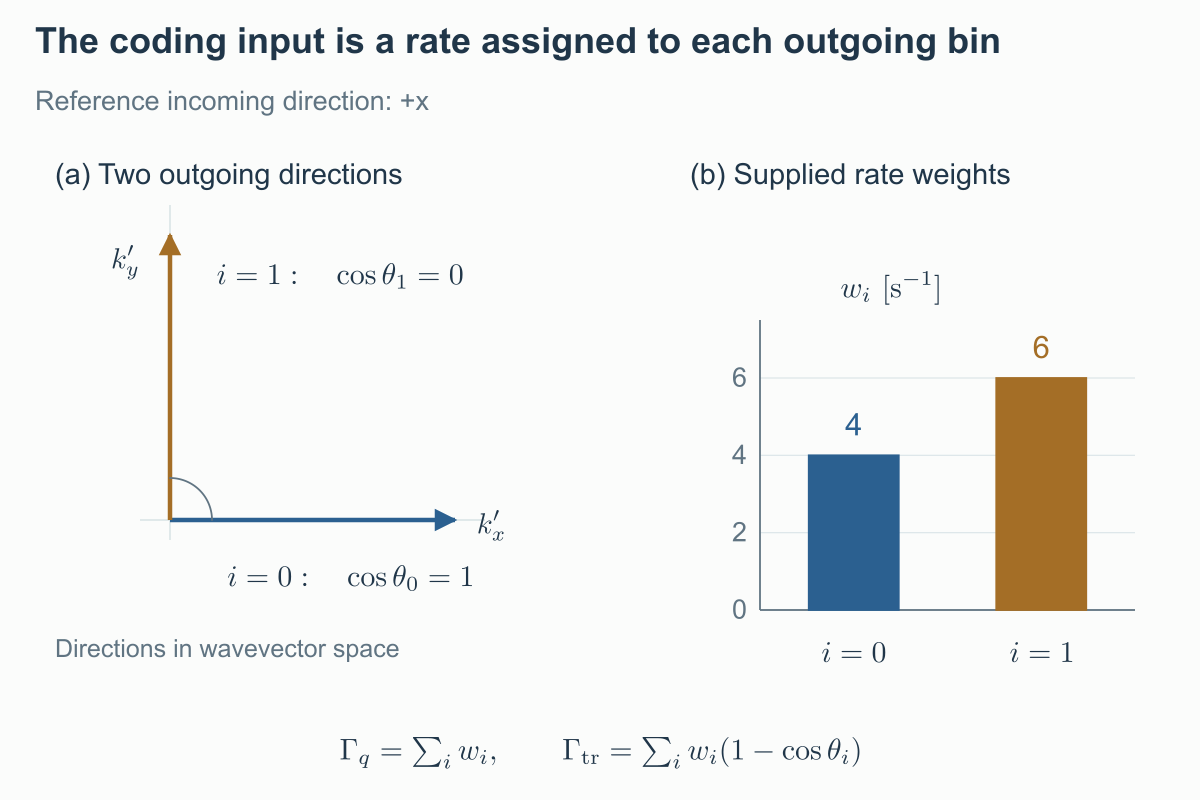

*그림 20. 가로축의 양의 방향이 전자가 들어오는 방향이다. 나가는 방향을 그대로 유지하는 구간과 직각으로 꺾이는 구간을 두고, 각각의 rate를 막대로 그렸다. 막대의 값에 입체각 적분의 가중치가 이미 들어 있으므로 다시 정규화하지 않고 합한다. 진행 방향이 그대로인 첫 번째 구간은 테스트용이며, 다른 quantum state로의 transition을 뜻하지 않는다.*


In [15]:
def angular_relaxation_rates(rate_weights, cos_theta):
    # Return [event rate, transport rate] without changing either input.
    raise NotImplementedError("Implement the angular sums in Eq. (40)")

def check_angular_rates(candidate):
    cases = [([4., 6.], [1., 0.]), ([8.], [-1.]),
             ([0., 0.], [-1., 1.]), ([2., 3., 5.], [0.8, -0.4, 0.0])]
    for rates, cosines in cases:
        rates, cosines = np.array(rates), np.array(cosines)
        before_r, before_c = rates.copy(), cosines.copy()
        expected = np.array([before_r.sum(), np.dot(before_r, 1 - before_c)])
        actual = np.asarray(candidate(rates, cosines))
        assert np.array_equal(rates, before_r), "Rate input was mutated"
        assert np.array_equal(cosines, before_c), "Angle input was mutated"
        assert actual.shape == (2,) and np.allclose(actual, expected)
        assert not any(np.shares_memory(actual, a) for a in (rates, cosines)), "Return a new array"
        assert 0 <= actual[1] <= 2 * actual[0] + 1e-12
    return "4 cases passed"

# After implementing your answer, uncomment:
# print(check_angular_rates(angular_relaxation_rates))


**Reference solution과 lifetime 비의 범위**


In [16]:
def angular_relaxation_rates_reference(rate_weights, cos_theta):
    rates = np.asarray(rate_weights, dtype=float)
    cosines = np.asarray(cos_theta, dtype=float)
    return np.array([np.sum(rates), np.sum(rates * (1 - cosines))])

print(check_angular_rates(angular_relaxation_rates_reference))


4 cases passed


$1-\cos\theta$는 모든 산란 각도에서 0 이상 2 이하이므로 $0\le\Gamma_{\rm tr}\le2\Gamma_q$다. 두 rate가 모두 양수이고 유한하면 $\tau_{\rm tr}/\tau_q\ge1/2$다. 산란이 forward 방향에 몰리면 이 비는 한없이 커질 수 있다. 반대로 모든 방향의 입체각당 산란율이 같은 경우 두 시간의 비는 1이다.

작성할 함수와 reference solution의 이름이 다르므로 notebook을 실행해도 작성한 답을 덮어쓰지 않는다. Checker는 두 rate가 맞는지, 입력 배열을 그대로 뒀는지, transport rate가 허용 범위에 있는지를 검사한다.



도선의 저항을 알려면 먼저 전기장을 구하고 그 전기장이 만드는 전류를 계산해야 한다. 전기장은 Poisson equation과 경계 조건으로 정해지며, bulk charge density가 0이어도 전류를 일으키는 전기장은 있을 수 있다. Continuity equation은 전류가 공간에 따라 달라질 때 어디에 전하가 쌓이는지 알려 준다. 전자의 dispersion은 전자가 얼마나 빨리 움직이고 외력에 어떻게 반응하는지를 정한다. 산란율은 transition matrix element와 가능한 최종 상태의 수로 구하되, 전류가 얼마나 빨리 줄어드는지를 알려면 산란 각도도 가중치에 넣어야 한다. 이 관계들을 약한 전기장에서 결합한 결과가 mobility와 conductivity다. 물질이나 산란 방식이 바뀌면 $ne^2\tau/m^{\ast}$에 들어가는 숫자 하나만 바꿔서는 새 전류를 설명하지 못할 수 있다.

## 참고문헌과 추가 구현


- H. A. Haus and J. R. Melcher, [*Electromagnetic Fields and Energy*, Chapter 7](https://web.mit.edu/6.013_book/www/chapter7/7.html) 및 [Section 7.7](https://web.mit.edu/6.013_book/www/chapter7/7.7.html). 전하 보존, 전도, electroquasistatic charge relaxation.
- TU Delft, [*Open Solid State Notes*: Drude model](https://solidstate.quantumtinkerer.tudelft.nl/3_drude_model/). 평균 속도의 운동 방정식에서 conductivity와 mobility의 관계를 유도한다. 본문의 각도 산란 모델은 이를 바탕으로 event time과 transport time을 구분한다.
- D. Tong, [*Electromagnetism*, Sections 7.6.1–7.6.3](https://www.damtp.cam.ac.uk/user/tong/em/el6.pdf). Drude AC response, dielectric response, plasma oscillation.
- D. Tong, [*Solid State Physics*, Chapter 2](https://davidtong.org/pdfs/teaching/solid-state-physics/solidstate2.pdf) 및 [Chapter 3, Section 3.2](https://davidtong.org/pdfs/teaching/solid-state-physics/solidstate3.pdf). Bloch state, tight binding, group velocity, inverse-effective-mass tensor, Bloch oscillation.
- R. Fitzpatrick, [Ehrenfest's Theorem](https://farside.ph.utexas.edu/teaching/qmech/lectures/node36.html). 위치와 momentum의 기댓값이 전체 힘에 따라 어떻게 변하는지, packet 중심의 운동에 고전 근사를 적용할 수 있는 조건은 무엇인지 설명한다.
- B. Zwiebach, MIT 8.06, [Chapter 4: Time-Dependent Perturbation Theory, Section 4.3.1](https://ocw.mit.edu/courses/8-06-quantum-physics-iii-spring-2018/89ef6d5958ee59bae9a91345c3d8c8e4_MIT8_06S18ch4.pdf) (2018). 유한 시간에서 구한 transition amplitude가 연속적인 최종 상태에 대해 golden rule로 이어지는 과정을 설명한다. MIT 8.321의 [Lecture 26](https://ocw.mit.edu/courses/8-321-quantum-theory-i-fall-2017/81f6e90a6cdd311ca5f3afb32e9da1f2_MIT8_321F17_lec26.pdf) (2017)도 참고할 수 있다.
- B. Zwiebach, MIT 8.06, [Chapter 7: Scattering, Section 7.3](https://ocw.mit.edu/courses/8-06-quantum-physics-iii-spring-2018/45dbd7038c3e969491eceeae86c44d42_MIT8_06S18ch7.pdf) (2018); D. Tong, [*Topics in Quantum Mechanics*, Chapter 6, Sections 6.2–6.3](https://davidtong.org/pdfs/teaching/topics-in-quantum-mechanics/topicsinqm6.pdf). Cross section, Born approximation, screened Coulomb scattering.
- S. Kim, S. Woo and H. Min, [“Vertex corrections to the dc conductivity in anisotropic multiband systems”](https://arxiv.org/html/1901.04135v2), *Physical Review B* **99**, 165107 (2019), DOI: 10.1103/PhysRevB.99.165107. 각도에 따른 transport 가중치를 쓸 수 있는 조건과, scalar relaxation time으로는 부족한 경우를 다룬다.
- J. Bardeen and W. Shockley, [“Deformation Potentials and Mobilities in Non-Polar Crystals”](https://doi.org/10.1103/PhysRev.80.72), *Physical Review* **80**, 72–80 (1950), DOI: 10.1103/PhysRev.80.72.
- MIT 6.730, [*Physics for Solid-State Applications*, lecture notes](https://ocw.mit.edu/courses/6-730-physics-for-solid-state-applications-spring-2003/pages/lecture-notes/) (2003). Effective mass와 electron–phonon scattering의 유도.
- F. Giustino, [“Electron-phonon interactions from first principles”](https://doi.org/10.1103/RevModPhys.89.015003), *Reviews of Modern Physics* **89**, 015003 (2017), DOI: 10.1103/RevModPhys.89.015003; [Erratum](https://doi.org/10.1103/RevModPhys.91.019901), **91**, 019901 (2019). Matrix element, quasiparticle lifetime, transport. 전류와 kinetic equation은 정정된 식을 사용해야 한다.
- [EPW documentation](https://docs.epw-code.org/)과 [source repository](https://gitlab.com/epw/q-e/-/tree/develop/EPW). 하나의 scalar relaxation time을 쓰는 예제와 달리, first-principles electron–phonon 및 transport 계산을 구현한다.
- [NIST CODATA constants](https://physics.nist.gov/cuu/Constants/Table/allascii.txt). 실행 코드에 사용한 SI 상수와 전자 질량.
